# 01 · Dataset Generation & Validation
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

Notebook ini **membangkitkan seluruh data sintetis** proyek dan **membuktikan bahwa data itu valid** sebelum dipakai untuk analisis dan pemodelan.

| # | Notebook | Isi |
|---|---|---|
| **01** | **Dataset Generation & Validation** | **notebook ini** |
| 02 | EDA | eksplorasi & temuan bisnis |
| 03 | Feature Engineering | feature store, uji nilai fitur |
| 04 | Modelling | model dasar risiko, peluang, anomali |
| 05 | Modelling Optimization | tuning, cost-sensitive, kalibrasi |
| 06 | Model Evaluation | evaluasi terhadap ground truth & biaya bisnis |
| 07 | Post-evaluation & Remodelling | perbaikan berdasarkan analisis kesalahan |

## Mengapa data sintetis, dan mengapa harus divalidasi?
Pedoman capstone melarang data internal/rahasia dan data pribadi, sehingga seluruh data dibangkitkan. Risikonya: data sintetis yang dibuat asal acak akan membuat EDA tidak menemukan apa-apa, atau sebaliknya membuat model terlihat hebat karena polanya terlalu mudah. Karena itu notebook ini memegang lima prinsip:

1. **Dunia kausal, bukan kolom acak.** Setiap perusahaan punya kondisi tersembunyi (kesehatan, pertumbuhan, kejadian, kebutuhan produk); semua tabel diturunkan dari kondisi itu, sehingga antartabel konsisten.
2. **Ada kebenaran (*ground truth*) untuk setiap tugas.** File `gt_*` menyimpan jawaban sebenarnya (risiko, anomali, kebutuhan produk, identitas counterparty) — dipakai **hanya untuk evaluasi**.
3. **Pola bisnis ditanam secara terukur** agar EDA, feature engineering, dan analisis graf punya sesuatu yang bermakna untuk ditemukan — tetapi dengan derau, sehingga tidak trivial.
4. **Anti-kebocoran sejak desain.** Data fitur berhenti di **30 Jun 2026**; hasil (adopsi produk) baru terjadi **Jul–Sep 2026**; label proxy diberi tanda.
5. **Validasi berlapis dengan rujukan paper** (bagian F) — 7 lapis, dari integritas sampai privasi, ditambah uji statistik jaringan (F2b) dan uji signifikansi (F8).

**Daftar isi:** A. Konfigurasi · B. Desain kausal · C. Tabel referensi · D. Pembangkitan 18 tahap · E. Simpan & kamus data · F. Validasi 7 lapis + F2b & F8 · G. Ringkasan · H. Ekspor daftar rujukan · Daftar pustaka

## A. Konfigurasi
Semua angka yang menentukan "dunia" dikumpulkan di satu tempat agar bisa diubah dan diuji sensitivitasnya (bagian F3).

**Input & output notebook ini** (path relatif terhadap akar proyek):

| | Lokasi | Isi |
|---|---|---|
| Input | — | tidak ada; seluruh data dibangkitkan dari `CFG` + `SEED` |
| Output | `data/raw/` | 27 CSV, `data_dictionary.csv`, `generator_config.json`, `DATASHEET.md` → dibaca notebook 02–07 |
| Output | `outputs/01_dataset_validation/` | `validation_report.csv` (hasil validasi 7 lapis, dengan kolom `tautan` ke rujukan) |
| Output | `outputs/01_dataset_validation/` | `network_tests.csv` (uji statistik jaringan F2b) |
| Output | `outputs/01_dataset_validation/` | `significance_tests.csv` (uji signifikansi F8) |
| Output | `outputs/01_dataset_validation/` | `references.csv` + `REFERENCES.md` (daftar rujukan dengan DOI/URL & uji yang memakainya) |
| Output | `outputs/01_dataset_validation/figures/` | grafik bagian B, C, F, G (.png) |

Generator yang sama tersedia sebagai modul di `src/egi_generator.py`.

In [1]:
# [gen]
import json, os, re, time, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

CFG = dict(
    n_core=2000, n_credit=1000, n_noncredit=400,             # 2.000 perusahaan inti: 1.000 nasabah kredit, 400 nasabah non-kredit, 600 prospect
    n_ent_l1=3000, n_ent_l2=1800,                            # mitra bisnis di luar perusahaan inti (lapis 1 & 2)
    months=pd.period_range('2024-01', '2026-06', freq='M'),  # 30 bulan data fitur; cutoff 30 Jun 2026
    outcome_window=('2026-07', '2026-09'),                   # hasil yang diprediksi — terjadi SETELAH cutoff
    risk_quantiles=(0.57, 0.82),                             # ambang Low | Medium | High pada kondisi normal
    sigma_unobserved=0.25,                                   # faktor risiko yang tidak terekam data (batas akurasi alami)
    label_error_rate=0.04,                                   # kesalahan rating oleh analis (dicatat di ground truth)
    health_shift=0.0,                                        # < 0 = krisis, > 0 = ekonomi membaik (uji kondisi ekstrem)
    group_frac=0.08,                                         # porsi perusahaan inti yang tergabung dalam grup usaha
    gravity_km=8.0,                                          # skala jarak: mitra dagang cenderung berdekatan
    gravity_floor=0.03,                                      # peluang dasar bermitra jauh
    city_boost=3.0,                                          # pengali bila mitra satu kota/kabupaten (klaster industri)
    new_edge_rate=0.07,                                      # porsi relasi dagang yang baru dimulai dalam periode data
    n_actions_deepening=1500, n_actions_acq=500, max_visit_notes=450,
    dq=dict(dup_tx=0.003, zero_tx=0.0001, nan_channel=0.005, nan_cp=0.01, nan_ebit=0.012),   # masalah kualitas data yang disengaja
)
SEED = 2026
# Lokasi file — dicari dari akar proyek (folder yang berisi pyproject.toml), jadi notebook bisa dijalankan dari folder mana pun
from pathlib import Path
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists()), Path.cwd())
OUT = PROJECT_ROOT / 'data' / 'raw'                           # OUTPUT dataset: 27 CSV + kamus data + config + datasheet → INPUT notebook 02–07
REPORT = PROJECT_ROOT / 'outputs' / '01_dataset_validation'   # OUTPUT validasi: validation_report.csv
FIG = REPORT / 'figures'                                      # OUTPUT grafik notebook ini (.png)
CUTOFF = '2026-06-30'


class World(dict):
    """Wadah semua variabel dunia sintetis; tiap tahap membaca input & menulis output ke sini."""
    __getattr__ = dict.__getitem__
    def put(self, **kw): self.update(kw)
    def get_(self, names): return [self[n] for n in names.split()]

## B. Desain kausal
Data dibangkitkan dengan pendekatan *structural causal model* (Pearl, 2009): variabel tersembunyi menjadi **penyebab**, tabel yang terlihat bank menjadi **akibat**. Keuntungannya:
- **Konsisten antartabel** — perusahaan yang sedang tertekan akan terlihat tertekan di laporan keuangan, transaksi, utilisasi kredit, dan catatan kunjungan sekaligus.
- **Bisa dievaluasi** — karena penyebabnya diketahui, kita tahu jawaban yang benar.
- **Bisa diuji sensitivitasnya** — ubah satu parameter (misal kondisi krisis), lalu lihat apakah akibatnya masuk akal (bagian F3; Sargent, 2013).

Diagram di bawah: kotak biru = kondisi tersembunyi, kotak oranye = data yang terlihat bank, kotak abu-abu = ground truth / hasil (hanya evaluasi).

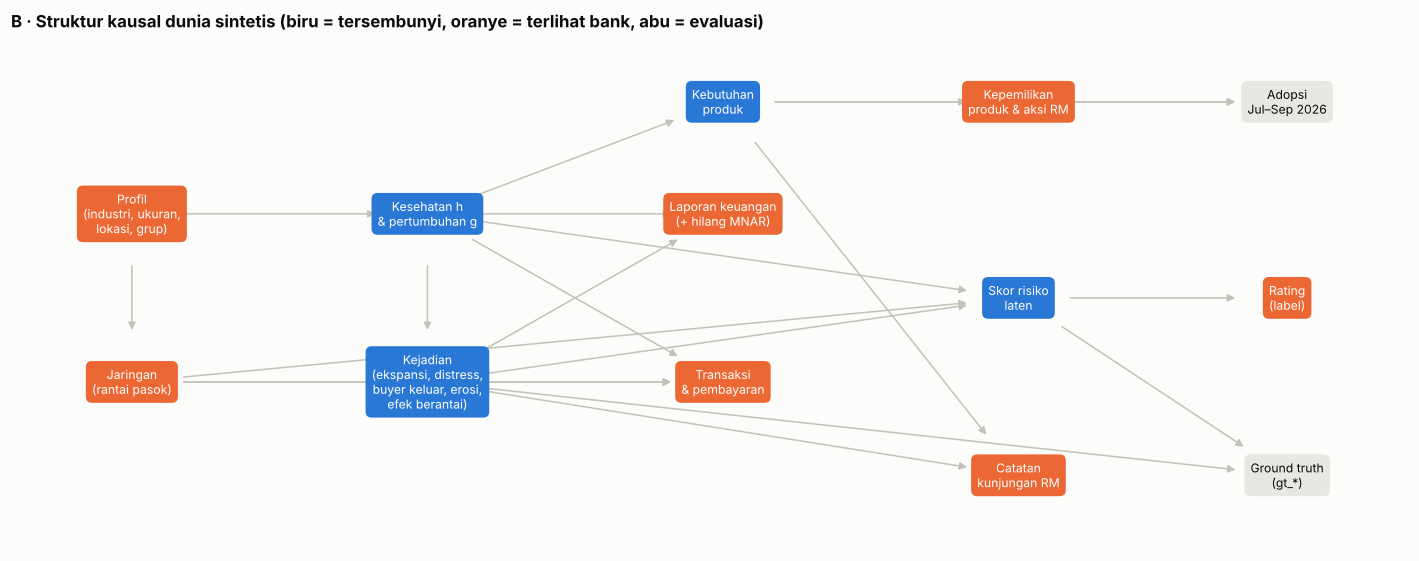

In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
STATUS = {'LOLOS': '#0ca30c', 'GAGAL': '#d03b3b', 'info': '#898781'}
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})


def save_fig(name):
    """Simpan grafik aktif ke outputs/01_dataset_validation/figures/<name>.png."""
    FIG.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')

nodes = {  # nama: (x, y, jenis)
    'Profil\n(industri, ukuran,\nlokasi, grup)': (0, 3, 'obs'), 'Kesehatan h\n& pertumbuhan g': (2.2, 3, 'lat'), 'Jaringan\n(rantai pasok)': (0, 1.2, 'obs'),
    'Kejadian\n(ekspansi, distress,\nbuyer keluar, erosi,\nefek berantai)': (2.2, 1.2, 'lat'), 'Kebutuhan\nproduk': (4.4, 4.2, 'lat'),
    'Laporan keuangan\n(+ hilang MNAR)': (4.4, 3, 'obs'), 'Transaksi\n& pembayaran': (4.4, 1.2, 'obs'), 'Skor risiko\nlaten': (6.6, 2.1, 'lat'),
    'Rating\n(label)': (8.6, 2.1, 'obs'), 'Kepemilikan\nproduk & aksi RM': (6.6, 4.2, 'obs'), 'Catatan\nkunjungan RM': (6.6, 0.2, 'obs'),
    'Adopsi\nJul–Sep 2026': (8.6, 4.2, 'gt'), 'Ground truth\n(gt_*)': (8.6, 0.2, 'gt')}
edges = [(0, 1), (0, 2), (1, 3), (2, 3), (1, 4), (1, 5), (3, 5), (3, 6), (1, 6), (2, 6), (1, 7), (3, 7), (2, 7), (7, 8), (4, 9), (9, 11), (4, 11),
         (3, 10), (4, 10), (7, 12), (3, 12)]
names_ = list(nodes)
fig, ax = plt.subplots(figsize=(13, 5.2)); ax.axis('off')
col = {'lat': C['s1'], 'obs': C['s2'], 'gt': C['muted']}
for a, b in edges:
    (x1, y1, _), (x2, y2, _) = nodes[names_[a]], nodes[names_[b]]
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='-|>', color=C['axis'], lw=1, shrinkA=34, shrinkB=34))
for n, (x, y, k) in nodes.items():
    ax.text(x, y, n, ha='center', va='center', fontsize=8, color='white' if k != 'gt' else C['ink'],
            bbox=dict(boxstyle='round,pad=0.5', fc=col[k] if k != 'gt' else '#e8e7e1', ec='none'))
ax.set_xlim(-0.9, 9.5); ax.set_ylim(-0.6, 4.9); ax.set_title('B · Struktur kausal dunia sintetis (biru = tersembunyi, oranye = terlihat bank, abu = evaluasi)')
plt.tight_layout(); save_fig('01_B_struktur_kausal'); plt.show()

## C. Tabel referensi
Konstanta yang membentuk dunia: 40 kecamatan Jabodetabek, 10 industri (kode KBLI 2020, BPS), level rasio keuangan struktural per industri, pola musiman, tanggal Lebaran, dan katalog produk. Nilainya **ilustratif dan dikalibrasi agar wajar**, bukan disalin dari data riil.

| Konstanta | Isi | Dasar |
|---|---|---|
| `GEO` | 40 kecamatan: koordinat pusat, luas, jumlah kawasan industri | peta administrasi Jabodetabek (koordinat perkiraan) |
| `IND` / `INDF` | bobot industri, efek risiko, peluang impor, amplitudo Lebaran, kebutuhan modal kerja & capex | KBLI 2020; pola umum sektor |
| `IND_LEVEL`, `SIZE_LEVEL` | level DER / current ratio / margin "normal" per industri & ukuran — sengaja **tidak sejalan** dengan risiko industri | praktik analisis kredit: rasio dibandingkan dengan peer |
| `IND_MONTH`, `LEBARAN` | musiman per industri & intensitas Lebaran (Idulfitri 10 Apr 2024, 31 Mar 2025, 20 Mar 2026) | kalender resmi Kemenag |
| `VALUE_CHAIN` | siapa menjual ke siapa antarindustri (matriks input–output sederhana) | logika Tabel Input–Output BPS |
| `WHITE_SPACE` | 6 kecamatan kawasan industri dengan penetrasi BNI rendah & tanpa cabang | pola yang ditanam untuk analisis white-space |

In [3]:
# [gen]
WHITE_SPACE = ['L017', 'L018', 'L027', 'L028', 'L036', 'L040']   # kecamatan industri padat, penetrasi BNI rendah, tanpa cabang

GEO = [('L001', 'DKI Jakarta', 'Jakarta Pusat', 'Gambir', -6.19983, 106.83722, 21.9, 2), ('L002', 'DKI Jakarta', 'Jakarta Pusat', 'Tanah Abang', -6.18669, 106.82322, 38.9, 4), ('L003', 'DKI Jakarta', 'Jakarta Pusat', 'Menteng', -6.16629, 106.82609, 13.7, 1), ('L004', 'DKI Jakarta', 'Jakarta Pusat', 'Senen', -6.16395, 106.88474, 12.6, 1), ('L005', 'DKI Jakarta', 'Jakarta Pusat', 'Kemayoran', -6.20924, 106.87054, 17.7, 2), ('L006', 'DKI Jakarta', 'Jakarta Pusat', 'Sawah Besar', -6.16734, 106.8563, 14.9, 1), ('L007', 'DKI Jakarta', 'Jakarta Selatan', 'Kebayoran Baru', -6.25515, 106.83159, 30.9, 2), ('L008', 'DKI Jakarta', 'Jakarta Selatan', 'Setiabudi', -6.24932, 106.79009, 25.6, 0), ('L009', 'DKI Jakarta', 'Jakarta Selatan', 'Tebet', -6.27726, 106.81851, 17.1, 2), ('L010', 'DKI Jakarta', 'Jakarta Selatan', 'Cilandak', -6.29421, 106.76707, 16.7, 5), ('L011', 'DKI Jakarta', 'Jakarta Selatan', 'Pasar Minggu', -6.21364, 106.79251, 16.1, 1), ('L012', 'DKI Jakarta', 'Jakarta Selatan', 'Mampang Prapatan', -6.27443, 106.85582, 22.7, 3), ('L013', 'DKI Jakarta', 'Jakarta Selatan', 'Pancoran', -6.30085, 106.79008, 27.7, 2), ('L014', 'DKI Jakarta', 'Jakarta Selatan', 'Kebayoran Lama', -6.30204, 106.81352, 26.9, 1), ('L015', 'DKI Jakarta', 'Jakarta Utara', 'Penjaringan', -6.15617, 106.82128, 27.4, 4), ('L016', 'DKI Jakarta', 'Jakarta Utara', 'Tanjung Priok', -6.1013, 106.85594, 13.9, 5), ('L017', 'DKI Jakarta', 'Jakarta Utara', 'Koja', -6.11848, 106.91356, 22.1, 10), ('L018', 'DKI Jakarta', 'Jakarta Utara', 'Cilincing', -6.07734, 106.9054, 38.8, 3), ('L019', 'DKI Jakarta', 'Jakarta Utara', 'Kelapa Gading', -6.12457, 106.85153, 25.9, 6), ('L020', 'DKI Jakarta', 'Jakarta Utara', 'Pademangan', -6.16566, 106.8664, 18.4, 3), ('L021', 'DKI Jakarta', 'Jakarta Barat', 'Grogol Petamburan', -6.19355, 106.82991, 25.3, 0), ('L022', 'DKI Jakarta', 'Jakarta Barat', 'Kebon Jeruk', -6.13512, 106.76064, 33.6, 4), ('L023', 'DKI Jakarta', 'Jakarta Barat', 'Cengkareng', -6.16892, 106.80768, 8.7, 1), ('L024', 'DKI Jakarta', 'Jakarta Barat', 'Kalideres', -6.14225, 106.77266, 27.8, 2), ('L025', 'DKI Jakarta', 'Jakarta Barat', 'Tambora', -6.14166, 106.76672, 28.2, 2), ('L026', 'DKI Jakarta', 'Jakarta Barat', 'Palmerah', -6.20648, 106.76112, 35.9, 2), ('L027', 'DKI Jakarta', 'Jakarta Timur', 'Cakung', -6.2291, 106.90473, 37.3, 10), ('L028', 'DKI Jakarta', 'Jakarta Timur', 'Pulo Gadung', -6.24653, 106.88142, 25.4, 9), ('L029', 'DKI Jakarta', 'Jakarta Timur', 'Jatinegara', -6.23535, 106.94869, 8.6, 7), ('L030', 'DKI Jakarta', 'Jakarta Timur', 'Duren Sawit', -6.25806, 106.86639, 39.6, 5), ('L031', 'DKI Jakarta', 'Jakarta Timur', 'Kramat Jati', -6.22984, 106.90519, 7.6, 3), ('L032', 'DKI Jakarta', 'Jakarta Timur', 'Pasar Rebo', -6.27414, 106.84512, 20.0, 9), ('L033', 'Jawa Barat', 'Kota Bekasi', 'Bekasi Barat', -6.25241, 106.98266, 20.6, 5), ('L034', 'Jawa Barat', 'Kota Bekasi', 'Bekasi Timur', -6.23569, 106.99172, 16.9, 3), ('L035', 'Jawa Barat', 'Kota Bekasi', 'Bekasi Utara', -6.21761, 106.98639, 36.1, 3), ('L036', 'Jawa Barat', 'Kota Bekasi', 'Medan Satria', -6.21289, 107.03807, 19.0, 10), ('L037', 'Banten', 'Kota Tangerang', 'Tangerang', -6.17782, 106.65617, 21.8, 8), ('L038', 'Banten', 'Kota Tangerang', 'Karawaci', -6.16857, 106.64139, 30.8, 3), ('L039', 'Banten', 'Kota Tangerang', 'Cipondoh', -6.25251, 106.61809, 23.5, 8), ('L040', 'Banten', 'Kota Tangerang', 'Batuceper', -6.16094, 106.65712, 22.5, 5)]

# industri: (nama, kbli, bobot, efek risiko, p impor, amplitudo Lebaran, modal kerja, capex, ritel/VA, preferensi kawasan industri)
IND = [('Perdagangan besar', 46, 185, 0.05, 0.40, 0.30, 1, 0, 1, 0.3), ('Industri makanan & minuman', 10, 126, -0.05, 0.30, 0.40, 1, 1, 1, 1.0),
       ('Konstruksi gedung', 41, 121, 0.45, 0.15, 0.08, 1, 1, 0, 0.3), ('Perdagangan eceran', 47, 107, 0.15, 0.10, 0.45, 1, 0, 1, 0.0),
       ('Industri tekstil & pakaian', 13, 89, 0.35, 0.45, 0.35, 1, 1, 0, 1.0), ('Angkutan & logistik', 49, 86, 0.20, 0.10, 0.20, 0, 1, 0, 0.7),
       ('Aktivitas kesehatan', 86, 78, -0.30, 0.10, 0.05, 0, 1, 1, 0.0), ('Teknologi informasi', 62, 75, -0.10, 0.05, 0.05, 0, 0, 1, 0.0),
       ('Industri kimia', 20, 71, 0.10, 0.50, 0.10, 1, 1, 0, 1.0), ('Real estat', 68, 62, 0.40, 0.02, 0.05, 0, 1, 1, 0.0)]
INDF = pd.DataFrame(IND, columns=['industry', 'kbli', 'w', 'risk', 'p_import', 'season', 'wc', 'capex', 'va', 'ind_pref']).set_index('industry')
# Level rasio STRUKTURAL per industri (bukan sinyal risiko) → rasio mentah menyesatkan, rasio relatif-peer lebih informatif
IND_LEVEL = {  # (offset log DER, offset log CR, offset margin EBIT)
    # sengaja TIDAK sejalan dengan efek risiko industri: RS & logistik padat aset (DER tinggi) tapi risikonya rendah-sedang;
    # tekstil & eceran DER rendah tapi risikonya tinggi → rasio mentah menyesatkan, rasio relatif-peer tidak
    'Real estat': (0.55, 0.10, 0.06), 'Konstruksi gedung': (0.05, -0.20, -0.02), 'Perdagangan besar': (0.15, 0.05, -0.04), 'Perdagangan eceran': (-0.35, -0.30, -0.04),
    'Industri tekstil & pakaian': (-0.40, 0.15, -0.01), 'Angkutan & logistik': (0.60, -0.15, 0.01), 'Industri kimia': (0.30, 0.15, 0.02),
    'Industri makanan & minuman': (0.00, 0.00, 0.01), 'Aktivitas kesehatan': (0.65, -0.10, 0.05), 'Teknologi informasi': (-0.55, 0.40, 0.06)}
SIZE_LEVEL = {'Kecil': (-0.20, -0.12, -0.01), 'Menengah': (0.0, 0.0, 0.0), 'Besar': (0.30, 0.10, 0.01)}   # perusahaan besar lebih leverage (akses kredit)
# Profil musiman per industri (tambahan di luar Lebaran): bulan → efek
IND_MONTH = {'Konstruksi gedung': {12: 0.30, 1: -0.14, 2: -0.10}, 'Teknologi informasi': {12: 0.20, 1: -0.08}, 'Real estat': {12: 0.12, 6: 0.06},
             'Perdagangan eceran': {12: 0.12, 1: -0.06}, 'Industri makanan & minuman': {12: 0.08}, 'Aktivitas kesehatan': {}, 'Angkutan & logistik': {12: 0.10, 1: -0.05}}
LEBARAN = {'2024-03': 0.45, '2024-04': 0.75, '2025-03': 0.85, '2025-04': 0.35, '2026-02': 0.25, '2026-03': 1.0}   # Idulfitri 10 Apr 2024, 31 Mar 2025, 20 Mar 2026
SIZES = ['Kecil', 'Menengah', 'Besar']
REV_MED = {'Kecil': 8.0, 'Menengah': 32.0, 'Besar': 160.0}          # omzet median (Rp miliar)
EMP_PER_BN = {'Kecil': 4.5, 'Menengah': 3.0, 'Besar': 1.8}
PRODUCTS = [('P01', 'Giro', 'Funding'), ('P02', 'Deposito', 'Funding'), ('P03', 'Virtual Account', 'Transactional'), ('P04', 'Cash Management', 'Transactional'),
            ('P05', 'Payroll', 'Transactional'), ('P06', 'Kredit Modal Kerja', 'Lending'), ('P07', 'Kredit Investasi', 'Lending'), ('P08', 'Trade Finance', 'Trade')]
PIDS = [p[0] for p in PRODUCTS]
W1 = ['Maju', 'Sinar', 'Karya', 'Cahaya', 'Mega', 'Prima', 'Graha', 'Mitra', 'Surya', 'Bumi', 'Indo', 'Global', 'Bintang', 'Sentosa', 'Agung', 'Bahtera', 'Cipta', 'Dharma']
W2 = ['Sejahtera', 'Nusantara', 'Utama', 'Lestari', 'Gemilang', 'Mandiri', 'Perkasa', 'Abadi', 'Jaya', 'Kencana', 'Makmur', 'Santosa', 'Pratama', 'Raya']
W3 = ['Group', 'Indah', 'Sentral', 'Bersama', 'Persada', 'Investama', 'Industri', 'Niaga', 'Logistik', 'Teknik', 'Solusi', 'Internasional']
sig = lambda x: 1 / (1 + np.exp(-x))


def make_names(rng, n, prefix_pool=('PT', 'PT', 'PT', 'CV'), used=None):
    used = set() if used is None else used; out = []
    while len(out) < n:
        nm = f"{rng.choice(prefix_pool)} {rng.choice(W1)} {rng.choice(W2)} {rng.choice(W3)}"
        if rng.random() < 0.35: nm += f" {rng.choice(W2)}"
        if nm not in used: used.add(nm); out.append(nm)
    return out, used

# Rantai nilai antarindustri: VALUE_CHAIN[pemasok][pembeli] = kekuatan aliran dagang (0,05 bila tidak disebut).
VALUE_CHAIN = {
    'Industri kimia': {'Industri tekstil & pakaian': 3, 'Industri makanan & minuman': 2, 'Konstruksi gedung': 2, 'Aktivitas kesehatan': 2, 'Perdagangan besar': 2, 'Industri kimia': 1},
    'Industri tekstil & pakaian': {'Perdagangan besar': 3, 'Perdagangan eceran': 3, 'Industri tekstil & pakaian': 1, 'Aktivitas kesehatan': 0.5},
    'Industri makanan & minuman': {'Perdagangan besar': 3, 'Perdagangan eceran': 3, 'Aktivitas kesehatan': 0.5, 'Industri makanan & minuman': 0.5, 'Angkutan & logistik': 0.3},
    'Perdagangan besar': {'Perdagangan eceran': 3, 'Industri makanan & minuman': 1.5, 'Konstruksi gedung': 1.5, 'Aktivitas kesehatan': 1, 'Perdagangan besar': 1,
                          'Real estat': 0.5, 'Industri tekstil & pakaian': 0.5},
    'Konstruksi gedung': {'Real estat': 4, 'Aktivitas kesehatan': 1, 'Perdagangan besar': 0.5, 'Angkutan & logistik': 0.5, 'Industri kimia': 0.5, 'Industri makanan & minuman': 0.5},
    'Angkutan & logistik': {'Perdagangan besar': 2, 'Industri makanan & minuman': 2, 'Perdagangan eceran': 1.5, 'Industri kimia': 1, 'Industri tekstil & pakaian': 1,
                            'Konstruksi gedung': 1, 'Aktivitas kesehatan': 0.5},
    'Teknologi informasi': {'Perdagangan besar': 1, 'Aktivitas kesehatan': 1.5, 'Real estat': 1, 'Perdagangan eceran': 1, 'Angkutan & logistik': 1,
                            'Industri makanan & minuman': 0.5, 'Industri kimia': 0.5},
    'Aktivitas kesehatan': {'Aktivitas kesehatan': 1, 'Perdagangan eceran': 0.5, 'Teknologi informasi': 0.3},
    'Perdagangan eceran': {'Industri makanan & minuman': 0.5, 'Aktivitas kesehatan': 0.5, 'Perdagangan eceran': 0.3},
    'Real estat': {'Perdagangan eceran': 1.5, 'Aktivitas kesehatan': 1, 'Industri makanan & minuman': 0.5, 'Teknologi informasi': 0.5, 'Perdagangan besar': 0.5}}
VC = pd.DataFrame(0.05, index=INDF.index, columns=INDF.index)
for s_, row in VALUE_CHAIN.items():
    for b_, v_ in row.items(): VC.loc[s_, b_] = v_
B2C = {'Perdagangan eceran', 'Aktivitas kesehatan'}          # penjualan utama ke konsumen akhir → sedikit pembeli korporat


def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180; a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

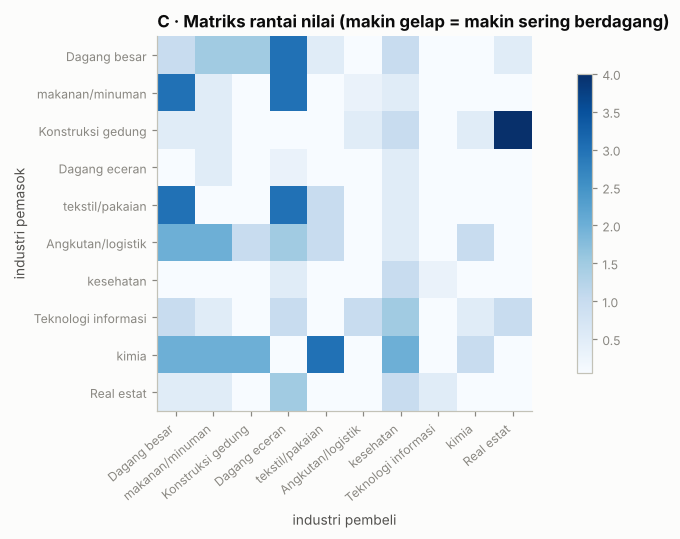

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 5))
im = ax.imshow(VC.values, cmap='Blues'); ax.grid(False)
short = [x.replace('Industri ', '').replace(' & ', '/').replace('Perdagangan', 'Dagang').replace('Aktivitas ', '') for x in VC.index]
ax.set_xticks(range(10)); ax.set_xticklabels(short, rotation=40, ha='right'); ax.set_yticks(range(10)); ax.set_yticklabels(short)
ax.set(xlabel='industri pembeli', ylabel='industri pemasok', title='C · Matriks rantai nilai (makin gelap = makin sering berdagang)')
plt.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); save_fig('02_C_matriks_rantai_nilai'); plt.show()

## D. Pembangkitan data — 18 tahap
Setiap tahap adalah satu fungsi yang membaca variabel dari tahap sebelumnya dan menulis variabel baru ke wadah `World`. Urutannya mengikuti diagram kausal di atas. Di akhir bagian ini, fungsi `generate()` menjalankan ke-18 tahap sekaligus — fungsi yang sama dipakai lagi pada uji kondisi ekstrem dan multi-seed.

### D1. Profil perusahaan & grup usaha
- **Industri** diambil sesuai bobot `INDF.w`; **ukuran** Kecil/Menengah/Besar = 40/43/17%; **umur** mengikuti distribusi gamma (banyak perusahaan muda, sedikit yang sangat tua).
- **Lokasi**: industri manufaktur cenderung di kecamatan yang punya kawasan industri, peluang ∝ (1 + POI industri)^(2·preferensi) × luas wilayah.
- **Grup usaha** (baru di v8): ±8% perusahaan Menengah/Besar tergabung dalam grup berisi 2–5 perusahaan. Di Indonesia, grup usaha (konglomerasi) umum dan nasib anggotanya saling terkait (Khanna & Yafeh, 2007) — ini menjadi bahan analisis graf.

In [5]:
# [gen]
def s01_profile(w):
    cfg, rng = w.cfg, w.rng
    N = cfg['n_core']; M = cfg['months']; nm_ = len(M)
    geo = pd.DataFrame(GEO, columns=['location_id', 'province', 'city', 'district', 'centroid_lat', 'centroid_lon', 'area_km2', 'poi_industrial_count'])
    ind = rng.choice(INDF.index, N, p=(INDF.w / INDF.w.sum()).values)
    size = np.array([rng.choice(SIZES, p=[.40, .43, .17]) for _ in range(N)])
    est = np.clip(np.round(2026 - rng.gamma(2.2, 7.5, N)), 1985, 2023).astype(int)
    loc_w = np.array([[(1 + g.poi_industrial_count) ** (2 * INDF.at[i, 'ind_pref']) * g.area_km2 for g in geo.itertuples()] for i in INDF.index])
    loc_w = loc_w / loc_w.sum(1, keepdims=True); ind_ix = {k: j for j, k in enumerate(INDF.index)}
    loc = np.array([geo.location_id[rng.choice(len(geo), p=loc_w[ind_ix[i]])] for i in ind])
    ids = [f'C{i + 1:04d}' for i in range(N)]
    names, used = make_names(rng, N)
    size_lvl = pd.Series(size).map({'Kecil': 0, 'Menengah': 1, 'Besar': 2}).values
    # grup usaha: anggota dari perusahaan Menengah/Besar, 2–5 anggota per grup
    group = np.full(N, None, dtype=object); pool_ = list(rng.permutation(np.where(size != 'Kecil')[0]))
    for k in range(int(round(N * cfg['group_frac'] / 3.5))):
        for i in [pool_.pop() for _ in range(int(rng.integers(2, 6)))]: group[i] = f'GRP-{k + 1:03d}'
    w.put(N=N, M=M, nm_=nm_, geo=geo, G=geo.set_index('location_id'), ind=ind, size=size, est=est, loc=loc, loc_w=loc_w, ind_ix=ind_ix,
          ids=ids, names=names, used=used, size_lvl=size_lvl, age=2026 - est, group=group, in_group=np.array([g_ is not None for g_ in group]),
          ix_of=lambda s_: list(M).index(pd.Period(s_, 'M')))

### D2. Kondisi tersembunyi: kesehatan *h*, pertumbuhan *g*, masalah legal, aktivitas impor
$$h_i = \varepsilon_i\cdot(0{,}85 \text{ bila anggota grup}) + 0{,}55\,z_{grup(i)} - 0{,}5\,\text{risiko industri} + 0{,}15\,(\text{ukuran}-1) + 0{,}15\tanh\!\left(\tfrac{\text{umur}-12}{10}\right) + \text{shift}$$
- *h* ≈ N(0,1): makin tinggi makin sehat. Perusahaan besar & mapan sedikit lebih sehat; industri berisiko sedikit lebih lemah.
- $z_{grup}$ = **efek grup bersama**: anggota satu grup punya kesehatan yang berkorelasi (korelasi intra-kelas ±0,3). Ini menghasilkan *homophily* di graf: tetangga yang berisiko → diri sendiri cenderung berisiko.
- *g* (pertumbuhan omzet tahunan) ≈ N(6%, 11%), sedikit lebih tinggi bila *h* tinggi.

In [6]:
# [gen]
def s02_latent(w):
    rng, N, ind, size_lvl, age, group, in_group, cfg = w.get_('rng N ind size_lvl age group in_group cfg')
    z_grp = {g_: rng.normal() for g_ in sorted({x for x in group if x})}
    grp_eff = np.array([z_grp[g_] if g_ else 0.0 for g_ in group])
    h = (rng.normal(0, 1, N) * np.where(in_group, 0.85, 1.0) + 0.55 * grp_eff - 0.5 * INDF.loc[ind, 'risk'].values + 0.15 * (size_lvl - 1)
         + 0.15 * np.tanh((age - 12) / 10) + cfg['health_shift'])
    g = rng.normal(0.06, 0.11, N) + 0.035 * h + 0.03 * cfg['health_shift']
    legal = rng.random(N) < 0.015 + 0.02 * (h < -1)
    has_import = rng.random(N) < INDF.loc[ind, 'p_import'].values
    w.put(h=h, g=g, legal=legal, has_import=has_import, grp_eff=grp_eff)

### D3. Jaringan ekosistem (rantai pasok)
Jaringan dibangun **lebih dulu** karena menentukan risiko konsentrasi dan efek berantai. Peluang perusahaan *i* memilih mitra *j* sebagai pembeli:
$$P(j) \propto \underbrace{VC[\text{ind}_i,\text{ind}_j]}_{\text{rantai nilai}} \times \underbrace{a_j}_{\text{daya tarik}} \times \underbrace{\left(0{,}03 + e^{-d_{ij}/8\,\text{km}}\right)\cdot 3^{[\text{satu kota}]}}_{\text{jarak \& klaster}} \times \underbrace{6^{[\text{satu grup}]}}_{\text{grup usaha}}$$
(untuk pemasok, arah matriks dibalik: $VC[\text{ind}_j,\text{ind}_i]$).
- **Daya tarik** $a_j$ = 25 (Besar) / 3 (Menengah) / 1 (Kecil) × lognormal → *preferential attachment*: perusahaan besar menjadi **anchor** (pembeli besar yang dipasok banyak perusahaan), menghasilkan distribusi derajat berekor tebal seperti jaringan produksi nyata (Barabási & Albert, 1999; Fujiwara & Aoyama, 2010).
- **Jarak & klaster**: mitra dagang cenderung berdekatan dan satu kota/kabupaten (klaster industri Bekasi, Tangerang, Jakarta Utara, dst.) — pola gravitasi yang terlihat di data jaringan produksi riil (Bernard dkk., 2019). Hasilnya komunitas graf yang jelas (diuji di F2).
- **Porsi ketergantungan** (`dependency_share`) ~ Dirichlet: sebagian perusahaan sangat bergantung pada satu pembeli. Industri B2C (eceran, kesehatan) hanya sedikit bergantung pada pembeli korporat.
- **Grup usaha**: anggota terhubung ke induk dengan relasi `Subsidiary`, dan 6× lebih mungkin berdagang sesama anggota.
- **Tanggal relasi**: 93% relasi sudah ada sebelum 2024; 7% **baru dimulai** Apr 2024–Mar 2026 → transaksi dengan mitra baru hanya muncul setelah relasi dimulai (dicek di F1).

In [7]:
# [gen]
def s03_network(w):
    rng, cfg, N, ids, ind, size, loc, geo, G, loc_w, ind_ix, used, group, ix_of, est = w.get_('rng cfg N ids ind size loc geo G loc_w ind_ix used group ix_of est')
    nL1, nL2 = cfg['n_ent_l1'], cfg['n_ent_l2']; nE = nL1 + nL2
    e_ids = [f'E{i + 1:05d}' for i in range(nE)]; e_names, used = make_names(rng, nE, ('PT', 'CV', 'CV', 'UD'), used)
    e_ind = rng.choice(INDF.index, nE, p=(INDF.w / INDF.w.sum()).values); e_size = rng.choice(SIZES, nE, p=[.62, .33, .05])
    e_loc = np.array([geo.location_id[rng.choice(len(geo), p=loc_w[ind_ix[i]])] for i in e_ind])
    e_bni = rng.random(nE) < np.r_[np.full(nL1, .30), np.full(nL2, .25)]
    entities = pd.DataFrame(dict(entity_id=e_ids, entity_name=[n + ' (dummy)' for n in e_names], industry=e_ind, size_class_reference=e_size,
                                 city=G.loc[e_loc, 'city'].values, location_id=e_loc, layer=np.r_[np.ones(nL1, int), np.full(nL2, 2)], is_bni_customer=e_bni))
    # kandidat mitra = perusahaan inti + entitas lapis 1
    pool_ids = np.array(ids + e_ids[:nL1]); P = len(pool_ids)
    pool_size = np.r_[size, e_size[:nL1]]
    attract = np.where(pool_size == 'Besar', 25.0, np.where(pool_size == 'Menengah', 3.0, 1.0)) * np.exp(rng.normal(0, .8, P))
    attract[N:] *= 0.5
    pi = np.array([ind_ix[x] for x in np.r_[ind, e_ind[:nL1]]])
    loc_ix = {l: k for k, l in enumerate(geo.location_id)}; pl = np.array([loc_ix[x] for x in np.r_[loc, e_loc[:nL1]]])
    la, lo = geo.centroid_lat.values, geo.centroid_lon.values
    D = haversine_km(la[:, None], lo[:, None], la[None, :], lo[None, :]); grav = cfg['gravity_floor'] + np.exp(-D / cfg['gravity_km'])
    grav = grav * np.where(np.asarray(geo.city, dtype=object)[:, None] == np.asarray(geo.city, dtype=object)[None, :], cfg['city_boost'], 1.0)
    VCm = VC.values; grp_pool = np.r_[group, np.full(nL1, None, dtype=object)]
    rel_rows = []
    for i in range(N):
        b2c = ind[i] in B2C
        nb = int(rng.integers(1, 4)) if b2c else int(rng.integers(2, 8)); ns = int(rng.integers(2, 7))
        base = attract * grav[pl[i], pl]; base[i] = 0.0
        if group[i] is not None: base = base * np.where(grp_pool == group[i], 6.0, 1.0)
        conc = rng.uniform(0.4, 1.6)                                    # makin kecil → makin bergantung pada 1 pembeli
        for rtype, k in [('Customer', nb), ('Supplier', ns)]:
            wgt = base * (VCm[pi[i], pi] if rtype == 'Customer' else VCm[pi, pi[i]])
            cand = rng.choice(P, k, replace=False, p=wgt / wgt.sum())
            scale = rng.uniform(.15, .40) if (b2c and rtype == 'Customer') else rng.uniform(.55, .90)
            share = rng.dirichlet(np.full(k, conc if rtype == 'Customer' else 0.9)) * scale
            for c, sh in zip(cand, share):
                t = 'Distributor' if rtype == 'Customer' and rng.random() < 0.3 else rtype
                rel_rows.append((ids[i], pool_ids[c], t, sh, 1))
    # grup usaha: anggota → induk (perusahaan terbesar di grup)
    for g_ in sorted({x for x in group if x}):
        mem = np.where(group == g_)[0]; head = mem[np.argmax(w.size_lvl[mem] * 10 + rng.random(len(mem)))]
        rel_rows += [(ids[m], ids[head], 'Subsidiary', 0.0, 1) for m in mem if m != head]
    # lapis 2: pemasok dari mitra lapis 1 (mengikuti rantai nilai)
    e2_ix = np.array([ind_ix[x] for x in e_ind[nL1:]])
    for j_ in range(nL1):
        if rng.random() < 0.6:
            wg = VCm[e2_ix, ind_ix[e_ind[j_]]]
            for c in rng.choice(nL2, int(rng.integers(1, 4)), replace=False, p=wg / wg.sum()):
                rel_rows.append((e_ids[j_], e_ids[nL1 + c], 'Supplier', rng.uniform(.05, .5), 2))
    rel = pd.DataFrame(rel_rows, columns=['source_id', 'target_id', 'relationship_type', 'dependency_share', 'layer_from_core'])
    rel = rel.drop_duplicates(['source_id', 'target_id', 'relationship_type']).reset_index(drop=True)
    rel['dependency_share'] = rel.dependency_share.round(3)
    # tanggal mulai relasi: sebagian besar historis; sebagian kecil baru di periode data (start_ix = indeks bulan)
    trade = rel.relationship_type.isin(['Customer', 'Distributor', 'Supplier']) & rel.layer_from_core.eq(1)
    new = trade & (rng.random(len(rel)) < cfg['new_edge_rate'])
    rel['start_ix'] = -1; rel.loc[new, 'start_ix'] = rng.integers(ix_of('2024-04'), ix_of('2026-03') + 1, new.sum())
    est_of = dict(zip(ids, est))
    lo_y = np.array([max(2008, est_of.get(s_, 2000) + 1) for s_ in rel.source_id])
    yr = np.minimum(lo_y + (rng.random(len(rel)) * (2024 - lo_y)).astype(int), 2023)
    hist = pd.to_datetime(pd.DataFrame(dict(year=yr, month=rng.integers(1, 13, len(rel)), day=rng.integers(1, 29, len(rel)))))
    newd = pd.to_datetime([str(w.M[k]) + f'-{int(d):02d}' if k >= 0 else '2000-01-01' for k, d in zip(rel.start_ix, rng.integers(1, 29, len(rel)))])
    rel['relationship_start'] = np.where(rel.start_ix >= 0, newd.strftime('%Y-%m-%d'), hist.dt.strftime('%Y-%m-%d'))
    buyers = rel[rel.relationship_type.isin(['Customer', 'Distributor']) & rel.source_id.str.startswith('C')]
    top_buyer = buyers.sort_values('dependency_share', ascending=False).drop_duplicates('source_id').set_index('source_id')
    top_share = np.array([top_buyer.dependency_share.get(c, 0.0) for c in ids])
    # anchor = pembeli besar: perusahaan inti yang paling banyak dijadikan pembeli oleh perusahaan lain
    buy_in = buyers.target_id.value_counts()
    anchors = [c for c in buy_in.index if c.startswith('C')][:12]
    w.put(entities=entities, e_ids=e_ids, e_names=e_names, e_bni=e_bni, nL1=nL1, used=used, rel=rel, buyers=buyers, top_buyer=top_buyer,
          top_share=top_share, anchors=anchors)

### D4. Kejadian bisnis (sumber anomali "Why Now")
| Kejadian | Siapa | Efek pada inflow | Mekanisme |
|---|---|---|---|
| Ekspansi | peluang 8–22%, naik bila *g* tinggi | +15/30/60%, bertahap 3 bln | menang tender / pesanan baru |
| Distress | peluang 3–15%, naik bila *h* rendah | −12/22/35%, bertahap 4 bln; 25% pulih | permintaan turun; **didahului sinyal dini 3 bulan** (D11) |
| Anchor bermasalah | 2 terlemah dari 6 pembeli terbesar, mulai Jul 2025 (anchor lain stabil) | −45% | memicu **efek berantai** ke pemasoknya |
| Efek berantai | pemasok anchor bermasalah | −min(50%, 0,7 × porsi ke anchor), lag 2 bln | *financial contagion* lewat rantai pasok (Battiston dkk., 2012) |
| Buyer utama keluar | 7% perusahaan dengan pembeli utama ≥22% | −porsi pembeli × 0,55 | relasi berakhir (`relationship_end`) |
| Erosi wallet share | 9% nasabah normal | aliran via BNI −55% bertahap 8 bln, **omzet tetap** | pindah ke bank pesaing |
| Spike sesaat | 10% | ×2,5/4/7 selama 1 bulan | termin proyek / jual aset — **bukan** anomali bisnis |

Kejadian dimulai paling cepat Okt 2024, sehingga setiap perusahaan punya baseline normal ≥ 9 bulan.

In [8]:
# [gen]
def s04_events(w):
    rng, N, M, nm_, ids, h, g, size_lvl, ix_of, top_share, top_buyer, anchors, buyers, rel = w.get_(
        'rng N M nm_ ids h g size_lvl ix_of top_share top_buyer anchors buyers rel')
    sig_ = sig
    p_dis = 0.03 + 0.12 * sig_(-1.6 * h - 1.0); p_exp = 0.08 + 0.14 * sig_(5 * g)
    u_ = rng.random(N); regime = np.where(u_ < p_dis, 'distress', np.where(u_ < p_dis + p_exp, 'expansion', 'normal'))
    mag = np.where(regime == 'expansion', rng.choice([0.15, 0.30, 0.60], N, p=[.4, .4, .2]), np.where(regime == 'distress', rng.choice([0.12, 0.22, 0.35], N, p=[.4, .4, .2]), 0.0))
    start_ix = rng.integers(ix_of('2024-10'), nm_ - 1, N)
    anchor_ix = np.array([ids.index(a) for a in anchors[:12]])
    big = anchor_ix[:6]                                                                  # 6 pembeli terbesar
    distressed_anchors = big[np.argsort(h[big])[:2]]                                    # 2 yang paling lemah mengalami distress
    regime[anchor_ix[regime[anchor_ix] == 'distress']] = 'normal'                       # anchor lain stabil
    regime[distressed_anchors] = 'distress'; mag[distressed_anchors] = 0.45; start_ix[distressed_anchors] = ix_of('2025-07')
    recover = (regime == 'distress') & (rng.random(N) < 0.25); recover[distressed_anchors] = False
    spike = rng.random(N) < 0.10; spike_ix = rng.integers(3, nm_, N); spike_mult = rng.choice([2.5, 4.0, 7.0], N, p=[.4, .4, .2])
    top_new = np.array([top_buyer.start_ix.get(c, -1) >= 0 for c in ids])            # pembeli utama yang relasinya baru → tidak bisa "keluar"
    exit_cand = (top_share >= 0.22) & ~np.isin(np.arange(N), anchor_ix) & ~top_new
    buyer_exit = exit_cand & (rng.random(N) < 0.07) & (regime != 'distress'); exit_ix = rng.integers(ix_of('2025-03'), nm_ - 1, N)
    erosion = (regime == 'normal') & ~buyer_exit & ~np.isin(np.arange(N), anchor_ix) & (rng.random(N) < 0.09); erosion_ix = rng.integers(ix_of('2025-01'), ix_of('2026-03'), N)
    da_ids = {ids[k] for k in distressed_anchors}
    sup_to = buyers[buyers.target_id.isin(da_ids)].groupby('source_id').dependency_share.sum()
    contagion = np.array([sup_to.get(c, 0.0) for c in ids]); contagion[distressed_anchors] = 0
    cont_ix = ix_of('2025-07') + 2
    m2025 = np.array([p.year == 2025 for p in M])
    frac_2025 = lambda ix: np.array([m2025[k:].sum() / 12 if k < nm_ else 0 for k in ix])
    exp_eff = np.where(regime == 'expansion', mag * frac_2025(start_ix), 0)
    dis_eff = np.where(regime == 'distress', mag * frac_2025(start_ix), 0) + np.minimum(0.5, 0.7 * contagion) * m2025[cont_ix:].sum() / 12
    w.put(regime=regime, mag=mag, start_ix=start_ix, anchor_ix=anchor_ix, distressed_anchors=distressed_anchors, recover=recover, spike=spike,
          spike_ix=spike_ix, spike_mult=spike_mult, buyer_exit=buyer_exit, exit_ix=exit_ix, erosion=erosion, erosion_ix=erosion_ix, da_ids=da_ids,
          contagion=contagion, cont_ix=cont_ix, exp_eff=exp_eff, dis_eff=dis_eff)

### D5. Laporan keuangan 2024–2025
Rasio dibangkitkan dari kesehatan + level struktural + kejadian + derau, lalu neraca disusun agar **identitas akuntansi** terjaga (aset = utang + ekuitas; aset lancar ≤ aset; laba ≤ omzet):
$$\log DER = 0{,}15 + \text{level}_{ind,size} - 0{,}50\,h + 1{,}3\,\text{shock} + \varepsilon,\quad \varepsilon\sim N(0;0{,}30)$$
$$\log CR = 0{,}30 + \text{level} + 0{,}26\,h - 0{,}9\,\text{shock} + \varepsilon,\qquad \text{margin EBIT} = 0{,}085 + \text{level} + 0{,}038\,h - 0{,}25\,\text{shock} + \varepsilon$$
- **Level struktural** per industri × ukuran sengaja tidak sejalan dengan risiko industri: RS & logistik DER tinggi tapi risikonya rendah-sedang; tekstil DER rendah tapi berisiko. Rasio mentah akan menyesatkan → fitur **relatif terhadap peer** menjadi bermakna.
- Derau ε mencerminkan bahwa laporan tahunan adalah ukuran kesehatan yang **tidak sempurna** (terlambat setahun, *window dressing*).
- Omzet: lognormal sekitar median per ukuran (Rp 8 / 32 / 160 miliar); 2025 = 2024 × (1 + g + efek kejadian).

In [9]:
# [gen]
def s05_financials(w):
    rng, N, ind, size, h, g, exp_eff, dis_eff = w.get_('rng N ind size h g exp_eff dis_eff')
    lv = np.array([IND_LEVEL[x] for x in ind]) + np.array([SIZE_LEVEL[s_] for s_ in size])
    rev24 = np.array([REV_MED[s_] for s_ in size]) * np.exp(rng.normal(0, 0.55, N) + 0.12 * h)
    rev25 = rev24 * (1 + g + 0.6 * exp_eff - 0.8 * dis_eff + rng.normal(0, 0.04, N))
    fin_rows = []
    for yr, rev, shock in [(2024, rev24, 0 * h), (2025, rev25, dis_eff)]:
        assets = rev / np.exp(rng.normal(0.05, 0.30, N) - 0.4 * lv[:, 0])
        der = np.exp(0.15 + lv[:, 0] - 0.50 * h + 1.3 * shock + rng.normal(0, 0.30, N))
        debt = assets * der / (1 + der); equity = assets - debt
        cr = np.exp(0.30 + lv[:, 1] + 0.26 * h - 0.9 * shock + rng.normal(0, 0.18, N))
        ca = assets * np.clip(rng.beta(4, 4, N) + 0.05, 0.1, 0.92)
        cl = np.minimum(ca / cr, debt * 0.97)
        ebit_m = np.clip(0.085 + lv[:, 2] + 0.038 * h - 0.25 * shock + rng.normal(0, 0.028, N), -0.15, 0.40)
        ebit = rev * ebit_m; interest = debt * rng.uniform(0.085, 0.13, N)
        net = np.where(ebit - interest > 0, (ebit - interest) * 0.78, ebit - interest)
        fin_rows.append(pd.DataFrame(dict(fiscal_year=yr, revenue_idr_bn=rev, total_assets_idr_bn=assets, total_equity_idr_bn=equity, total_debt_idr_bn=debt,
                                          current_assets_idr_bn=ca, current_liabilities_idr_bn=cl, ebit_idr_bn=ebit, interest_expense_idr_bn=interest, net_profit_idr_bn=net)))
    w.put(rev24=rev24, rev25=rev25, fin_rows=fin_rows)

### D6. Status nasabah & kebutuhan produk
- **Nasabah vs prospect**: skor = 0,8·ukuran + 0,03·umur − 1,2·[kecamatan white-space] + 0,2·h + derau → 1.400 skor tertinggi menjadi nasabah. Kecamatan white-space sengaja berpenetrasi rendah.
- **Kebutuhan 8 produk** (ground truth) dari logit yang masuk akal: Giro dibutuhkan semua; Deposito bila margin > 6%; VA untuk industri ritel/B2C; Cash Management untuk ukuran besar; Payroll ∝ log(karyawan); KMK untuk industri padat modal kerja/ekspansi/distress; KI untuk industri padat capex/ekspansi; Trade Finance hanya importir.
- **Nasabah kredit**: 1.000 nasabah dengan kebutuhan kredit tertinggi (+ sedikit efek *h*).
- **Wallet share BNI** ~ Beta(2,2; 2,5): porsi aliran dana nasabah yang lewat BNI.

In [10]:
# [gen]
def s06_clients_needs(w):
    rng, cfg, N, loc, size, size_lvl, age, h, g, ind, rev25, fin_rows, regime, has_import = w.get_(
        'rng cfg N loc size size_lvl age h g ind rev25 fin_rows regime has_import')
    ws = np.isin(loc, WHITE_SPACE)
    client_score = 0.8 * size_lvl + 0.03 * np.minimum(age, 25) - 1.2 * ws + 0.2 * h + rng.normal(0, 0.8, N)
    order = np.argsort(-client_score); n_cli = cfg['n_credit'] + cfg['n_noncredit']
    is_client = np.zeros(N, bool); is_client[order[:n_cli]] = True
    emp = np.maximum(5, np.round(rev25 * pd.Series(size).map(EMP_PER_BN).values * np.exp(rng.normal(0, 0.3, N)))).astype(int)
    npm25 = fin_rows[1].net_profit_idr_bn.values / fin_rows[1].revenue_idr_bn.values
    logit = np.c_[
        np.full(N, 3.0),
        -1.1 + 1.4 * (npm25 > 0.06) + 0.35 * size_lvl,
        -1.3 + 1.6 * INDF.loc[ind, 'va'].values + 0.35 * size_lvl,
        -2.0 + 0.95 * size_lvl + 0.6 * (regime == 'expansion'),
        -2.3 + 0.75 * np.log1p(emp / 25),
        -0.9 + 1.0 * INDF.loc[ind, 'wc'].values + 1.1 * (regime == 'expansion') + 0.6 * (g > 0.08) + 0.6 * (regime == 'distress'),
        -2.0 + 1.0 * INDF.loc[ind, 'capex'].values + 1.3 * (regime == 'expansion') + 0.3 * size_lvl,
        np.where(has_import, 2.2, -3.2)]
    need = (rng.random((N, 8)) < sig(logit)).astype(int); need[:, 0] = 1
    credit_score = need[:, 5] + need[:, 6] + 0.10 * h + rng.normal(0, 0.6, N)
    cli_idx = np.where(is_client)[0]; cr_order = cli_idx[np.argsort(-credit_score[cli_idx])]
    is_credit = np.zeros(N, bool); is_credit[cr_order[:cfg['n_credit']]] = True
    ctype = np.where(is_credit, 'Existing credit client', np.where(is_client, 'Existing non-credit client', 'Prospect'))
    no_cr = is_credit & (need[:, 5] + need[:, 6] == 0); need[no_cr, 5] = 1
    wallet = np.where(is_client, np.clip(rng.beta(2.2, 2.5, N) + 0.05, 0.05, 0.95), 0.0)
    w.put(is_client=is_client, cli_idx=cli_idx, emp=emp, npm25=npm25, need=need, is_credit=is_credit, ctype=ctype, wallet=wallet)

### D7. Risiko: skor laten → rating sebenarnya → label yang tercatat
$$s_i = -h_i + 0{,}6\,\text{risiko industri} + 0{,}30[\text{Kecil}] - 0{,}15[\text{Besar}] + 0{,}25[\text{umur}<5] + 2{,}8\,\text{distress} + 0{,}6\,\text{legal} + 2{,}6\max(0,\text{porsi pembeli utama}-0{,}30) + 1{,}6\,\text{efek berantai}$$
- **Rating sebenarnya** = kuantil dari $s_i + u_i$, dengan $u_i \sim N(0;\,0{,}25)$ = faktor yang **tidak pernah terekam data** (karakter pemilik, informasi lunak). Ini membuat akurasi sempurna mustahil — batasnya dihitung sebagai **plafon** (*oracle*) di F4.
- **Label tercatat** = rating sebenarnya dengan 4% kesalahan analis ke kelas tetangga (dicatat di `gt_client_risk.label_flipped`) — realistis karena rating bank juga mengandung *label noise* (Northcutt dkk., 2021).
- Ambang kelas dikalibrasi pada kondisi normal, sehingga skenario krisis benar-benar menaikkan porsi High (F3).

In [11]:
# [gen]
def s07_risk(w):
    rng, cfg, N, h, ind, size, age, regime, mag, legal, top_share, contagion, is_credit = w.get_(
        'rng cfg N h ind size age regime mag legal top_share contagion is_credit')
    s_det = (-1.0 * h + 0.6 * INDF.loc[ind, 'risk'].values + 0.30 * (size == 'Kecil') - 0.15 * (size == 'Besar') + 0.25 * (age < 5)
             + 2.8 * np.where(regime == 'distress', mag, 0) + 0.6 * legal + 2.6 * np.maximum(0, top_share - 0.30) + 1.6 * contagion)
    u = rng.normal(0, cfg['sigma_unobserved'], N); s_real = s_det + u
    q1, q2 = np.quantile(s_real + cfg['health_shift'], cfg['risk_quantiles'])
    cls = lambda s: np.where(s >= q2, 'High', np.where(s >= q1, 'Medium', 'Low'))
    true_cls = cls(s_real)
    flip = is_credit & (rng.random(N) < cfg['label_error_rate'])
    adj = {'Low': ['Medium'], 'Medium': ['Low', 'High'], 'High': ['Medium']}
    obs_cls = true_cls.copy(); obs_cls[flip] = [rng.choice(adj[c]) for c in true_cls[flip]]
    w.put(s_det=s_det, u=u, s_real=s_real, true_cls=true_cls, obs_cls=obs_cls, flip=flip, oracle_cls=cls(s_det))

### D8. Laporan yang tidak diserahkan (MNAR) & tabel perusahaan
$$P(\text{laporan hilang}) = \sigma(-3{,}4 - 0{,}8h + 0{,}8[\text{Kecil}] + 1{,}1[\text{prospect}] - 2{,}5[\text{nasabah kredit}])$$
Perusahaan yang lemah lebih sering **tidak menyerahkan** laporan keuangan — *missing not at random* (Rubin, 1976). Akibatnya, "tidak ada laporan" adalah informasi, bukan sekadar sel kosong; dan mengisi nilai kosong dengan median akan membuat perusahaan berisiko terlihat normal.

Tabel `companies` juga memuat kolom baru `business_group` (grup usaha — di perbankan Indonesia diketahui dari data kelompok debitur).

In [12]:
# [gen]
def s08_companies(w):
    rng, cfg, N, h, size, size_lvl, is_client, is_credit, cli_idx, est, loc, G, ids, names, ind, ctype, emp, has_import, group, fin_rows = w.get_(
        'rng cfg N h size size_lvl is_client is_credit cli_idx est loc G ids names ind ctype emp has_import group fin_rows')
    p_miss = sig(-3.4 - 0.8 * h + 0.8 * (size == 'Kecil') + 1.1 * (~is_client) - 2.5 * is_credit)
    has_fin = rng.random(N) >= p_miss
    audited = rng.random(N) < sig(-1.2 + 1.3 * size_lvl + 0.5 * is_credit)
    onboard = pd.Series(pd.NaT, index=range(N), dtype='datetime64[ns]')
    for i in cli_idx:
        lo_ = pd.Timestamp(max(est[i] + 1, 2005), 1, 1); hi_ = pd.Timestamp('2026-03-31')
        onboard[i] = lo_ + pd.Timedelta(days=int(rng.integers(0, max((hi_ - lo_).days, 1))))
    rm_pool = [f'RM-{k:03d}' for k in range(1, 41)]
    lat = G.loc[loc, 'centroid_lat'].values + rng.normal(0, 0.012, N); lon = G.loc[loc, 'centroid_lon'].values + rng.normal(0, 0.012, N)
    companies = pd.DataFrame(dict(company_id=ids, company_name=[n + ' (dummy)' for n in names], industry=ind, kbli_2digit=INDF.loc[ind, 'kbli'].values,
                                  size_class_reference=size, customer_type=ctype, establishment_year=est, employees=emp, city=G.loc[loc, 'city'].values,
                                  district=G.loc[loc, 'district'].values, location_id=loc, latitude=lat.round(5), longitude=lon.round(5),
                                  is_listed=(size == 'Besar') & (rng.random(N) < 0.30), has_import_activity=has_import,
                                  onboarding_date=onboard.dt.strftime('%Y-%m-%d').where(onboard.notna(), None).values,
                                  rm_id=np.where(is_client, rng.choice(rm_pool, N), None), payroll_bank='Bank lain', is_anchor_candidate=False,
                                  business_group=group))
    fin = pd.concat([f.assign(company_id=ids) for f in fin_rows])
    fin['is_audited'] = np.tile(audited, 2)
    fin = fin[np.tile(has_fin, 2)].copy()
    for c_ in [c for c in fin.columns if c.endswith('_bn')]: fin[c_] = fin[c_].round(3 if 'interest' in c_ else 2)
    for c_ in ['ebit_idr_bn', 'interest_expense_idr_bn']: fin.loc[rng.random(len(fin)) < cfg['dq']['nan_ebit'], c_] = np.nan
    fin = fin[['company_id', 'fiscal_year', 'revenue_idr_bn', 'total_assets_idr_bn', 'total_equity_idr_bn', 'total_debt_idr_bn', 'current_assets_idr_bn',
               'current_liabilities_idr_bn', 'ebit_idr_bn', 'interest_expense_idr_bn', 'net_profit_idr_bn', 'is_audited']].sort_values(['company_id', 'fiscal_year'])
    w.put(p_miss=p_miss, has_fin=has_fin, onboard=onboard, rm_pool=rm_pool, companies=companies, fin=fin)

### D9. Melengkapi jaringan: nilai transaksi tahunan, relasi yang berakhir, anchor
- `annual_transaction_value_idr_mn` = porsi ketergantungan × omzet (pemasok ×0,6).
- Buyer utama yang keluar diberi `relationship_end` = bulan keluarnya.
- `is_anchor_candidate` = 12 perusahaan inti yang paling banyak dijadikan **pembeli** oleh perusahaan lain (off-taker utama ekosistem).

In [13]:
# [gen]
def s09_network_finalize(w):
    rel, ids, rev25, buyer_exit, top_buyer, M, exit_ix, companies, anchors = w.get_('rel ids rev25 buyer_exit top_buyer M exit_ix companies anchors')
    rev_map = dict(zip(ids, rev25))
    rel['annual_transaction_value_idr_mn'] = (rel.dependency_share * rel.source_id.map(rev_map).fillna(5.0) * 1000 * np.where(rel.relationship_type.eq('Supplier'), 0.6, 1.0)).round(1)
    rel['relationship_end'] = None
    for i in np.where(buyer_exit)[0]:
        r_ = top_buyer.loc[ids[i]]; rel.loc[(rel.source_id == ids[i]) & (rel.target_id == r_.target_id), 'relationship_end'] = str(M[exit_ix[i]])
    companies['is_anchor_candidate'] = companies.company_id.isin(anchors)
    w.put(rel=rel)

### D10. Kepemilikan produk & fasilitas kredit
- Produk dimiliki bila **dibutuhkan** dan tidak dilayani bank lain; peluang naik dengan wallet share & lama menjadi nasabah. Kepemilikan tanpa kebutuhan hanya 2% (derau wajar).
- **Utilisasi kredit** Jun 2026 dihitung dari **kondisi usaha** (h, distress, efek berantai), bukan dari label → fitur sah.
- **Kolektibilitas, DPD, watchlist, restrukturisasi** diturunkan dari rating sebenarnya → **proxy label**. Kolom ini disediakan karena memang ada di sistem bank, tetapi **dilarang** dipakai sebagai fitur model risiko (ditandai di kamus data, diuji di F5).

In [14]:
# [gen]
def s10_products_credit(w):
    rng, N, is_client, is_credit, onboard, need, wallet, regime, mag, nm_, start_ix, recover, h, contagion, rev25, true_cls, legal, ind, ids, companies = w.get_(
        'rng N is_client is_credit onboard need wallet regime mag nm_ start_ix recover h contagion rev25 true_cls legal ind ids companies')
    other_bank = (rng.random((N, 8)) < 0.55).astype(int)
    tenure = np.where(is_client, (pd.Timestamp('2026-06-30') - onboard).dt.days.fillna(0).values / 365, 0)
    own = np.zeros((N, 8), int)
    for k in range(8):
        p = np.where(need[:, k] == 1, sig(-0.5 + 2.0 * wallet + 0.07 * np.minimum(tenure, 15) - 1.2 * other_bank[:, k]), 0.02)
        own[:, k] = (rng.random(N) < p) & is_client
    own[is_client, 0] = 1; own[~is_client] = 0
    own[is_credit, 5] = np.where(need[is_credit, 5] == 1, 1, own[is_credit, 5]); own[is_credit, 6] = np.where(need[is_credit, 6] == 1, 1, own[is_credit, 6])
    own[~is_credit, 5] = 0; own[~is_credit, 6] = 0
    own[is_credit & (own[:, 5] + own[:, 6] == 0), 5] = 1
    payroll_bank = np.where(own[:, 4] == 1, 'BNI', 'Bank lain'); companies['payroll_bank'] = payroll_bank
    dis_now = np.where(regime == 'distress', mag * np.clip((nm_ - start_ix) / 4, 0, 1) * np.where(recover, 0.4, 1.0), 0.0)
    util = np.clip(0.52 - 0.08 * h + 0.9 * dis_now + 0.35 * np.minimum(0.5, 0.7 * contagion) + 0.06 * need[:, 5] + rng.normal(0, 0.14, N), 0.10, 1.0)
    coll_p = {'Low': [.97, .03, 0, 0, 0], 'Medium': [.66, .32, .02, 0, 0], 'High': [.18, .44, .18, .10, .10]}
    cf_rows = []
    for i in np.where(is_credit)[0]:
        ft = 'KMK + KI' if own[i, 5] and own[i, 6] else ('Kredit Modal Kerja' if own[i, 5] else 'Kredit Investasi')
        lim = rev25[i] * rng.uniform(0.10, 0.35); col = int(rng.choice([1, 2, 3, 4, 5], p=coll_p[true_cls[i]]))
        dpd = {1: rng.integers(0, 11), 2: rng.integers(11, 91), 3: rng.integers(91, 121), 4: rng.integers(121, 181), 5: rng.integers(181, 360)}[col]
        pol = 'Legal issue' if legal[i] and rng.random() < .7 else ('Sector limit' if ind[i] in ('Real estat', 'Konstruksi gedung') and rng.random() < .15 else None)
        cf_rows.append((ids[i], ft, round(lim, 2), round(lim * util[i], 2), round(util[i], 3), col, int(dpd), bool(col >= 3 or rng.random() < .03),
                        bool(col >= 2 and rng.random() < .55), pol))
    credit = pd.DataFrame(cf_rows, columns=['company_id', 'facility_type', 'limit_idr_bn', 'outstanding_idr_bn', 'utilization', 'collectibility', 'max_dpd_12m',
                                            'restructuring_flag', 'watchlist_flag', 'policy_restriction'])
    w.put(other_bank=other_bank, tenure=tenure, own=own, payroll_bank=payroll_bank, util=util, credit=credit)

### D11. Transaksi (per transaksi, Jan 2024 – Jun 2026)
Inflow bulanan perusahaan *i* bulan *t*:
$$\text{inflow}_{it} = \frac{\text{omzet}_{2024}}{12}\times\text{wallet}_i\times(1+\text{musim}_{ind,t})(1+\text{amp}_{ind}\cdot\text{Lebaran}_t)(1+g_i)^{t/12}\times e^{\sigma_i\,\varepsilon_{it}}\times\text{efek kejadian}_{it}$$
- **Musiman**: Lebaran (puncak Mar/Apr, terkuat di eceran, F&B, tekstil) dan Desember (konstruksi, TI, logistik).
- **Volatilitas** $\sigma_i$ lebih tinggi untuk perusahaan lemah dan **lebih rendah untuk perusahaan besar** (×1,25 / 1,0 / 0,6) — volatilitas pertumbuhan perusahaan menurun dengan ukuran (Stanley dkk., 1996).
- **Inflow** dipecah menjadi beberapa transaksi lognormal; counterparty diambil dari pembeli di jaringan sesuai porsinya (pembeli yang sudah keluar / relasi yang belum dimulai tidak muncul).
- **Outflow**: payroll (tanggal 25–27; THR pada bulan Maret), pajak (tanggal 5–15), pembayaran supplier, impor.
- **Perilaku pembayaran sebagai sinyal dini** (dasar *early-warning system* di bank):
  - *Kas ketat kronis* — perusahaan lemah: peluang pajak lewat tanggal 15 = 4% + 30%·σ(−1,8h − 1,6); kadang gaji dibayar ≥ tanggal 28.
  - *Pra-distress* — mulai **3 bulan sebelum** omzet turun, intensitas naik 25% → 50% → 75% → 100%: gaji makin telat & dicicil (60/40), pajak telat (sampai 74%), pembayaran supplier ditahan (−35%).
- **Masalah kualitas data disengaja**: duplikat 0,3%, nominal nol, channel/counterparty kosong — bahan latihan *data cleaning* di notebook 02.

In [15]:
# [gen]
def _transactions(rng, cfg, companies, ids, size, rev25, wallet, is_client, emp, has_import, own, regime, mag, start_ix, spike, spike_ix, spike_mult,
                  buyer_exit, exit_ix, top_buyer, rel, mult, h, bni_parties, da_ids=(), cont_ix=10**6, share_mult=None):
    M = cfg['months']; N = len(ids); n_in = {'Kecil': 7, 'Menengah': 13, 'Besar': 22}
    buy = rel[rel.relationship_type.isin(['Customer', 'Distributor'])].groupby('source_id')[['target_id', 'dependency_share', 'start_ix']].agg(list)
    sup = rel[rel.relationship_type.eq('Supplier')].groupby('source_id')[['target_id', 'dependency_share', 'start_ix']].agg(list)
    cols = {k: [] for k in ['company_id', 'transaction_date', 'direction', 'amount_idr_mn', 'channel', 'transaction_type', 'counterparty_id', 'counterparty_bank', 'data_visibility']}
    spike_rows = []; tid = 0
    def emit(cid, dates, d, amts, ch, tt, cps, vis):
        n = len(amts)
        cols['company_id'] += [cid] * n; cols['transaction_date'] += dates; cols['direction'] += [d] * n; cols['amount_idr_mn'] += list(np.round(amts, 2))
        cols['channel'] += list(ch); cols['transaction_type'] += [tt] * n; cols['counterparty_id'] += list(cps)
        cols['counterparty_bank'] += ['BNI' if (c in bni_parties or (c.startswith('EXT') and rng.random() < .3)) else 'Bank lain' for c in cps]
        cols['data_visibility'] += [vis] * n
    for i in range(N):
        cid = ids[i]; client = is_client[i]; vis_share = wallet[i] if client else rng.uniform(.04, .12)
        base_in = rev25[i] * 1000 / 12 * vis_share                   # rev25 di sini = omzet 2024 (pertumbuhan ada di mult)
        pre = start_ix[i] - 3 if regime[i] == 'distress' else 10 ** 6  # fase sinyal dini distress: mulai 3 bulan sebelum omzet turun
        b_t, b_s, b_st = (buy.loc[cid].target_id, np.array(buy.loc[cid].dependency_share), np.array(buy.loc[cid].start_ix)) if cid in buy.index else ([], np.array([]), np.array([]))
        s_t, s_s, s_st = (np.array(sup.loc[cid].target_id), np.array(sup.loc[cid].dependency_share), np.array(sup.loc[cid].start_ix)) if cid in sup.index else (np.array([]), np.array([]), np.array([]))
        ex_t = top_buyer.at[cid, 'target_id'] if buyer_exit[i] else None
        out_ratio = 0.93 - 0.03 * h[i]
        chronic = sig(-1.8 * h[i] - 1.6)                               # kas ketat kronis (perusahaan lemah) → pajak/gaji kadang telat
        for t, p in enumerate(M):
            dim = p.days_in_month; total_in = base_in * mult[i, t]
            k_in = max(1, rng.poisson(n_in[size[i]] * (1 if client else .25) * min(mult[i, t], 2)))
            w = rng.lognormal(0, 1.0, k_in); amts = total_in * w / w.sum()
            day = lambda k, lo=1, hi=None: [f'{p.year}-{p.month:02d}-{int(x):02d}' for x in rng.integers(lo, (hi or dim) + 1, k)]
            act_m = [(st <= t) and not (b == ex_t and t >= exit_ix[i]) for b, st in zip(b_t, b_st)]       # relasi aktif: sudah dimulai & belum berakhir
            act_b = [b for b, m_ in zip(b_t, act_m) if m_]
            sh = np.array([s * (0.65 if (b in da_ids and t >= cont_ix) else 1.0) for b, s, m_ in zip(b_t, b_s, act_m) if m_])
            prog = float(np.clip((t - pre + 1) / 4, 0, 1))                 # 0 = normal … 1 = tekanan penuh
            cps = [rng.choice(act_b, p=(sh + 1e-3) / (sh + 1e-3).sum()) if act_b and rng.random() < .7 else f'EXT-{rng.integers(10000, 99999)}' for _ in range(k_in)]
            types = np.where(rng.random(k_in) < .72, 'Collection', 'Transfer')
            if not client:
                keep = np.array([c in bni_parties for c in cps]) | (rng.random(k_in) < .15); amts, cps, types = amts[keep], list(np.array(cps)[keep]), types[keep]
            for tt in ['Collection', 'Transfer']:
                mk = types == tt
                if mk.any():
                    ch = rng.choice(['Virtual account', 'Transfer masuk', 'Kliring'], mk.sum(), p=[.45, .4, .15]) if tt == 'Collection' else rng.choice(['Transfer masuk', 'Kliring', 'Internet banking'], mk.sum())
                    emit(cid, day(mk.sum()), 'IN', amts[mk], ch, tt, np.array(cps, dtype=object)[mk], 'Full - rekening BNI' if client else 'Partial - via counterparty BNI')
            if spike[i] and t == spike_ix[i] and client:
                k_ = int(rng.integers(1, 4)); a_ = base_in * spike_mult[i] / k_ * np.ones(k_); emit(cid, day(k_), 'IN', a_, ['Kliring'] * k_, 'Transfer', [f'EXT-{rng.integers(10000, 99999)}' for _ in range(k_)], 'Full - rekening BNI')
                spike_rows.append((cid, len(cols['amount_idr_mn']) - k_, k_))
            if not client: continue
            dis = regime[i] == 'distress' and t >= start_ix[i]
            total_out = total_in * (out_ratio + (0.08 if dis else 0)) * np.exp(rng.normal(0, .05))
            pay = emp[i] * rng.uniform(5.5, 7.5) * (1 if own[i, 4] else vis_share * 1.5) * (1.9 if p.month == 3 else 1)   # THR jelang Lebaran (Mar 2024/2025/2026)
            pay = pay * (share_mult[i, t] if share_mult is not None else 1)
            ch_p = [rng.choice(['Cash management', 'Internet banking'])]
            if prog > 0 and rng.random() < 0.25 + 0.6 * prog:          # SINYAL DINI: gaji dibayar makin telat & dicicil
                d1 = min(dim, 27 + int(round(3 * prog + rng.integers(0, 2))))
                if rng.random() < 0.6 * prog:
                    emit(cid, [f'{p.year}-{p.month:02d}-{d1:02d}', f'{p.year}-{p.month:02d}-{dim:02d}'], 'OUT', np.array([pay * .6, pay * .4]), ch_p * 2, 'Payroll', ['PAYROLL-BATCH'] * 2, 'Full - rekening BNI')
                else:
                    emit(cid, [f'{p.year}-{p.month:02d}-{d1:02d}'], 'OUT', np.array([pay]), ch_p, 'Payroll', ['PAYROLL-BATCH'], 'Full - rekening BNI')
            else:
                pay_day = min(dim, int(rng.choice([25, 25, 26, 27]))) if rng.random() < .92 - 0.35 * chronic else min(dim, int(rng.integers(28, 31)))
                emit(cid, [f'{p.year}-{p.month:02d}-{pay_day:02d}'], 'OUT', np.array([pay]), ch_p, 'Payroll', ['PAYROLL-BATCH'], 'Full - rekening BNI')
            tax = total_in * rng.uniform(.03, .05)
            late = rng.random() < 0.04 + 0.30 * chronic + 0.70 * prog                      # SINYAL DINI: pajak lewat tanggal 15
            emit(cid, day(1, 16, min(dim, 28)) if late else day(1, 5, 15), 'OUT', np.array([tax]), ['Internet banking'], 'Tax', [f'EXT-{rng.integers(10000, 99999)}'], 'Full - rekening BNI')
            rest = max(total_out - pay - tax, total_in * .2)
            imp = rest * rng.uniform(.15, .35) if has_import[i] else 0
            rest = rest * (1 - 0.35 * prog)                                # SINYAL DINI: menahan pembayaran ke supplier
            k_s = max(1, rng.poisson(n_in[size[i]] * .6 * (1 - 0.4 * prog))); w = rng.lognormal(0, 1.0, k_s); a_ = (rest - imp) * w / w.sum()
            sa = s_st <= t; st_a, ss_a = s_t[sa], s_s[sa]
            cps = [rng.choice(st_a, p=(ss_a + 1e-3) / (ss_a + 1e-3).sum()) if len(st_a) and rng.random() < .7 else f'EXT-{rng.integers(10000, 99999)}' for _ in range(k_s)]
            tt = np.where(rng.random(k_s) < .75, 'Supplier payment', 'Transfer')
            for t_ in ['Supplier payment', 'Transfer']:
                mk = tt == t_
                if mk.any(): emit(cid, day(mk.sum()), 'OUT', a_[mk], rng.choice(['Cash management', 'Internet banking', 'Transfer keluar', 'Teller'], mk.sum(), p=[.35, .35, .2, .1]), t_, np.array(cps, dtype=object)[mk], 'Full - rekening BNI')
            if imp: emit(cid, day(1), 'OUT', np.array([imp]), ['Cash management'], 'Import payment', [f'EXT-{rng.integers(10000, 99999)}'], 'Full - rekening BNI')
    tx = pd.DataFrame(cols)
    tx.insert(0, 'transaction_id', [f'T{k + 1:07d}' for k in range(len(tx))])
    spike_ids = [tx.transaction_id.iloc[s + j] for _, s, k in spike_rows for j in range(k)]
    dq = cfg['dq']; n = len(tx)
    tx.loc[rng.random(n) < dq['nan_channel'], 'channel'] = np.nan; tx.loc[rng.random(n) < dq['nan_cp'], 'counterparty_id'] = np.nan
    tx.loc[rng.random(n) < dq['zero_tx'], 'amount_idr_mn'] = 0.0
    dup = tx.sample(frac=dq['dup_tx'], random_state=1)
    tx = pd.concat([tx, dup]).sort_values(['company_id', 'transaction_date', 'transaction_id']).reset_index(drop=True)
    return tx, spike_ids

def s11_transactions(w, with_tx=True):
    rng, cfg, N, M, nm_, ind, g, h, regime, mag, start_ix, recover, buyer_exit, exit_ix, top_buyer, contagion, erosion, erosion_ix, spike, spike_ix, spike_mult, distressed_anchors, ids, cont_ix = w.get_(
        'rng cfg N M nm_ ind g h regime mag start_ix recover buyer_exit exit_ix top_buyer contagion erosion erosion_ix spike spike_ix spike_mult distressed_anchors ids cont_ix')
    mult = np.ones((N, nm_)); vol = (0.09 + 0.14 * sig(-1.2 * h)) * pd.Series(w.size).map({'Kecil': 1.25, 'Menengah': 1.0, 'Besar': 0.6}).values   # usaha besar lebih stabil
    for t, p in enumerate(M):
        ind_m = np.array([IND_MONTH.get(x, {12: 0.06, 1: -0.05}).get(p.month, 0.0) for x in ind])
        mult[:, t] *= (1 + ind_m) * (1 + INDF.loc[ind, 'season'].values * LEBARAN.get(str(p), 0)) * (1 + g) ** (t / 12)
    mult *= np.exp(rng.normal(0, 1, (N, nm_)) * vol[:, None])
    ramp = lambda k, n: np.clip((np.arange(nm_) - k + 1) / n, 0, 1)
    share_mult = np.ones((N, nm_))
    for i in range(N):
        if regime[i] == 'expansion': mult[i] *= 1 + mag[i] * ramp(start_ix[i], 3)
        if regime[i] == 'distress':
            d = mag[i] * ramp(start_ix[i], 4)
            if recover[i]: d = d * (1 - ramp(start_ix[i] + 6, 4))
            mult[i] *= 1 - d
        if buyer_exit[i]: mult[i, exit_ix[i]:] *= 1 - top_buyer.at[ids[i], 'dependency_share'] * 0.55
        if contagion[i] > 0: mult[i] *= 1 - min(0.5, 0.7 * contagion[i]) * ramp(cont_ix, 3)
        if erosion[i]: share_mult[i] = 1 - 0.55 * ramp(erosion_ix[i], 8)
    events = []
    for i in range(N):
        if regime[i] != 'normal':
            up = regime[i] == 'expansion'
            events.append((ids[i], 'Business activity surge' if up else 'Business activity decline', f"{'+' if up else '-'}{int(mag[i] * 100)}%", str(M[start_ix[i]]),
                           str(M[min(start_ix[i] + 5, nm_ - 1)]) if recover[i] else str(M[-1]), regime[i], 'up' if up else 'down', 'inflow' if up else 'inflow+outflow',
                           'menang tender / pesanan baru' if up else ('anchor ekosistem bermasalah' if i in distressed_anchors else 'permintaan turun / pembayaran pelanggan melambat'),
                           regime[i] == 'distress'))
            if regime[i] == 'distress':
                events.append((ids[i], 'Early warning: payment behaviour', 'payroll & pajak makin telat', str(M[max(start_ix[i] - 3, 0)]), str(M[start_ix[i]]), 'early_warning',
                               'down', 'payroll/tax timing', 'tekanan kas sebelum omzet turun', True))
        if buyer_exit[i]:
            events.append((ids[i], 'Major buyer exit', f"-{int(top_buyer.at[ids[i], 'dependency_share'] * 55)}%", str(M[exit_ix[i]]), str(M[-1]), 'buyer_exit', 'down',
                           'counterparty', f"buyer utama {top_buyer.at[ids[i], 'target_id']} berhenti", True))
        if contagion[i] > 0.05:
            events.append((ids[i], 'Ecosystem contagion', f"-{int(min(0.5, 0.7 * contagion[i]) * 100)}%", str(M[cont_ix]), str(M[-1]), 'contagion', 'down', 'counterparty',
                           f"anchor {', '.join(sorted(w.da_ids))} bermasalah (lag 2 bulan)", True))
        if erosion[i]:
            events.append((ids[i], 'Share-of-wallet erosion', '-55%', str(M[erosion_ix[i]]), str(M[-1]), 'wallet_erosion', 'down', 'share-of-wallet',
                           'aliran dana pindah ke bank pesaing; omzet tetap', False))
        if spike[i]:
            events.append((ids[i], 'One-off spike', f"x{spike_mult[i]:.1f}", str(M[spike_ix[i]]), str(M[spike_ix[i]]), 'spike', 'neutral', 'inflow', 'termin proyek / penjualan aset', False))
    gt_anom = pd.DataFrame(events, columns=['company_id', 'anomaly_type', 'surge_magnitude', 'start_month', 'end_month', 'event_type', 'direction', 'mechanism', 'cause', 'affects_risk'])
    tx, spike_tx = None, []
    if with_tx:
        tx, spike_tx = _transactions(rng, cfg, w.companies, ids, w.size, w.rev24, w.wallet, w.is_client, w.emp, w.has_import, w.own, regime, mag, start_ix, spike, spike_ix,
                                     spike_mult, buyer_exit, exit_ix, top_buyer, w.rel, mult * share_mult, h,
                                     set(np.array(ids)[w.is_client]) | set(np.array(w.e_ids)[w.e_bni]), w.da_ids, cont_ix, share_mult)
    w.put(gt_anom=gt_anom, tx=tx, spike_tx=spike_tx)

### D12. Aksi RM Jan–Jun 2026 & kepemilikan produk
- 1.500 aksi *deepening* (produk yang belum dimiliki nasabah; dipilih lebih sering bila dibutuhkan) + 500 aksi akuisisi (prospect & mitra non-BNI).
- Peluang konversi: σ(−2,6 + 2,9·butuh + 0,5·tier A + 0,45·kunjungan − 1,1·sudah di bank lain); 15–30% tidak merespons.
- Konversi deepening langsung menjadi produk baru di `product_holdings` dengan `open_month` = bulan aksi (dicek di F4) — inilah *feedback loop* RM → data.
- Alasan menolak di `feedback_note` konsisten dengan ground truth (tidak butuh / sudah di bank lain / biaya).

In [16]:
# [gen]
def s12_rm_actions_holdings(w):
    rng, cfg, N, size_lvl, need, own, cli_idx, is_client, other_bank, rev25, companies, ids, e_ids, e_bni, nL1, rm_pool, onboard, wallet, credit, util = w.get_(
        'rng cfg N size_lvl need own cli_idx is_client other_bank rev25 companies ids e_ids e_bni nL1 rm_pool onboard wallet credit util')
    acts = []; days = pd.bdate_range('2026-01-05', '2026-06-26')
    proxy = 0.6 * size_lvl + 0.4 * need[:, 1:].sum(1) / 7 + rng.normal(0, .5, N)
    q80, q55 = np.quantile(proxy, .80), np.quantile(proxy, .55)
    tier_of = lambda v: 'A' if v > q80 else ('B' if v > q55 else 'C')
    pairs = [(i, k) for i in cli_idx for k in range(1, 8) if not own[i, k]]
    pw = np.array([0.4 + need[i, k] for i, k in pairs]); sel = rng.choice(len(pairs), min(cfg['n_actions_deepening'], len(pairs)), replace=False, p=pw / pw.sum())
    pros_idx = np.where(~is_client)[0]
    acq_targets = list(rng.choice(pros_idx, cfg['n_actions_acq'] // 2)) + list(rng.choice(np.where(~e_bni[:nL1])[0], cfg['n_actions_acq'] - cfg['n_actions_acq'] // 2) + N)
    notes_conv = ['Nasabah tertarik dan langsung onboarding', 'Nasabah setuju, dokumen sedang diproses', 'Produk sudah aktif setelah kunjungan']
    for j, (i, k) in enumerate([pairs[s] for s in sel] + [(t, int(rng.choice([0, 3, 4]))) for t in acq_targets]):
        is_core = i < N; d = days[rng.integers(0, len(days))]; ch = rng.choice(['Kunjungan', 'Telepon', 'Email'], p=[.45, .40, .15])
        if is_core and is_client[i] and d < onboard[i]: d = days[days >= onboard[i]][int(rng.integers(0, 5))]          # deepening hanya setelah menjadi nasabah
        nd = need[i, k] if is_core else int(rng.random() < .5); ob = other_bank[i, k] if is_core else int(rng.random() < .5)
        tier = tier_of(proxy[i]) if is_core else rng.choice(['A', 'B', 'C'], p=[.1, .2, .7])
        if rng.random() < (0.30 if ch == 'Email' else 0.15):
            resp, note = 'No response', rng.choice(['Belum dapat dihubungi', 'PIC sedang tidak di tempat', 'Jadwal pertemuan ditunda'])
        else:
            pc = sig(-2.6 + 2.9 * nd + 0.5 * (tier == 'A') + 0.45 * (ch == 'Kunjungan') - 1.1 * ob)
            r = rng.random()
            if r < pc and is_core and not is_client[i]: resp, note = 'Interested', 'Nasabah setuju, dokumen sedang diproses'
            elif r < pc: resp, note = 'Converted', rng.choice(notes_conv)
            elif r < pc + 0.35 * (1 - pc) * (nd + 0.3): resp, note = 'Interested', rng.choice(['Nasabah tertarik, minta proposal harga', 'Minta simulasi biaya dan manfaat', 'Perlu diskusi lanjutan dengan direktur keuangan'])
            else: resp, note = 'Not interested', ('Belum ada kebutuhan saat ini' if not nd else 'Sudah memakai produk serupa di bank lain' if ob else 'Biaya dinilai kurang kompetitif')
        conv = int(resp == 'Converted'); party = ids[i] if is_core else e_ids[i - N]
        dv = round(float(rng.lognormal(np.log(max(rev25[i] if is_core else 5, 1) * 12), 0.6)), 1) if conv else 0.0
        acts.append((f'A{j + 1:05d}', 'Deepening' if is_core and is_client[i] else 'Acquisition', party, PIDS[k], (companies.rm_id[i] if is_core and is_client[i] else rng.choice(rm_pool)),
                     str(d.date()), ch, tier, resp, conv, dv, int(np.clip(round(1 + 4 * (0.25 * (resp == 'Converted') + 0.2 * (resp == 'Interested') + 0.35 * rng.random() + 0.2 * nd)), 1, 5)), note))
        if conv and is_core and is_client[i]: own[i, k] = 1
    actions = pd.DataFrame(acts, columns=['action_id', 'track', 'party_id', 'product_id', 'rm_id', 'contact_date', 'channel', 'tier_at_contact', 'response', 'converted',
                                          'deal_value_idr_mn', 'rm_rating', 'feedback_note']).sort_values('contact_date').reset_index(drop=True)
    conv_month = actions[actions.converted.eq(1) & actions.party_id.str.startswith('C')].groupby(['party_id', 'product_id']).contact_date.min().str[:7]
    hold = []; cr_out = dict(zip(credit.company_id, credit.outstanding_idr_bn))
    for i in cli_idx:
        ob_m = pd.Period(onboard[i], 'M')
        for k in np.where(own[i])[0]:
            om = conv_month.get((ids[i], PIDS[k]))
            if om is None:
                lo_ = max(ob_m, pd.Period('2005-01', 'M')); span = max((pd.Period('2025-12', 'M') - lo_).n, 0)
                om = str(lo_ + int(rng.integers(0, span + 1)) if k else lo_)
            vis = rev25[i] * 1000 * wallet[i]; o_ = cr_out.get(ids[i], 0.0) * 1000
            bal = vis * rng.uniform(.03, .08) if k == 0 else vis * rng.uniform(.04, .15) if k == 1 else o_ * .6 if k == 5 else o_ * .4 if k == 6 else vis * rng.uniform(.005, .02)
            hold.append((ids[i], PIDS[k], '2026-06', 1, om, round(max(bal, 5), 1), round(util[i], 3) if k in (5, 6) else np.nan, round(vis * .5 * rng.uniform(.3, 1.2), 1)))
    holdings = pd.DataFrame(hold, columns=['company_id', 'product_id', 'snapshot_month', 'active', 'open_month', 'balance_or_outstanding_idr_mn', 'utilization', 'transaction_value_6m_idr_mn'])
    w.put(actions=actions, holdings=holdings, own=own)

### D13. Outcome Jul–Sep 2026 (hanya untuk validasi)
Adopsi produk **setelah** cutoff: σ(−2,6 + 2,6·butuh + 0,6·ekspansi + 0,9·tertarik saat aksi RM + 0,25h − 0,7·bank lain). File ini dipakai untuk menguji apakah *Opportunity Score* benar-benar memprediksi adopsi — **tidak boleh** menjadi fitur.

In [17]:
# [gen]
def s13_outcome(w):
    rng, actions, cli_idx, own, need, regime, h, other_bank, ids, rev25 = w.get_('rng actions cli_idx own need regime h other_bank ids rev25')
    interested = actions[actions.response.eq('Interested') & actions.party_id.str.startswith('C')].assign(k=lambda d: d.product_id.map({p: j for j, p in enumerate(PIDS)}))
    intr = set(zip(interested.party_id, interested.k)); out = []
    for i in cli_idx:
        for k in range(1, 8):
            if own[i, k]: continue
            p = sig(-2.6 + 2.6 * need[i, k] + 0.6 * (regime[i] == 'expansion') + 0.9 * ((ids[i], k) in intr) + 0.25 * h[i] - 0.7 * other_bank[i, k])
            a = int(rng.random() < p)
            out.append((ids[i], PIDS[k], '2026-06', a, round(float(rng.lognormal(np.log(max(rev25[i], 1) * 10), .6)), 1) if a else 0.0))
    w.put(outcome=pd.DataFrame(out, columns=['company_id', 'product_id', 'observation_end', 'adopted_jul_sep_2026', 'deal_value_idr_mn']))

### D14. Catatan kunjungan RM (teks bebas untuk GenAI/agent)
Masalah yang benar-benar dialami perusahaan (dari kondisi laten) ditulis sebagai **parafrase** — tidak selalu memakai kata kunci yang sama — dan ±40% catatan berisi **kalimat negasi** ("tidak ada masalah penagihan"). Tujuannya agar ekstraksi isu dengan kata kunci saja tidak sempurna (F1 ±0,7), sehingga ada ruang pembuktian bagi LLM.

In [18]:
# [gen]
VISIT_TEXT = {
    'modal_kerja': ['Perusahaan butuh tambahan dana untuk putaran usaha karena pesanan naik.', 'Mereka kekurangan modal kerja untuk membeli bahan baku proyek berikutnya.',
                    'Kas operasional terasa kurang untuk membiayai stok beberapa bulan ke depan.', 'Perputaran uang mereka sedang ketat sejak dapat proyek baru.'],
    'ekspansi_investasi': ['Ada rencana membangun gudang baru tahun depan.', 'Manajemen ingin menambah mesin produksi dan armada.', 'Perusahaan berencana membuka cabang baru di luar kota.', 'Owner bercerita ingin memperbesar kapasitas produksi dua kali lipat.'],
    'impor_ekspor_valas': ['Sebagian bahan baku didatangkan dari luar negeri dan dibayar dalam dolar.', 'Pembayaran ke supplier di Tiongkok sering terganggu fluktuasi kurs.',
                           'Mereka mulai menjajaki ekspor ke Malaysia dan butuh L/C.', 'Sebagian besar bahan dibeli dari pemasok di Korea.'],
    'piutang_lambat': ['Tagihan ke pelanggan sering mundur sampai 60 hari.', 'Penagihan invoice ke kontraktor utama lambat.', 'Banyak pembayaran dari distributor yang telat.', 'Pembeli besar biasanya baru melunasi setelah dua bulan.'],
    'buyer_utama_keluar': ['Salah satu pembeli terbesar mereka berhenti order sejak beberapa bulan lalu.', 'Kontrak dengan pelanggan utama tidak diperpanjang.', 'Klien terbesarnya sudah pindah ke vendor lain.'],
    'payroll_bank_lain': ['Gaji karyawan masih dibayarkan lewat bank lain.', 'Penggajian seluruh pegawai saat ini memakai rekening di bank lain.'],
    'legal_perizinan': ['Perusahaan sedang menghadapi sengketa lahan dengan pemilik lama.', 'Ada gugatan dari mitra terkait kontrak lama.', 'Izin usaha sedang dalam proses perpanjangan yang tertunda.'],
    'tekanan_likuiditas': ['Beberapa kewajiban ke supplier sudah lewat jatuh tempo.', 'Manajemen mengakui sedang kesulitan membayar cicilan bulan ini.', 'Penjualan turun dan arus kas sedang tertekan.', 'Mereka minta keringanan jadwal pembayaran ke beberapa pihak.'],
    'dana_mengendap': ['Ada kelebihan kas yang belum ditempatkan.', 'Dana hasil penjualan banyak yang mengendap di rekening giro.'],
    'kebutuhan_pribadi_pemilik': ['Pemilik menanyakan layanan investasi untuk keperluan pribadi.', 'Owner tertarik layanan prioritas untuk keluarganya.'],
    'biaya_tidak_kompetitif': ['Mereka menilai biaya layanan kita lebih mahal dari bank lain.', 'Keberatan utama ada di biaya administrasi.'],
    'sudah_pakai_bank_lain': ['Untuk layanan ini mereka sudah memakai bank lain dan cukup puas.', 'Produk serupa sudah aktif di bank lain.'],
}
NEG_TEXT = {
    'modal_kerja': 'Kebutuhan dana operasional saat ini masih tercukupi.', 'piutang_lambat': 'Tidak ada masalah penagihan ke pelanggan.',
    'legal_perizinan': 'Tidak ada sengketa atau masalah perizinan.', 'tekanan_likuiditas': 'Arus kas aman dan tidak ada tunggakan.',
    'impor_ekspor_valas': 'Perusahaan tidak melakukan impor maupun ekspor.', 'payroll_bank_lain': 'Gaji karyawan sudah lewat rekening BNI.',
    'ekspansi_investasi': 'Belum ada rencana ekspansi dalam waktu dekat.', 'buyer_utama_keluar': 'Pelanggan utama masih rutin order.'}
FILLER = ['Diskusi berjalan baik dan terbuka.', 'Perusahaan menunjukkan minat untuk kerja sama lebih lanjut.', 'Pertemuan berlangsung sekitar satu jam.',
          'Mereka meminta proposal tertulis setelah pertemuan.', 'RM menjelaskan profil layanan BNI secara umum.']


def _visit_text(rng, issues):
    parts = [rng.choice(VISIT_TEXT[s]) for s in issues]
    cand_neg = [k for k in NEG_TEXT if k not in issues]; negated = []
    if cand_neg and rng.random() < .40:
        k = rng.choice(cand_neg); parts.append(NEG_TEXT[k]); negated.append(k)
    parts += list(rng.choice(FILLER, int(rng.integers(1, 3)), replace=False)); rng.shuffle(parts)
    return ' '.join(parts), negated

def s14_visit_notes(w):
    rng, cfg, N, need, regime, g, ind, has_import, buyer_exit, payroll_bank, legal, is_credit, util, npm25, actions, ids, seed = w.get_(
        'rng cfg N need regime g ind has_import buyer_exit payroll_bank legal is_credit util npm25 actions ids seed')
    issues_of = {}
    for i in range(N):
        iss = []
        if need[i, 5] and (regime[i] == 'expansion' or g[i] > 0.1 or INDF.at[ind[i], 'wc']): iss.append('modal_kerja')
        if need[i, 6] and regime[i] == 'expansion': iss.append('ekspansi_investasi')
        if has_import[i] and need[i, 7]: iss.append('impor_ekspor_valas')
        if buyer_exit[i] or (need[i, 2] and rng.random() < .35): iss.append('piutang_lambat')
        if buyer_exit[i]: iss.append('buyer_utama_keluar')
        if payroll_bank[i] == 'Bank lain' and need[i, 4]: iss.append('payroll_bank_lain')
        if legal[i]: iss.append('legal_perizinan')
        if regime[i] == 'distress' or (is_credit[i] and util[i] > 0.85): iss.append('tekanan_likuiditas')
        if need[i, 1] and npm25[i] > 0.08 and rng.random() < .6: iss.append('dana_mengendap')
        if rng.random() < .05: iss.append('kebutuhan_pribadi_pemilik')
        issues_of[i] = iss
    visits = actions[actions.channel.eq('Kunjungan') & actions.party_id.str.startswith('C')].drop_duplicates('party_id')
    visits = visits.sample(min(cfg['max_visit_notes'], len(visits)), random_state=seed)
    vn, vgt = [], []
    for j, v in enumerate(visits.itertuples()):
        i = ids.index(v.party_id); iss = list(issues_of[i])
        if v.feedback_note == 'Biaya dinilai kurang kompetitif': iss.append('biaya_tidak_kompetitif')
        if v.feedback_note == 'Sudah memakai produk serupa di bank lain': iss.append('sudah_pakai_bank_lain')
        text, negated = _visit_text(rng, iss); vid = f'V{j + 1:04d}'
        vn.append((vid, v.party_id, v.action_id, v.rm_id, v.contact_date, rng.choice(['CFO', 'Direktur Keuangan', 'Manajer Keuangan', 'Direktur Utama', 'Owner']), text))
        vgt += [(vid, s, 1) for s in iss] + [(vid, s, 0) for s in negated]
    w.put(visit_notes=pd.DataFrame(vn, columns=['visit_id', 'company_id', 'action_id', 'rm_id', 'visit_date', 'met_with', 'note_text']),
          gt_visit=pd.DataFrame(vgt, columns=['visit_id', 'issue_id', 'present']))

### D15. Modul pencocokan counterparty (company matching)
Nama counterparty di transaksi ditulis "mentah" (titik setelah PT, tanpa badan usaha, huruf hilang, huruf kapital, kota kosong) agar modul *entity resolution* bisa diuji terhadap identitas sebenarnya (`gt_counterparty_match`).

In [19]:
# [gen]
def _matching(rng, companies, entities, names, e_names, is_client, tx):
    cl = companies[is_client]
    acct = lambda n: rng.integers(1_000_000_000, 9_999_999_999, n)
    ent_bni = entities[entities.is_bni_customer]
    master = pd.concat([pd.DataFrame(dict(customer_id=cl.company_id, legal_name=np.array(names)[is_client], city=cl.city, segment='Core corporate/commercial')),
                        pd.DataFrame(dict(customer_id=ent_bni.entity_id, legal_name=[e_names[int(e[1:]) - 1] for e in ent_bni.entity_id], city=ent_bni.city, segment='Other BNI customer'))])
    master['account_no'] = acct(len(master))
    pros = companies[~is_client]
    registry = pd.concat([pd.DataFrame(dict(registry_id=pros.company_id, legal_name=np.array(names)[~is_client], industry=pros.industry, size_class=pros.size_class_reference,
                                            city=pros.city, location_id=pros.location_id, establishment_year=pros.establishment_year)),
                          pd.DataFrame(dict(registry_id=entities.entity_id, legal_name=e_names, industry=entities.industry, size_class=entities.size_class_reference,
                                            city=entities.city, location_id=entities.location_id, establishment_year=rng.integers(1985, 2024, len(entities))))])
    if tx is None:
        return master, registry, pd.DataFrame(), pd.DataFrame()
    t = tx[(tx.transaction_date >= '2025-07-01') & tx.counterparty_id.astype(str).str.match(r'^[CE]\d') & tx.data_visibility.str.startswith('Full')]
    agg = t.groupby(['company_id', 'direction', 'counterparty_id']).agg(n=('amount_idr_mn', 'size'), v=('amount_idr_mn', 'sum'),
                                                                        f=('transaction_date', 'min'), l=('transaction_date', 'max')).reset_index()
    agg = agg.sample(frac=min(1, 5500 / max(len(agg), 1)), random_state=3)
    nm_of = {**dict(zip(companies.company_id, names)), **dict(zip(entities.entity_id, e_names))}
    city_of = {**dict(zip(companies.company_id, companies.city)), **dict(zip(entities.entity_id, entities.city))}
    acc_of = dict(zip(master.customer_id, master.account_no)); bni = set(master.customer_id)
    def noisy(nm):
        s = nm; r = rng.random()
        if r < .25: s = s.replace('PT ', 'PT. ').replace('CV ', 'CV. ')
        elif r < .45: s = re.sub(r'^(PT|CV|UD) ', '', s)
        elif r < .65:
            w = s.split(); j = int(rng.integers(1, len(w))); w[j] = w[j][:-1] if len(w[j]) > 4 else w[j]; s = ' '.join(w)
        if rng.random() < .15: s = s.upper()
        return s
    cpt = pd.DataFrame(dict(record_id=[f'R{k + 1:06d}' for k in range(len(agg))], bni_party_id=agg.company_id, direction=agg.direction,
                            counterparty_name_raw=[noisy(nm_of[c]) for c in agg.counterparty_id],
                            counterparty_city_raw=[None if rng.random() < .09 else city_of[c] for c in agg.counterparty_id],
                            counterparty_bank=['BNI' if c in bni else f"Bank {rng.choice(list('ABCD'))} (dummy)" for c in agg.counterparty_id],
                            counterparty_account_no=[acc_of[c] if c in bni and rng.random() < .65 else np.nan for c in agg.counterparty_id],
                            txn_count_12m=agg.n.values, txn_value_12m_idr_mn=agg.v.round(1).values, first_txn_month=agg.f.str[:7].values, last_txn_month=agg.l.str[:7].values))
    gt = pd.DataFrame(dict(record_id=cpt.record_id, true_party_id=agg.counterparty_id.values, true_is_bni_customer=[c in bni for c in agg.counterparty_id]))
    return master, registry, cpt, gt

def s15_matching(w):
    master, registry, cpt, gt_match = _matching(w.rng, w.companies, w.entities, w.names, w.e_names, w.is_client, w.tx)
    w.put(master=master, registry=registry, cpt=cpt, gt_match=gt_match)

### D16. Geografi & cabang
`corporate_count` per kecamatan diturunkan dari jumlah perusahaan dalam data (×9–16; kecamatan white-space ×1,6 karena banyak perusahaan yang belum terjangkau). 40 cabang ditempatkan **di luar** kecamatan white-space.

In [20]:
# [gen]
def s16_geo_branches(w):
    rng, companies, geo, G, seed = w.get_('rng companies geo G seed')
    geo = geo.copy()
    cnt = companies.groupby('location_id').size().reindex(geo.location_id, fill_value=0).values
    corp = np.round(cnt * rng.uniform(9, 16, len(geo)) * np.where(geo.location_id.isin(WHITE_SPACE), 1.6, 1.0)).astype(int)
    geo['total_business_count'] = np.round(corp * rng.uniform(3.5, 5.5, len(geo))).astype(int); geo['corporate_count'] = corp
    geo['regional_gdp_idr_bn'] = np.round(geo.total_business_count * rng.uniform(14, 22, len(geo)), 0)
    geo = geo[['location_id', 'province', 'city', 'district', 'centroid_lat', 'centroid_lon', 'area_km2', 'total_business_count', 'regional_gdp_idr_bn', 'poi_industrial_count', 'corporate_count']]
    br_loc = geo[~geo.location_id.isin(WHITE_SPACE)].sample(40, replace=True, random_state=seed).location_id.values
    btype = rng.choice(['KCU', 'KCP', 'Sentra Bisnis Komersial'], 40, p=[.3, .5, .2]); seen = {}; br_rows = []
    for b, (l, t) in enumerate(zip(br_loc, btype)):
        dname = G.at[l, 'district']; seen[dname] = seen.get(dname, 0) + 1
        nm = f"{'Sentra Bisnis Komersial' if t.startswith('Sentra') else 'Kantor Cabang'} {dname}{' ' + 'I' * seen[dname] if seen[dname] > 1 else ''} (dummy)"
        br_rows.append((f'B{b + 1:03d}', nm, t, round(G.at[l, 'centroid_lat'] + rng.normal(0, .006), 5), round(G.at[l, 'centroid_lon'] + rng.normal(0, .006), 5), l))
    w.put(geo_out=geo, branches=pd.DataFrame(br_rows, columns=['branch_id', 'branch_name', 'branch_type', 'latitude', 'longitude', 'location_id']))

### D17. Katalog produk & peta masalah → solusi (untuk agent)
Pengetahuan yang dibaca agent RM Copilot sebagai *tool* (bukan di-*hardcode* di prompt): 8 produk beserta segmen, manfaat, syarat, catatan harga, dan departemen; 12 jenis masalah nasabah → produk solusi → departemen, plus penanda apakah masalah itu wajib menahan kredit.

In [21]:
# [gen]
PRODUCT_INFO = [
    ('P01', 'Giro', 'Funding', 'semua korporasi', 'rekening operasional, cek/bilyet giro, terhubung cash management', 'badan usaha berizin', 'biaya administrasi bulanan', 'Funding'),
    ('P02', 'Deposito', 'Funding', 'korporasi dengan kas berlebih', 'imbal hasil tetap untuk dana mengendap', 'saldo minimal sesuai ketentuan', 'suku bunga negosiasi untuk nominal besar', 'Treasury / Funding'),
    ('P03', 'Virtual Account', 'Transactional', 'usaha dengan banyak pelanggan/pembayar', 'rekonsiliasi otomatis penerimaan, mempercepat penagihan', 'nasabah giro BNI', 'biaya per transaksi', 'Transaction Banking'),
    ('P04', 'Cash Management', 'Transactional', 'korporasi menengah–besar', 'kontrol likuiditas, pembayaran massal, laporan real-time', 'nasabah giro BNI', 'paket bulanan', 'Transaction Banking'),
    ('P05', 'Payroll', 'Transactional', 'perusahaan dengan banyak karyawan', 'penggajian massal, rekening karyawan', 'nasabah giro BNI', 'gratis/negosiasi per jumlah karyawan', 'Transaction Banking (Payroll)'),
    ('P06', 'Kredit Modal Kerja', 'Lending', 'usaha dengan siklus kas/proyek', 'membiayai persediaan, piutang, proyek', 'analisis kredit & agunan', 'suku bunga berdasarkan risiko — keputusan analis', 'Kredit Komersial'),
    ('P07', 'Kredit Investasi', 'Lending', 'usaha yang ekspansi/beli aset', 'membiayai mesin, gudang, armada', 'analisis kredit, studi kelayakan', 'suku bunga berdasarkan risiko — keputusan analis', 'Kredit Komersial + Corporate Banking'),
    ('P08', 'Trade Finance', 'Trade', 'importir/eksportir', 'L/C, SKBDN, lindung nilai valas', 'dokumen perdagangan', 'fee per dokumen', 'Trade Finance & Treasury')]
ISSUES = [
    ('modal_kerja', 'Kebutuhan modal kerja', 'modal kerja|dana operasional|putaran usaha|stok|bahan baku|kas operasional', 'P06;P04', 'Kredit Komersial (Analis Kredit)', True, False),
    ('ekspansi_investasi', 'Rencana ekspansi / investasi', 'ekspansi|gudang|mesin|armada|cabang baru|investasi', 'P07', 'Kredit Komersial + Corporate Banking', True, False),
    ('impor_ekspor_valas', 'Transaksi impor/ekspor & valas', 'impor|ekspor|luar negeri|dolar|kurs|l/c', 'P08', 'Trade Finance & Treasury', False, False),
    ('piutang_lambat', 'Penagihan piutang lambat', 'piutang|penagihan|tagihan|invoice|telat|mundur', 'P03;P04', 'Transaction Banking', False, False),
    ('buyer_utama_keluar', 'Pembeli utama berhenti', 'pembeli terbesar|pelanggan utama|berhenti order|tidak diperpanjang', 'P04', 'Risiko Kredit (monitoring) + RM', False, False),
    ('payroll_bank_lain', 'Payroll masih di bank lain', 'gaji|penggajian|payroll', 'P05', 'Transaction Banking (Payroll)', False, False),
    ('legal_perizinan', 'Masalah legal / perizinan', 'sengketa|gugatan|izin|perizinan|legal', '', 'Legal & Compliance', False, True),
    ('tekanan_likuiditas', 'Tekanan likuiditas / tunggakan', 'jatuh tempo|tunggakan|kesulitan membayar|cicilan|tertekan', '', 'Risiko Kredit / Remedial', False, True),
    ('dana_mengendap', 'Dana mengendap', 'kelebihan kas|mengendap|belum ditempatkan', 'P02;P01', 'Treasury / Funding', False, False),
    ('kebutuhan_pribadi_pemilik', 'Kebutuhan pribadi pemilik', 'pemilik|owner|pribadi|keluarga', '', 'Wealth Management', False, False),
    ('biaya_tidak_kompetitif', 'Keberatan biaya', 'biaya|mahal|administrasi', '', 'RM + Pricing', False, False),
    ('sudah_pakai_bank_lain', 'Sudah memakai bank lain', 'bank lain|sudah aktif|sudah memakai', '', 'RM (strategi akuisisi)', False, False)]

def s17_catalog(w):
    w.put(product_master=pd.DataFrame(PRODUCT_INFO, columns=['product_id', 'product_name', 'product_category', 'target_segment', 'key_benefit', 'eligibility', 'pricing_note', 'owner_department']),
          issue_map=pd.DataFrame(ISSUES, columns=['issue_id', 'issue_name', 'keywords', 'solution_products', 'department', 'credit_relevant', 'hold_credit']))

### D18. Ground truth & perakitan tabel
Semua variabel tersembunyi yang relevan diekspor ke file berawalan `gt_` — **hanya untuk evaluasi**. Rating teramati (`risk_labels`) diberi `label_date = 2026-06-30`, sama dengan cutoff data fitur.

In [22]:
# [gen]
def s18_assemble(w):
    ids, h, g, wallet, regime, mag, start_ix, M, buyer_exit, spike, legal, has_fin, p_miss, erosion, erosion_ix, top_share, contagion, distressed_anchors, grp_eff, N = w.get_(
        'ids h g wallet regime mag start_ix M buyer_exit spike legal has_fin p_miss erosion erosion_ix top_share contagion distressed_anchors grp_eff N')
    gt_latent = pd.DataFrame(dict(company_id=ids, health=h.round(4), growth=g.round(4), wallet_share_bni=wallet.round(3), regime=regime, regime_magnitude=mag,
                                  regime_start=[str(M[k]) if r != 'normal' else None for k, r in zip(start_ix, regime)], buyer_exit=buyer_exit, spike=spike,
                                  legal_issue=legal, has_financial_report=has_fin, p_report_missing=p_miss.round(4),
                                  wallet_erosion=erosion, erosion_start=[str(M[k]) if e else None for k, e in zip(erosion_ix, erosion)],
                                  top_buyer_share=top_share.round(3), contagion_exposure=contagion.round(3), is_distressed_anchor=np.isin(np.arange(N), distressed_anchors),
                                  group_effect=grp_eff.round(3)))
    gt_risk = pd.DataFrame(dict(company_id=ids, customer_type=w.ctype, risk_score_latent=w.s_det.round(4), unobserved_factor=w.u.round(4), risk_score_realized=w.s_real.round(4),
                                true_risk_class=w.true_cls, observed_label=np.where(w.is_credit, w.obs_cls, None), label_flipped=w.flip, oracle_class=w.oracle_cls))
    gt_need = pd.DataFrame([(ids[i], PIDS[k], int(w.need[i, k]), int(w.other_bank[i, k])) for i in range(N) for k in range(8)],
                           columns=['company_id', 'product_id', 'true_need', 'served_by_other_bank'])
    risk_labels = pd.DataFrame(dict(company_id=np.array(ids)[w.is_credit], risk_class=w.obs_cls[w.is_credit], label_date=CUTOFF))
    rel = w.rel[['source_id', 'target_id', 'relationship_type', 'annual_transaction_value_idr_mn', 'dependency_share', 'layer_from_core', 'relationship_start', 'relationship_end']]
    data = {'companies': w.companies, 'financials': w.fin, 'transactions': w.tx, 'product_master': w.product_master, 'product_holdings': w.holdings,
            'geography': w.geo_out, 'branches': w.branches, 'risk_labels': risk_labels, 'credit_facilities': w.credit, 'network_entities': w.entities,
            'relationships': rel, 'bni_customer_master': w.master, 'external_company_registry': w.registry, 'counterparty_transactions': w.cpt,
            'rm_action_log': w.actions, 'outcome_product_adoption': w.outcome, 'rm_visit_notes': w.visit_notes, 'issue_product_map': w.issue_map,
            'gt_prospect_risk': gt_risk[gt_risk.customer_type.eq('Prospect')][['company_id', 'true_risk_class']],
            'gt_anomaly_events': w.gt_anom, 'gt_counterparty_match': w.gt_match,
            'gt_client_risk': gt_risk[gt_risk.observed_label.notna()][['company_id', 'true_risk_class', 'label_flipped']].assign(label_flipped=lambda d: d.label_flipped.astype(int)),
            'gt_risk': gt_risk, 'gt_company_latent': gt_latent, 'gt_product_need': gt_need, 'gt_visit_issues': w.gt_visit,
            'gt_transaction_flags': pd.DataFrame({'transaction_id': w.spike_tx, 'flag': 'one_off_spike'})}
    return {k: v for k, v in data.items() if v is not None and len(v)}

### Menjalankan ke-18 tahap
`generate(seed, n_core=None, with_tx=True, **ubah_parameter)` — `with_tx=False` melewati transaksi (mode ringan untuk uji multi-seed & kondisi ekstrem), `n_core` mengecilkan dunia untuk uji cepat.

In [23]:
# [gen]
STAGES = [s01_profile, s02_latent, s03_network, s04_events, s05_financials, s06_clients_needs, s07_risk, s08_companies, s09_network_finalize,
          s10_products_credit, s11_transactions, s12_rm_actions_holdings, s13_outcome, s14_visit_notes, s15_matching, s16_geo_branches, s17_catalog]


def generate(seed=SEED, n_core=None, with_tx=True, verbose=False, **over):
    cfg = {**CFG, **over}
    if n_core: cfg.update(n_core=n_core, n_credit=int(n_core * .5), n_noncredit=int(n_core * .2), n_ent_l1=int(n_core * 1.5), n_ent_l2=int(n_core * .9),
                          n_actions_deepening=int(n_core * .75), n_actions_acq=int(n_core * .25))
    w = World(cfg=cfg, rng=np.random.default_rng(seed), seed=seed)
    for st in STAGES:
        t0 = time.time()
        st(w, with_tx) if st is s11_transactions else st(w)
        if verbose: print(f'{st.__name__:26s} {time.time() - t0:6.1f} dtk')
    return s18_assemble(w), cfg

In [24]:
t0 = time.time()
data, cfg = generate(SEED, verbose=True)
print(f'\nSelesai dalam {time.time() - t0:.0f} detik')
pd.DataFrame({k: [len(v), v.shape[1]] for k, v in data.items()}, index=['baris', 'kolom']).T

s01_profile                   0.3 dtk
s02_latent                    0.0 dtk
s03_network                   2.2 dtk
s04_events                    0.1 dtk
s05_financials                0.0 dtk
s06_clients_needs             0.0 dtk
s07_risk                      0.0 dtk
s08_companies                 0.1 dtk
s09_network_finalize          0.5 dtk
s10_products_credit           0.1 dtk
s11_transactions             64.5 dtk
s12_rm_actions_holdings       1.2 dtk
s13_outcome                   0.1 dtk
s14_visit_notes               0.1 dtk
s15_matching                  2.8 dtk
s16_geo_branches              0.0 dtk
s17_catalog                   0.0 dtk

Selesai dalam 72 detik


,baris,kolom
companies,2000,20
financials,3672,12
transactions,1078362,10
product_master,8,8
product_holdings,4453,8
geography,40,11
branches,40,6
risk_labels,1000,3
credit_facilities,1000,10
network_entities,4800,8


## E. Simpan data, kamus data, dan konfigurasi
Selain 28 CSV, disimpan **kamus data** (`data_dictionary.csv`) yang memberi **peran** setiap kolom. Peran ini menjadi pagar anti-kebocoran untuk notebook berikutnya: hanya kolom berperan `fitur` yang boleh masuk model.

| Peran | Arti |
|---|---|
| `id` | kunci penghubung — bukan fitur |
| `fitur` | boleh dipakai model (data yang tersedia per cutoff) |
| `label` | target model risiko (`risk_labels.risk_class`) |
| `proxy-label` | turunan langsung dari rating → **dilarang** sebagai fitur risiko |
| `outcome` | terjadi setelah cutoff → **hanya validasi** |
| `ground-truth` | jawaban sebenarnya → **hanya evaluasi** |
| `teks` / `referensi` | teks bebas untuk GenAI, atau katalog pengetahuan |

In [25]:
# [gen]
FILE_DOC = {
    'companies': 'Profil 2.000 perusahaan inti (nasabah kredit, nasabah non-kredit, prospect)',
    'financials': 'Laporan keuangan 2024–2025 (perusahaan tanpa laporan = hilang MNAR); kolom baru is_audited',
    'transactions': 'Transaksi per transaksi Jan 2024–Jun 2026 (prospect: hanya yang terlihat lewat counterparty BNI)',
    'product_master': 'Katalog 8 produk + segmen, manfaat, syarat, catatan harga, departemen (untuk grounding GenAI)',
    'product_holdings': 'Produk aktif nasabah per Jun 2026; open_month = bulan konversi untuk deal dari aksi RM',
    'geography': '40 kecamatan Jabodetabek; corporate_count & penetrasi diturunkan dari data',
    'branches': '40 cabang (tidak ada di kecamatan white-space)',
    'risk_labels': 'Rating internal nasabah kredit per Jun 2026 (mengandung ±5% kesalahan rating, lihat gt_client_risk)',
    'credit_facilities': 'Fasilitas kredit. PERINGATAN: collectibility, max_dpd_12m, watchlist_flag, restructuring_flag adalah PROXY LABEL — jangan dipakai sebagai fitur model risiko',
    'network_entities': 'Mitra non-inti (layer 1–2) dengan status nasabah BNI',
    'relationships': 'Relasi supplier/customer/distributor/subsidiary; kolom baru relationship_end (buyer keluar)',
    'bni_customer_master': 'Master nasabah BNI untuk modul company matching (opsional)',
    'external_company_registry': 'Registry eksternal untuk modul company matching (opsional)',
    'counterparty_transactions': 'Agregat 12 bln counterparty dengan nama mentah (typo, singkatan) untuk matching (opsional)',
    'rm_action_log': 'Aksi RM Jan–Jun 2026 + respons + feedback_note (bahan feedback loop & agent)',
    'outcome_product_adoption': 'Adopsi produk Jul–Sep 2026 (HANYA validasi; kolom baru deal_value_idr_mn)',
    'rm_visit_notes': 'BARU — catatan kunjungan RM (teks bebas, parafrase, ±40% berisi kalimat negasi)',
    'issue_product_map': 'BARU — 12 jenis masalah nasabah → produk solusi → departemen (dibaca agent, tidak di-hardcode)',
    'gt_prospect_risk': 'GT — kelas risiko prospect', 'gt_client_risk': 'GT — kelas risiko nasabah sebelum kesalahan rating + penanda label salah',
    'gt_risk': 'GT — skor risiko laten, faktor tak teramati, kelas realisasi, oracle_class (plafon akurasi)',
    'gt_company_latent': 'GT — kesehatan, pertumbuhan, wallet share, regime, kejadian, legal, peluang laporan hilang',
    'gt_anomaly_events': 'GT — kejadian (expansion/distress/buyer_exit/spike) + arah, mekanisme, penyebab',
    'gt_product_need': 'GT — kebutuhan produk sebenarnya + apakah dilayani bank lain',
    'gt_counterparty_match': 'GT — identitas sebenarnya counterparty (matching)',
    'gt_visit_issues': 'GT — masalah yang benar-benar ada (present=1) / dinegasikan (present=0) di tiap catatan kunjungan',
    'gt_transaction_flags': 'GT — transaction_id lonjakan sesaat (spike)'}
FILE_DOC.update({'companies': 'Profil 2.000 perusahaan inti (nasabah kredit, nasabah non-kredit, prospect); kolom baru business_group',
                 'relationships': 'Relasi supplier/customer/distributor/subsidiary (rantai nilai + jarak + grup usaha); relationship_start & relationship_end',
                 'gt_anomaly_events': 'GT — 7 jenis kejadian (expansion, distress, early_warning, buyer_exit, contagion, wallet_erosion, spike) + arah & penyebab',
                 'gt_company_latent': 'GT — kesehatan, pertumbuhan, wallet share, regime, kejadian, legal, peluang laporan hilang, efek grup'})
ID_COLS = {'company_id', 'transaction_id', 'product_id', 'location_id', 'branch_id', 'entity_id', 'source_id', 'target_id', 'customer_id', 'registry_id', 'record_id',
           'action_id', 'party_id', 'visit_id', 'issue_id', 'rm_id', 'bni_party_id', 'counterparty_id', 'account_no', 'counterparty_account_no', 'true_party_id'}
ROLE_OVERRIDE = {('risk_labels', 'risk_class'): 'label', ('risk_labels', 'label_date'): 'id',
                 **{('credit_facilities', c): 'proxy-label' for c in ['collectibility', 'max_dpd_12m', 'watchlist_flag', 'restructuring_flag']},
                 **{('outcome_product_adoption', c): 'outcome' for c in ['adopted_jul_sep_2026', 'deal_value_idr_mn', 'observation_end']},
                 ('rm_visit_notes', 'note_text'): 'teks', ('rm_action_log', 'feedback_note'): 'teks',
                 ('companies', 'company_name'): 'id', ('network_entities', 'entity_name'): 'id'}


def data_dictionary(data):
    rows = []
    for t, df in data.items():
        for c in df.columns:
            role = ('ground-truth' if t.startswith('gt_') else ROLE_OVERRIDE.get((t, c)) or ('id' if c in ID_COLS else
                    'referensi' if t in ('product_master', 'issue_product_map') else 'fitur'))
            s = df[c]
            rows.append(dict(tabel=t, kolom=c, tipe=str(s.dtype), peran=role, terisi=round(float(s.notna().mean()), 4), unik=int(s.nunique()),
                             contoh=str(s.dropna().iloc[0])[:40] if s.notna().any() else ''))
    return pd.DataFrame(rows)


def save(data, cfg, out=OUT, seed=SEED):
    os.makedirs(out, exist_ok=True)
    for k, df in data.items(): df.to_csv(f'{out}/{k}.csv', index=False)
    meta = {k: (str(v) if not isinstance(v, (int, float, dict, tuple, list)) else v) for k, v in cfg.items() if k != 'months'}
    meta.update(seed=seed, months=f"{cfg['months'][0]}..{cfg['months'][-1]}", cutoff=CUTOFF, files={k: len(v) for k, v in data.items()})
    json.dump(meta, open(f'{out}/generator_config.json', 'w'), indent=1, default=str)
    dd = data_dictionary(data); dd.to_csv(f'{out}/data_dictionary.csv', index=False)
    return dd

In [26]:
DD = save(data, cfg)
print(f"Tersimpan di '{OUT.relative_to(PROJECT_ROOT).as_posix()}/': {len(data)} CSV + data_dictionary.csv + generator_config.json")
DD.groupby('peran').size().rename('jumlah kolom').to_frame().T

Tersimpan di 'data/raw/': 27 CSV + data_dictionary.csv + generator_config.json


peran,fitur,ground-truth,id,label,outcome,proxy-label,referensi,teks
jumlah kolom,96,54,40,1,3,4,13,2


## F. Validasi dataset — 7 lapis + uji signifikansi
Data sintetis tidak bisa divalidasi dengan "dibandingkan dengan data asli" (tidak ada). Karena itu kami memakai kerangka **verifikasi & validasi model simulasi** dari Sargent (2013), yang membedakan:
- **verifikasi** — apakah generator *dibangun dengan benar* (aturan, integritas, identitas akuntansi), dan
- **validasi** — apakah dunia yang dihasilkan *masuk akal dan berguna* (kewajaran, uji kondisi ekstrem, sensitivitas, konsistensi internal),

lalu menambahkan uji khusus data untuk *machine learning*: kebocoran (Kaufman dkk., 2012), trivialitas (Wu & Keogh, 2021), utilitas sintetis (Snoke dkk., 2018), privasi, dan dokumentasi (Gebru dkk., 2021).

| Lapis | Pertanyaan | Teknik & rujukan |
|---|---|---|
| F1 Verifikasi | Apakah aturan & integritas data terpenuhi? | kunci, relasi antartabel, rentang, identitas akuntansi, urutan waktu — Sargent (2013) |
| F2 Kewajaran & *stylized facts* | Apakah pola statistiknya mirip dunia nyata? | Benford/Nigrini (2012); ekor tebal; musiman Lebaran; jaringan berekor tebal & disasortatif (Barabási & Albert, 1999; Newman, 2002; Fujiwara & Aoyama, 2010); modularitas vs *null model* (Blondel dkk., 2008); gravitasi (Bernard dkk., 2019) |
| F2b Uji statistik jaringan | Apakah struktur jaringan berbeda nyata dari graf acak berjumlah mitra sama? | *configuration model* (Maslov & Sneppen, 2002); Vuong LR untuk ekor (Clauset dkk., 2009); NMI komunitas (Danon dkk., 2005) |
| F3 Kondisi ekstrem & sensitivitas | Apakah generator bereaksi logis bila parameter diubah, dan stabil antar-*seed*? | *extreme-condition test, parameter variability, internal validity* — Sargent (2013) |
| F4 Sinyal tidak trivial | Apakah polanya bisa dipelajari tapi tidak terlalu mudah? Apakah pola tertanam bisa **dipulihkan** dari data teramati? | plafon Bayes; uji trivialitas (Wu & Keogh, 2021); pMSE (Woo dkk., 2009; Snoke dkk., 2018); MNAR (Rubin, 1976); *parameter recovery* (Cook, Gelman & Rubin, 2006) |
| F5 Kebocoran | Apakah ada informasi masa depan / label yang menyusup ke fitur? | urutan waktu, pemindaian per kolom, kebocoran ID — Kaufman dkk. (2012); uji permutasi label (Ojala & Garriga, 2010) |
| F6 Privasi | Apakah ada data pribadi riil? | pemeriksaan PII; prinsip UU 27/2022 (PDP); Jordon dkk. (2022) |
| F7 Dokumentasi | Apakah data terdokumentasi untuk pengguna berikutnya? | *Datasheets for Datasets* — Gebru dkk. (2021) |
| F8 Signifikansi | Apakah pola tertanam signifikan secara statistik, bukan kebetulan sampel? | Mann–Whitney, Wilcoxon, Cochran–Armitage, binomial, Spearman, KS; CI bootstrap (Efron & Tibshirani, 1993); koreksi Bonferroni & Benjamini–Hochberg (1995) |

Status: **LOLOS** / **GAGAL** terhadap target yang ditulis di samping setiap uji; **info** = angka ditampilkan untuk konteks, tanpa target.

**Mencari rujukan:** setiap nama di kolom *rujukan* bisa dicari di [Daftar pustaka](#Daftar-pustaka) di akhir notebook (dengan tautan DOI/URL). Tautan yang sama ikut tersimpan di kolom `tautan` pada `validation_report.csv`, dan daftar lengkapnya di `references.csv` / `REFERENCES.md`.

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import networkx as nx

comp, fin, tx = data['companies'], data['financials'], data['transactions'].copy()
rel, ent, rl, cf = data['relationships'], data['network_entities'], data['risk_labels'], data['credit_facilities']
ph, pm, geo, br = data['product_holdings'], data['product_master'], data['geography'], data['branches']
act, outc, vn, gv, im = data['rm_action_log'], data['outcome_product_adoption'], data['rm_visit_notes'], data['gt_visit_issues'], data['issue_product_map']
gtr, gtl, gta, gtn = data['gt_risk'], data['gt_company_latent'], data['gt_anomaly_events'], data['gt_product_need']
tx['m'] = tx.transaction_date.str[:7]; tx['day'] = tx.transaction_date.str[8:10].astype(int)
cids = set(comp.company_id); cli_ids = set(comp[comp.customer_type != 'Prospect'].company_id)
MONTHS = [str(p) for p in cfg['months']]
inn = tx[tx.direction.eq('IN') & (tx.amount_idr_mn > 0)].groupby(['company_id', 'm']).amount_idr_mn.sum().unstack().reindex(columns=MONTHS).fillna(0)
f24 = fin[fin.fiscal_year == 2024].set_index('company_id'); f25 = fin[fin.fiscal_year == 2025].set_index('company_id')
yH = rl.set_index('company_id').risk_class.eq('High')

VAL = []
def add(layer, table, check, value, target, ok, ref):
    VAL.append(dict(lapis=layer, tabel=table, uji=check, nilai=value, target=target, status='info' if ok is None else ('LOLOS' if bool(ok) else 'GAGAL'), rujukan=ref))

def show(layer):
    d = pd.DataFrame([v for v in VAL if v['lapis'] == layer]).drop(columns='lapis')
    print(f"{layer}: {(d.status == 'LOLOS').sum()} lolos · {(d.status == 'GAGAL').sum()} gagal · {(d.status == 'info').sum()} informasi")
    return d.style.map(lambda s: f"color: {STATUS[s]}; font-weight: bold" if s in STATUS else '', subset=['status']).hide(axis='index')

### F1. Verifikasi — integritas, aturan bisnis, urutan waktu
Verifikasi memastikan generator **tidak salah bangun** (Sargent, 2013): setiap kunci unik, setiap relasi antartabel menunjuk ke baris yang ada, angka berada di rentang wajar, identitas akuntansi terpenuhi, dan **tidak ada kejadian yang mendahului sebabnya** (misal transaksi dengan mitra sebelum relasinya dimulai). Masalah kualitas data yang **disengaja** (duplikat, nominal nol) dicek ada dalam rentang yang didokumentasikan.

In [28]:
L = 'F1 Verifikasi'
pk = {'companies': 'company_id', 'network_entities': 'entity_id', 'product_master': 'product_id', 'geography': 'location_id', 'branches': 'branch_id',
      'rm_action_log': 'action_id', 'rm_visit_notes': 'visit_id', 'risk_labels': 'company_id'}
bad_pk = {t: int(data[t][k].duplicated().sum()) for t, k in pk.items()}
add(L, '8 tabel master', 'kunci utama unik', ', '.join(f'{t}: {v}' for t, v in bad_pk.items() if v) or 'semua unik', '0 duplikat', sum(bad_pk.values()) == 0, 'Sargent 2013')
ents = cids | set(ent.entity_id)
fk = [('transactions', 'company_id', tx.company_id.isin(cids)), ('product_holdings', 'company_id', ph.company_id.isin(cids)),
      ('product_holdings', 'product_id', ph.product_id.isin(pm.product_id)), ('relationships', 'source/target', rel.source_id.isin(ents) & rel.target_id.isin(ents)),
      ('risk_labels', 'company_id', rl.company_id.isin(cids)), ('credit_facilities', 'company_id', cf.company_id.isin(cids)),
      ('rm_action_log', 'party_id', act.party_id.isin(ents)), ('rm_visit_notes', 'action_id', vn.action_id.isin(act.action_id)),
      ('companies', 'location_id', comp.location_id.isin(geo.location_id)), ('branches', 'location_id', br.location_id.isin(geo.location_id))]
nbad = {f'{t}.{c}': int((~m).sum()) for t, c, m in fk}
add(L, '10 relasi antartabel', 'foreign key valid', ', '.join(f'{k}: {v}' for k, v in nbad.items() if v) or 'semua valid', '0 pelanggaran', sum(nbad.values()) == 0, 'Sargent 2013')
bbox = comp.latitude.between(-6.8, -5.9) & comp.longitude.between(106.4, 107.3)
add(L, 'companies', 'koordinat di dalam Jabodetabek', f'{int((~bbox).sum())} di luar', '0', bbox.all(), 'Sargent 2013')
age_bad = int((pd.to_datetime(comp.onboarding_date).dt.year < comp.establishment_year).sum() + (comp.establishment_year > 2023).sum())
add(L, 'companies', 'berdiri ≤ 2023 & onboarding ≥ tahun berdiri', f'{age_bad} pelanggaran', '0', age_bad == 0, 'logika bisnis')
ident = ((fin.total_assets_idr_bn - fin.total_debt_idr_bn - fin.total_equity_idr_bn).abs() > np.maximum(.01 * fin.total_assets_idr_bn, .015)).mean()   # toleransi pembulatan 2 desimal
ca_bad = (fin.current_assets_idr_bn > fin.total_assets_idr_bn * 1.001).mean(); np_bad = (fin.net_profit_idr_bn > fin.revenue_idr_bn).mean()
add(L, 'financials', 'aset = utang + ekuitas; aset lancar ≤ aset; laba ≤ omzet', f'{ident:.1%} / {ca_bad:.1%} / {np_bad:.1%}', '0% / 0% / 0%', ident + ca_bad + np_bad == 0, 'identitas akuntansi')
dupt = int(tx.transaction_id.duplicated().sum()); zero = int((tx.amount_idr_mn <= 0).sum())
add(L, 'transactions', 'DQ disengaja: duplikat & nominal nol', f'{dupt:,} ({dupt / len(tx):.2%}) / {zero}', 'duplikat 0,1–0,6%', .001 <= dupt / len(tx) <= .006, 'datasheet §4')
pros_hold = ph.company_id.isin(comp[comp.customer_type.eq('Prospect')].company_id).sum()
add(L, 'product_holdings', 'prospect tidak memiliki produk BNI', f'{pros_hold} baris', '0', pros_hold == 0, 'logika bisnis')
cr_ids = set(comp[comp.customer_type.eq('Existing credit client')].company_id)
ok_cf = set(cf.company_id) == cr_ids and set(rl.company_id) == cr_ids
add(L, 'credit_facilities × risk_labels', 'fasilitas & rating hanya (dan selalu) untuk nasabah kredit', 'cocok' if ok_cf else 'tidak cocok', 'cocok 1:1', ok_cf, 'logika bisnis')
giro = ph[ph.product_id.eq('P01')].company_id.nunique() / len(cli_ids)
add(L, 'product_holdings', 'semua nasabah memiliki Giro (rekening operasional)', f'{giro:.0%}', '100%', giro == 1, 'logika bisnis')
rng_tx = (tx.transaction_date.min(), tx.transaction_date.max())
add(L, 'transactions', 'rentang tanggal transaksi', f'{rng_tx[0]} s.d. {rng_tx[1]}', f'2024-01-01 s.d. {CUTOFF}', rng_tx[0] >= '2024-01-01' and rng_tx[1] <= CUTOFF, 'Sargent 2013')
t2 = tx[tx.counterparty_id.astype(str).str.match(r'^[CE]\d')]
first = t2.groupby(['company_id', 'counterparty_id']).m.min().reset_index()
rs = rel.assign(sm=rel.relationship_start.str[:7]).groupby(['source_id', 'target_id']).sm.min().reset_index()
jj = first.merge(rs, left_on=['company_id', 'counterparty_id'], right_on=['source_id', 'target_id'])
add(L, 'transactions × relationships', 'tidak ada transaksi dengan mitra sebelum relasi dimulai', f'{int((jj.m < jj.sm).sum())} pasangan dari {len(jj):,}', '0', (jj.m < jj.sm).sum() == 0, 'urutan sebab–akibat')
ex = rel[rel.relationship_end.notna()]
t_ = tx[tx.transaction_type.eq('Collection')].merge(ex[['source_id', 'target_id', 'relationship_end']], left_on=['company_id', 'counterparty_id'], right_on=['source_id', 'target_id'])
add(L, 'transactions × relationships', 'pembeli yang keluar tidak membayar lagi setelah bulan keluar', f'{int((t_.m >= t_.relationship_end).sum())} transaksi', '0', (t_.m >= t_.relationship_end).sum() == 0, 'urutan sebab–akibat')
ob = ph.merge(comp[['company_id', 'onboarding_date']]); bad_open = ((ob.open_month > CUTOFF[:7]) | (ob.open_month < ob.onboarding_date.str[:7])).sum()
add(L, 'product_holdings', 'produk dibuka antara onboarding dan cutoff', f'{int(bad_open)} pelanggaran', '0', bad_open == 0, 'urutan sebab–akibat')
show(L)

F1 Verifikasi: 13 lolos · 0 gagal · 0 informasi


tabel,uji,nilai,target,status,rujukan
8 tabel master,kunci utama unik,semua unik,0 duplikat,LOLOS,Sargent 2013
10 relasi antartabel,foreign key valid,semua valid,0 pelanggaran,LOLOS,Sargent 2013
companies,koordinat di dalam Jabodetabek,0 di luar,0,LOLOS,Sargent 2013
companies,berdiri ≤ 2023 & onboarding ≥ tahun berdiri,0 pelanggaran,0,LOLOS,logika bisnis
financials,aset = utang + ekuitas; aset lancar ≤ aset; laba ≤ omzet,0.0% / 0.0% / 0.0%,0% / 0% / 0%,LOLOS,identitas akuntansi
transactions,DQ disengaja: duplikat & nominal nol,"3,225 (0.30%) / 105","duplikat 0,1–0,6%",LOLOS,datasheet §4
product_holdings,prospect tidak memiliki produk BNI,0 baris,0,LOLOS,logika bisnis
credit_facilities × risk_labels,fasilitas & rating hanya (dan selalu) untuk nasabah kredit,cocok,cocok 1:1,LOLOS,logika bisnis
product_holdings,semua nasabah memiliki Giro (rekening operasional),100%,100%,LOLOS,logika bisnis
transactions,rentang tanggal transaksi,2024-01-01 s.d. 2026-06-30,2024-01-01 s.d. 2026-06-30,LOLOS,Sargent 2013


### F2. Kewajaran & *stylized facts*
Validitas wajah (*face validity*) diuji dengan membandingkan pola data terhadap **fakta empiris yang sudah mapan di literatur**:
- **Hukum Benford** — digit pertama nominal transaksi riil mengikuti log₁₀(1 + 1/d). Kesesuaian diukur dengan *mean absolute deviation* (MAD); batas Nigrini (2012): ≤ 0,006 *close*, ≤ 0,012 *acceptable*.
- **Ekor tebal** nominal transaksi dan omzet; **musiman Lebaran** & Desember; **pola gajian** akhir bulan & THR; **volatilitas menurun dengan ukuran perusahaan** (Stanley dkk., 1996).
- **Jaringan produksi** riil berekor tebal (sedikit anchor dengan sangat banyak mitra), **disasortatif** (perusahaan kecil terhubung ke yang besar; Newman, 2002; Fujiwara & Aoyama, 2010), **lokal secara geografis** (Bernard dkk., 2019), dan punya **komunitas** lebih kuat daripada graf acak berderajat sama (*configuration model*; Blondel dkk., 2008 untuk algoritme Louvain).

In [29]:
L = 'F2 Kewajaran'
amt = tx.amount_idr_mn[tx.amount_idr_mn > 0]
d1 = (amt / 10 ** np.floor(np.log10(amt))).astype(int).clip(1, 9)
ben_obs = d1.value_counts(normalize=True).reindex(range(1, 10), fill_value=0); ben_exp = np.log10(1 + 1 / np.arange(1, 10))
mad = float(np.mean(np.abs(ben_obs.values - ben_exp)))
add(L, 'transactions', 'Benford digit pertama (MAD)', f"{mad:.4f} ({'close' if mad <= .006 else 'acceptable' if mad <= .012 else 'nonconformity'})", '≤ 0,012', mad <= .012, 'Nigrini 2012')
q = amt.quantile([.5, .99]); add(L, 'transactions', 'ekor tebal nominal: p99 / median', f'{q[.99] / q[.5]:.0f}×', '≥ 20×', q[.99] / q[.5] >= 20, 'stylized fact')
cl_in = tx[tx.direction.eq('IN') & tx.company_id.isin(cli_ids) & (tx.amount_idr_mn > 0)].groupby(['company_id', 'm']).amount_idr_mn.sum().unstack().reindex(columns=MONTHS)
seas = cl_in.div(cl_in.median(1), axis=0).join(comp.set_index('company_id').industry).groupby('industry').median().T
idx_all = cl_in.div(cl_in.median(1), axis=0).median()
add(L, 'transactions', 'puncak Lebaran (indeks inflow 2025-03 / 2026-03)', f"{idx_all['2025-03']:.2f} / {idx_all['2026-03']:.2f}", '> 1,05', min(idx_all['2025-03'], idx_all['2026-03']) > 1.05, 'BI: pola konsumsi Ramadan–Idulfitri')
dec = seas.loc[['2024-12', '2025-12'], 'Konstruksi gedung'].mean()
add(L, 'transactions', 'puncak Desember konstruksi (indeks)', f'{dec:.2f}', '> 1,10', dec > 1.10, 'pola realisasi proyek akhir tahun')
pay = tx[tx.transaction_type.eq('Payroll')]
endm = ((pay.day >= 25) | (pay.day <= 1)).mean()
add(L, 'transactions', 'payroll di akhir bulan (tgl ≥ 25)', f'{endm:.0%}', '≥ 80%', endm >= .8, 'pola gajian')
pm_ = pay.groupby(['company_id', 'm']).amount_idr_mn.sum().unstack()
thr = (pm_[['2025-03', '2026-03']].mean(1) / pm_[[m for m in MONTHS if m[5:] not in ('03',)]].median(1)).median()
add(L, 'transactions', 'THR: payroll Maret vs bulan lain', f'{thr:.2f}×', '1,6–2,2×', 1.6 <= thr <= 2.2, 'PP 36/2021 (THR)')
sp = f25.join(comp.set_index('company_id').employees)[['revenue_idr_bn', 'employees']].corr('spearman').iloc[0, 1]
vol_c = cl_in.loc[:, MONTHS[:12]].std(1) / cl_in.loc[:, MONTHS[:12]].mean(1)
vs = vol_c.groupby(comp.set_index('company_id').size_class_reference).median().reindex(['Kecil', 'Menengah', 'Besar'])
add(L, 'transactions', 'volatilitas inflow menurun dengan ukuran (median CV 2024)', ' > '.join(f'{k} {v:.2f}' for k, v in vs.items()), 'monoton turun', vs.is_monotonic_decreasing, 'Stanley dkk. 1996')
add(L, 'companies × financials', 'omzet ~ karyawan (Spearman)', f'{sp:.2f}', '≥ 0,5', sp >= .5, 'kewajaran')
order = f25.join(comp.set_index('company_id').size_class_reference).groupby('size_class_reference').revenue_idr_bn.median().reindex(['Kecil', 'Menengah', 'Besar'])
add(L, 'companies × financials', 'median omzet Kecil < Menengah < Besar (Rp miliar)', ' < '.join(f'{v:.0f}' for v in order), 'monoton', order.is_monotonic_increasing, 'kewajaran')
pr = rl.risk_class.value_counts(normalize=True).reindex(['Low', 'Medium', 'High'])
add(L, 'risk_labels', 'proporsi Low / Medium / High', ' / '.join(f'{v:.0%}' for v in pr), 'High 8–22%', .08 <= pr['High'] <= .22, 'kewajaran portofolio')

# jaringan perdagangan: penjual → pembeli (Customer/Distributor: source menjual ke target; Supplier: target menjual ke source)
trade = rel[rel.relationship_type.isin(['Customer', 'Distributor', 'Supplier']) & rel.layer_from_core.eq(1)]
sell = np.where(trade.relationship_type.eq('Supplier'), trade.target_id, trade.source_id); buyx = np.where(trade.relationship_type.eq('Supplier'), trade.source_id, trade.target_id)
GD = nx.DiGraph(); GD.add_edges_from(zip(sell, buyx)); GU = GD.to_undirected()
deg = pd.Series(dict(GU.degree()))
add(L, 'relationships', 'derajat berekor tebal (maks / median)', f'{deg.max() / deg.median():.0f}× (maks {deg.max()})', '≥ 10×', deg.max() / deg.median() >= 10, 'Barabási & Albert 1999')
top = np.sort(deg.values)[::-1][:max(20, len(deg) // 20)]; hill = 1 / np.mean(np.log(top[:-1] / top[-1]))
add(L, 'relationships', 'indeks ekor (Hill, 5% teratas) derajat', f'α = {hill:.2f}', 'informasi (jaringan produksi Jepang ±1,3)', None, 'Fujiwara & Aoyama 2010')
assort = nx.degree_assortativity_coefficient(GU)
add(L, 'relationships', 'asortativitas derajat', f'{assort:+.3f}', '< 0 (disasortatif)', assort < 0, 'Newman 2002')
recip = nx.reciprocity(GD)
add(L, 'relationships', 'resiprositas (A jual ke B dan B jual ke A)', f'{recip:.1%}', '< 10%', recip < .10, 'struktur rantai pasok')
node_ind = {**dict(zip(comp.company_id, comp.industry)), **dict(zip(ent.entity_id, ent.industry))}
node_loc = {**dict(zip(comp.company_id, comp.location_id)), **dict(zip(ent.entity_id, ent.location_id))}
strong = np.mean([VC.at[node_ind[a], node_ind[b]] >= 1 for a, b in zip(sell, buyx)])
rng_v = np.random.default_rng(0); nodes_ = np.array(list(GD.nodes()))
ra, rb = rng_v.choice(nodes_, 20000), rng_v.choice(nodes_, 20000)
strong0 = np.mean([VC.at[node_ind[a], node_ind[b]] >= 1 for a, b in zip(ra, rb)])
add(L, 'relationships', 'relasi mengikuti rantai nilai (porsi jalur kuat vs acak)', f'{strong:.0%} vs {strong0:.0%}', '≥ 1,5× acak', strong >= 1.5 * strong0, 'Tabel Input–Output (BPS)')
gl = geo.set_index('location_id')
dist = lambda a, b: haversine_km(gl.centroid_lat[a].values, gl.centroid_lon[a].values, gl.centroid_lat[b].values, gl.centroid_lon[b].values)
d_real = dist(pd.Series(sell).map(node_loc), pd.Series(buyx).map(node_loc)); d_rand = dist(pd.Series(ra).map(node_loc), pd.Series(rb).map(node_loc))
add(L, 'relationships', 'mitra dagang berdekatan (median jarak nyata vs acak)', f'{np.median(d_real):.1f} km vs {np.median(d_rand):.1f} km', 'nyata < 0,8 × acak', np.median(d_real) < .8 * np.median(d_rand), 'Bernard dkk. 2019')
comms = nx.community.louvain_communities(GU, seed=0); Q = nx.community.modularity(GU, comms)
GN = nx.Graph(GU); nx.double_edge_swap(GN, nswap=3 * GN.number_of_edges(), max_tries=10 ** 7, seed=0)
Q0 = nx.community.modularity(GN, nx.community.louvain_communities(GN, seed=0))
add(L, 'relationships', 'modularitas Louvain vs graf acak berderajat sama', f'Q = {Q:.3f} vs {Q0:.3f} ({len(comms)} komunitas)', 'Q > Q_acak + 0,05', Q > Q0 + .05, 'Blondel dkk. 2008; Newman 2006')
show(L)

F2 Kewajaran: 16 lolos · 0 gagal · 1 informasi


tabel,uji,nilai,target,status,rujukan
transactions,Benford digit pertama (MAD),0.0004 (close),"≤ 0,012",LOLOS,Nigrini 2012
transactions,ekor tebal nominal: p99 / median,31×,≥ 20×,LOLOS,stylized fact
transactions,puncak Lebaran (indeks inflow 2025-03 / 2026-03),1.17 / 1.24,"> 1,05",LOLOS,BI: pola konsumsi Ramadan–Idulfitri
transactions,puncak Desember konstruksi (indeks),1.34,"> 1,10",LOLOS,pola realisasi proyek akhir tahun
transactions,payroll di akhir bulan (tgl ≥ 25),100%,≥ 80%,LOLOS,pola gajian
transactions,THR: payroll Maret vs bulan lain,1.88×,"1,6–2,2×",LOLOS,PP 36/2021 (THR)
transactions,volatilitas inflow menurun dengan ukuran (median CV 2024),Kecil 0.21 > Menengah 0.18 > Besar 0.13,monoton turun,LOLOS,Stanley dkk. 1996
companies × financials,omzet ~ karyawan (Spearman),0.93,"≥ 0,5",LOLOS,kewajaran
companies × financials,median omzet Kecil < Menengah < Besar (Rp miliar),9 < 35 < 176,monoton,LOLOS,kewajaran
risk_labels,proporsi Low / Medium / High,61% / 25% / 14%,High 8–22%,LOLOS,kewajaran portofolio


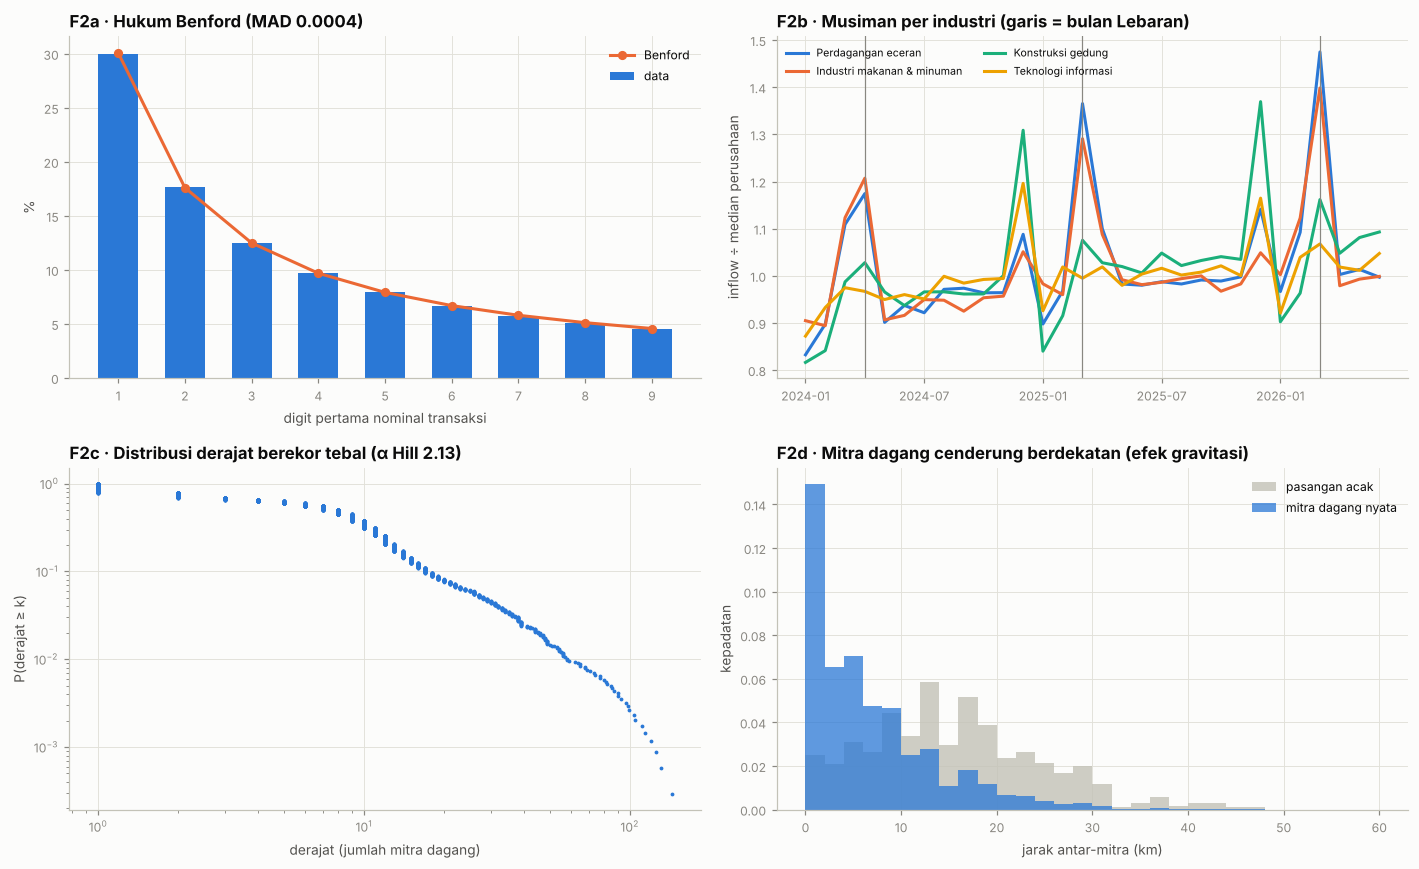

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
x9 = np.arange(1, 10)
ax[0, 0].bar(x9, ben_obs.values * 100, color=C['s1'], width=.6, label='data'); ax[0, 0].plot(x9, ben_exp * 100, color=C['s2'], marker='o', ms=5, label='Benford')
ax[0, 0].set(xticks=x9, xlabel='digit pertama nominal transaksi', ylabel='%', title=f'F2a · Hukum Benford (MAD {mad:.4f})'); ax[0, 0].legend()
show_ind = ['Perdagangan eceran', 'Industri makanan & minuman', 'Konstruksi gedung', 'Teknologi informasi']
for k, i_ in enumerate(show_ind): ax[0, 1].plot(range(len(MONTHS)), seas[i_].values, color=C[f's{k + 1}'], label=i_)
for m in ['2024-04', '2025-03', '2026-03']: ax[0, 1].axvline(MONTHS.index(m), color=C['muted'], lw=.8)
ax[0, 1].set_xticks(range(0, len(MONTHS), 6)); ax[0, 1].set_xticklabels(MONTHS[::6])
ax[0, 1].set(ylabel='inflow ÷ median perusahaan', title='F2b · Musiman per industri (garis = bulan Lebaran)'); ax[0, 1].legend(fontsize=7, ncol=2, loc='upper left')
vals = np.sort(deg.values); ccdf = 1 - np.arange(len(vals)) / len(vals)
ax[1, 0].loglog(vals, ccdf, '.', color=C['s1'], ms=3); ax[1, 0].set(xlabel='derajat (jumlah mitra dagang)', ylabel='P(derajat ≥ k)', title=f'F2c · Distribusi derajat berekor tebal (α Hill {hill:.2f})')
bins = np.linspace(0, 60, 31)
ax[1, 1].hist(d_rand, bins=bins, color=C['axis'], alpha=.8, label='pasangan acak', density=True); ax[1, 1].hist(d_real, bins=bins, color=C['s1'], alpha=.75, label='mitra dagang nyata', density=True)
ax[1, 1].set(xlabel='jarak antar-mitra (km)', ylabel='kepadatan', title='F2d · Mitra dagang cenderung berdekatan (efek gravitasi)'); ax[1, 1].legend()
plt.tight_layout(); save_fig('03_F2_kewajaran'); plt.show()

**Struktur graf untuk analisis lanjutan.** Grafik di bawah menunjukkan *ego network* salah satu anchor yang bermasalah (dideteksi dari data di F4b): pemasok diwarnai menurut besar ketergantungannya — bahan untuk analisis efek berantai di notebook 02/03.

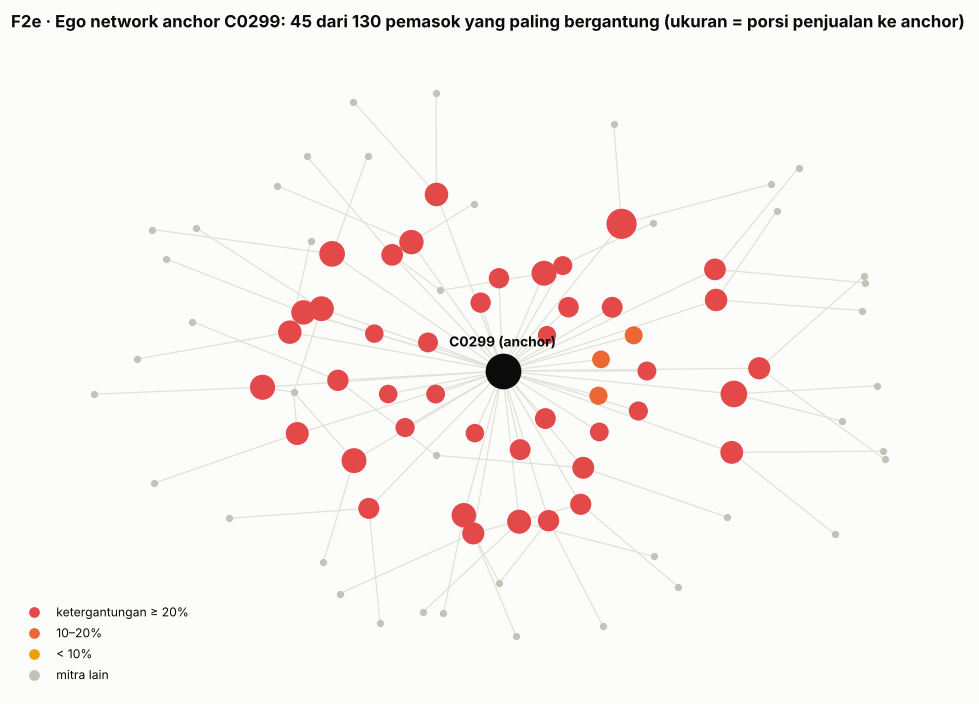

In [31]:
da_obs = gtl[gtl.is_distressed_anchor].company_id.tolist()
a0 = da_obs[0]
nbr_all = trade[(trade.target_id == a0) & trade.relationship_type.isin(['Customer', 'Distributor'])][['source_id', 'dependency_share']]
nbr = nbr_all.sort_values('dependency_share', ascending=False).head(45)          # 45 pemasok paling bergantung (agar terbaca)
EG = nx.Graph(); EG.add_node(a0)
for s_, d_ in nbr.values: EG.add_edge(a0, s_, w=d_)
for s_ in nbr.source_id[:25]:                                          # sebagian mitra lain dari pemasok tsb (lapis 2 ego)
    for t_ in trade[(trade.source_id == s_) & (trade.target_id != a0)].target_id.head(2): EG.add_edge(s_, t_, w=.05)
pos = nx.spring_layout(EG, seed=3, k=.35)
sh_map = dict(nbr.values)
fig, ax = plt.subplots(figsize=(9, 6.5)); ax.axis('off')
nx.draw_networkx_edges(EG, pos, ax=ax, edge_color=C['grid'], width=.8)
others = [n for n in EG if n != a0 and n not in sh_map]
nx.draw_networkx_nodes(EG, pos, nodelist=others, node_size=14, node_color=C['axis'], ax=ax)
sup_n = list(sh_map); cols = [C['s8'] if sh_map[n] >= .2 else C['s2'] if sh_map[n] >= .1 else C['s4'] for n in sup_n]
nx.draw_networkx_nodes(EG, pos, nodelist=sup_n, node_size=[40 + 400 * sh_map[n] for n in sup_n], node_color=cols, ax=ax)
nx.draw_networkx_nodes(EG, pos, nodelist=[a0], node_size=500, node_color=C['ink'], ax=ax)
ax.annotate(f'{a0} (anchor)', pos[a0], xytext=(0, 16), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=c_, label=l_) for c_, l_ in [(C['s8'], 'ketergantungan ≥ 20%'), (C['s2'], '10–20%'), (C['s4'], '< 10%'), (C['axis'], 'mitra lain')]],
          loc='lower left', fontsize=8)
ax.set_title(f'F2e · Ego network anchor {a0}: 45 dari {len(nbr_all)} pemasok yang paling bergantung (ukuran = porsi penjualan ke anchor)')
plt.tight_layout(); save_fig('04_F2e_ego_network_anchor'); plt.show()

### F2b. Uji statistik jaringan
Lapis F2 menunjukkan jaringan *tampak* realistis. Lapis ini mengujinya secara formal terhadap **hipotesis nol**: apakah struktur itu muncul karena desain rantai pasok (rantai nilai, jarak, klaster kota, grup usaha), atau hanya akibat distribusi jumlah mitra?

| Uji | Hipotesis nol & cara | Rujukan |
|---|---|---|
| Modularitas, klastering, transitivitas, asortativitas | 50 graf acak dengan **jumlah mitra tiap perusahaan sama persis** (*double-edge swap*); z-score & p empiris | Maslov & Sneppen (2002); Watts & Strogatz (1998); Newman (2002, 2006) |
| Bentuk ekor distribusi derajat | xmin dipilih dengan KS (ekor ≥ 10% node), lalu *likelihood ratio* Vuong: lognormal vs eksponensial, power-law vs lognormal | Clauset, Shalizi & Newman (2009) |
| Makna komunitas | NMI komunitas Louvain dengan kota/kabupaten dan industri vs 200 label acak | Danon dkk. (2005) |
| Homophily grup usaha | kemiripan indeks kesehatan teramati (DER, CR, NPM relatif-peer) sesama anggota grup vs 500 pengacakan keanggotaan grup | Khanna & Yafeh (2007) |

**Catatan:** p empiris terkecil = 1/(jumlah graf acak + 1). Uji ekor memakai pendekatan kontinu untuk derajat (bilangan bulat), cukup untuk membedakan "berekor berat" dari eksponensial. Hasil disimpan di `network_tests.csv` dan ikut dihitung di ringkasan bagian G.

In [32]:
from scipy import stats, optimize
from sklearn.metrics import normalized_mutual_info_score as NMI
NET = []
def net_add(uji, obs, null_mean, null_sd, z, p, target, ok, ref, catatan=''):
    NET.append(dict(uji=uji, observasi=obs, null_rata2=null_mean, null_sd=null_sd, z=z, p_value=p, target=target,
                    status='info' if ok is None else ('LOLOS' if ok else 'GAGAL'), rujukan=ref, catatan=catatan))
t_net = time.time()
# 1) ensemble graf acak berderajat sama (configuration model lewat double-edge swap)
N_NULL = 50
GUs = nx.Graph(GU); GUs.remove_edges_from(nx.selfloop_edges(GUs))
obs_m = dict(assort=nx.degree_assortativity_coefficient(GUs), clust=nx.average_clustering(GUs), trans=nx.transitivity(GUs), Q=Q)
null_m = {k: [] for k in obs_m}
for s_ in range(N_NULL):
    Gn = nx.Graph(GUs); nx.double_edge_swap(Gn, nswap=2 * Gn.number_of_edges(), max_tries=10 ** 7, seed=100 + s_)
    null_m['assort'].append(nx.degree_assortativity_coefficient(Gn)); null_m['clust'].append(nx.average_clustering(Gn))
    null_m['trans'].append(nx.transitivity(Gn)); null_m['Q'].append(nx.community.modularity(Gn, nx.community.louvain_communities(Gn, seed=s_)))
def zp(k):
    a = np.array(null_m[k]); z = (obs_m[k] - a.mean()) / a.std(ddof=1)
    p = (1 + np.sum(np.abs(a - a.mean()) >= abs(obs_m[k] - a.mean()))) / (N_NULL + 1)
    return a.mean(), a.std(ddof=1), z, p
for k, nama, target, cond, ref in [
        ('Q', 'modularitas Louvain vs graf acak berderajat sama', 'lebih tinggi, p < 0,05', lambda z, p: z > 0 and p < .05, 'Newman 2006; Blondel 2008'),
        ('clust', 'koefisien klastering rata-rata vs graf acak', 'lebih tinggi, p < 0,05', lambda z, p: z > 0 and p < .05, 'Watts & Strogatz 1998'),
        ('trans', 'transitivitas (klastering global) vs graf acak', 'lebih tinggi, p < 0,05', lambda z, p: z > 0 and p < .05, 'Watts & Strogatz 1998'),
        ('assort', 'asortativitas derajat vs graf acak berderajat sama', 'lebih disasortatif, p < 0,05', lambda z, p: z < 0 and p < .05, 'Newman 2002; Maslov & Sneppen 2002')]:
    m_, sd_, z_, p_ = zp(k)
    net_add(nama, obs_m[k], m_, sd_, z_, p_, target, cond(z_, p_), ref)

# 2) bentuk ekor distribusi derajat (Clauset, Shalizi & Newman 2009; pendekatan kontinu)
x_all = np.array([d for _, d in GUs.degree()], float)
def pl_fit(x, xmin):
    t = x[x >= xmin]; a = 1 + len(t) / np.sum(np.log(t / xmin)); return a, t
best = None
for xm in np.unique(x_all)[:-10]:
    a_, t_ = pl_fit(x_all, xm)
    if len(t_) < 0.10 * len(x_all): break                     # ekor minimal 10% node agar uji punya daya
    emp = np.arange(1, len(t_) + 1) / len(t_); th = 1 - (np.sort(t_) / xm) ** (1 - a_)
    D = np.max(np.abs(emp - th))
    if best is None or D < best[0]: best = (D, xm, a_)
D_ks, xmin, alpha = best; t = x_all[x_all >= xmin]; n_t = len(t)
ll_pl = np.log(alpha - 1) - np.log(xmin) - alpha * np.log(t / xmin)
lam = 1 / (t.mean() - xmin); ll_ex = np.log(lam) - lam * (t - xmin)
def nll_ln(p):
    mu, sg = p[0], abs(p[1]) + 1e-6
    return -np.sum(stats.norm.logpdf(np.log(t), mu, sg) - np.log(t) - stats.norm.logsf(np.log(xmin), mu, sg))
r_ = optimize.minimize(nll_ln, [np.log(t).mean(), np.log(t).std()], method='Nelder-Mead'); mu_, sg_ = r_.x[0], abs(r_.x[1])
ll_ln = stats.norm.logpdf(np.log(t), mu_, sg_) - np.log(t) - stats.norm.logsf(np.log(xmin), mu_, sg_)
def vuong(l1, l2):
    from scipy.special import erfc
    d = l1 - l2; R = d.sum(); p = erfc(abs(R) / (np.sqrt(2 * len(d)) * d.std())); return R, p
R_le, p_le = vuong(ll_ln, ll_ex); R_pl, p_pl = vuong(ll_pl, ll_ln)
net_add(f'ekor derajat: lognormal vs eksponensial (k ≥ {int(xmin)}, n = {n_t})', R_le, np.nan, np.nan, np.nan, p_le, 'R > 0 & p < 0,05 (ekor lebih berat dari eksponensial)',
        R_le > 0 and p_le < .05, 'Clauset, Shalizi & Newman 2009')
net_add(f'ekor derajat: power-law (α = {alpha:.2f}) vs lognormal', R_pl, np.nan, np.nan, np.nan, p_pl, 'informasi (R < 0 → lognormal lebih cocok)', None,
        'Clauset, Shalizi & Newman 2009', 'jaringan produksi riil sering lebih cocok lognormal daripada power-law murni')

# 3) apakah komunitas bermakna? NMI dengan kota & industri vs label diacak
nodes_c = [n for c in comms for n in c]; lab_c = np.concatenate([[k] * len(c) for k, c in enumerate(comms)])
city_of = geo.set_index('location_id').city
city_l = np.array([city_of[node_loc[n]] for n in nodes_c]); ind_l = np.array([node_ind[n] for n in nodes_c])
rng_n = np.random.default_rng(1)
for nama, lab in [('kota/kabupaten', city_l), ('industri', ind_l)]:
    o_ = NMI(lab_c, lab); nul = np.array([NMI(lab_c, rng_n.permutation(lab)) for _ in range(200)])
    z_ = (o_ - nul.mean()) / nul.std(ddof=1); p_ = (1 + np.sum(nul >= o_)) / 201
    net_add(f'komunitas sejalan dengan {nama} (NMI)', o_, nul.mean(), nul.std(ddof=1), z_, p_, 'lebih tinggi dari label acak, p < 0,05', z_ > 0 and p_ < .05, 'Danon dkk. 2005; uji permutasi')

# 4) homophily grup usaha pada data TERAMATI: kemiripan rasio keuangan sesama anggota grup vs grup acak
cc_g = comp.set_index('company_id'); grp_keys = [cc_g.industry.reindex(f25.index), cc_g.size_class_reference.reindex(f25.index)]
ratios_g = {'DER': -np.log((f25.total_debt_idr_bn / f25.total_equity_idr_bn).clip(lower=.01)),        # tanda dibalik: makin tinggi makin sehat
            'CR': np.log((f25.current_assets_idr_bn / f25.current_liabilities_idr_bn).clip(lower=.01)), 'NPM': f25.net_profit_idr_bn / f25.revenue_idr_bn}
def peer_z_(s, grp):
    med = s.groupby(grp).transform('median'); iqr = s.groupby(grp).transform(lambda x: x.quantile(.75) - x.quantile(.25)).replace(0, np.nan)
    return (s - med) / iqr
health_idx = pd.concat([peer_z_(v, grp_keys).clip(-5, 5) for v in ratios_g.values()], axis=1).mean(1)   # indeks kesehatan teramati relatif-peer
zg = pd.DataFrame({'z': health_idx, 'grp': cc_g.business_group.reindex(f25.index)}).dropna()
def icc(df):
    g_ = df.groupby('grp').z; return g_.mean().var() / df.z.var()
icc_o = icc(zg); nul = np.array([icc(zg.assign(grp=rng_n.permutation(zg.grp.values))) for _ in range(500)])
z_ = (icc_o - nul.mean()) / nul.std(ddof=1); p_ = (1 + np.sum(nul >= icc_o)) / 501
net_add(f'homophily grup: kemiripan indeks kesehatan (DER, CR, NPM relatif-peer) sesama anggota (n = {len(zg)})', icc_o, nul.mean(), nul.std(ddof=1), z_, p_, 'p < 0,05', p_ < .05,
        'Khanna & Yafeh 2007; uji permutasi')
gH2 = pd.DataFrame({'High': yH, 'grp': cc_g.business_group.reindex(yH.index)}).dropna()
def hom(df):
    peer = df.groupby('grp').High.transform('sum') - df.High; return df[peer > 0].High.mean() - df[peer == 0].High.mean()
h_o = hom(gH2); nul = np.array([hom(gH2.assign(High=rng_n.permutation(gH2.High.values))) for _ in range(1000)])
p_ = (1 + np.sum(nul >= h_o)) / 1001
net_add(f'homophily grup pada label High (n = {len(gH2)} nasabah kredit dalam grup)', h_o, np.nanmean(nul), np.nanstd(nul), (h_o - np.nanmean(nul)) / np.nanstd(nul), p_,
        'informasi (sampel kecil)', None, 'Khanna & Yafeh 2007; uji permutasi', 'sinyal grup lebih jelas di rasio keuangan daripada di label karena hanya ±90 nasabah kredit dalam grup')

NETDF = pd.DataFrame(NET)
REPORT.mkdir(parents=True, exist_ok=True); NETDF.to_csv(REPORT / 'network_tests.csv', index=False)
print(f"F2b: {int((NETDF.status == 'LOLOS').sum())} lolos · {int((NETDF.status == 'GAGAL').sum())} gagal · {int((NETDF.status == 'info').sum())} informasi · {time.time() - t_net:.0f} detik")
NETDF.assign(observasi=NETDF.observasi.round(4), null_rata2=NETDF.null_rata2.round(4), z=NETDF.z.round(1), p_value=NETDF.p_value.map(lambda p: f'{p:.1e}'))[
    ['uji', 'observasi', 'null_rata2', 'z', 'p_value', 'target', 'status', 'rujukan']].style.map(
    lambda s: f"color: {STATUS[s]}; font-weight: bold" if s in STATUS else '', subset=['status']).hide(axis='index')

F2b: 8 lolos · 0 gagal · 2 informasi · 100 detik


uji,observasi,null_rata2,z,p_value,target,status,rujukan
modularitas Louvain vs graf acak berderajat sama,0.487900,0.284800,95.700000,2.0e-02,"lebih tinggi, p < 0,05",LOLOS,Newman 2006; Blondel 2008
koefisien klastering rata-rata vs graf acak,0.022200,0.013000,11.300000,2.0e-02,"lebih tinggi, p < 0,05",LOLOS,Watts & Strogatz 1998
transitivitas (klastering global) vs graf acak,0.020100,0.015200,10.200000,2.0e-02,"lebih tinggi, p < 0,05",LOLOS,Watts & Strogatz 1998
asortativitas derajat vs graf acak berderajat sama,-0.137800,-0.023800,-17.900000,2.0e-02,"lebih disasortatif, p < 0,05",LOLOS,Newman 2002; Maslov & Sneppen 2002
"ekor derajat: lognormal vs eksponensial (k ≥ 8, n = 1734)",243.811500,nan,nan,3.3e-17,"R > 0 & p < 0,05 (ekor lebih berat dari eksponensial)",LOLOS,"Clauset, Shalizi & Newman 2009"
ekor derajat: power-law (α = 2.97) vs lognormal,-0.151000,nan,nan,7.2e-01,informasi (R < 0 → lognormal lebih cocok),info,"Clauset, Shalizi & Newman 2009"
komunitas sejalan dengan kota/kabupaten (NMI),0.555200,0.003400,800.000000,5.0e-03,"lebih tinggi dari label acak, p < 0,05",LOLOS,Danon dkk. 2005; uji permutasi
komunitas sejalan dengan industri (NMI),0.012300,0.004600,10.200000,5.0e-03,"lebih tinggi dari label acak, p < 0,05",LOLOS,Danon dkk. 2005; uji permutasi
"homophily grup: kemiripan indeks kesehatan (DER, CR, NPM relatif-peer) sesama anggota (n = 154)",0.471000,0.337500,2.000000,3.4e-02,"p < 0,05",LOLOS,Khanna & Yafeh 2007; uji permutasi
homophily grup pada label High (n = 93 nasabah kredit dalam grup),0.004400,0.000700,0.000000,5.4e-01,informasi (sampel kecil),info,Khanna & Yafeh 2007; uji permutasi


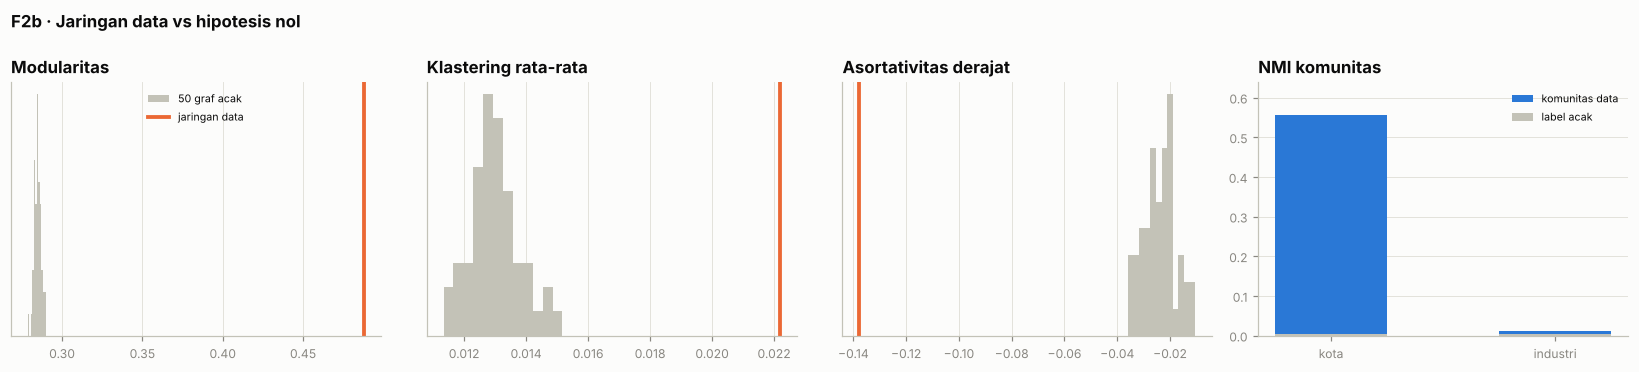

In [33]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a_, k, judul in [(ax[0], 'Q', 'Modularitas'), (ax[1], 'clust', 'Klastering rata-rata'), (ax[2], 'assort', 'Asortativitas derajat')]:
    a_.hist(null_m[k], bins=12, color=C['axis'], label='50 graf acak'); a_.axvline(obs_m[k], color=C['s2'], lw=2.5, label='jaringan data')
    a_.set(title=judul, yticks=[]); a_.grid(axis='y', visible=False)
ax[0].legend(loc='upper center', fontsize=7)
nm_ = NETDF[NETDF.uji.str.startswith('komunitas')]
ax[3].bar(['kota', 'industri'], nm_.observasi.values, color=C['s1'], width=.5, label='komunitas data')
ax[3].bar(['kota', 'industri'], nm_.null_rata2.values, color=C['axis'], width=.5, label='label acak')
ax[3].set(title='NMI komunitas', ylim=(0, max(.6, nm_.observasi.max() * 1.15))); ax[3].legend(fontsize=7); ax[3].grid(axis='x', visible=False)
plt.suptitle('F2b · Jaringan data vs hipotesis nol', x=.01, ha='left', fontweight='bold', fontsize=11)
plt.tight_layout(); save_fig('04b_F2b_uji_jaringan'); plt.show()

### F3. Uji kondisi ekstrem, sensitivitas, dan multi-*seed*
Sargent (2013) menyarankan menguji model simulasi pada **kondisi ekstrem** (apakah reaksinya logis), **variasi parameter** (apakah arah perubahannya benar), dan **validitas internal** (apakah hasil stabil bila diulang dengan bilangan acak berbeda). Generator dijalankan ulang dalam mode ringan (tanpa transaksi):
- **Krisis** (`health_shift = −0,8`) harus menaikkan porsi High, menaikkan DER, menurunkan current ratio, dan menambah kejadian distress; **boom** sebaliknya.
- **Faktor tak teramati** σ makin besar → plafon akurasi makin rendah.
- **Skala gravitasi** makin kecil → mitra dagang makin dekat.
- **3 seed berbeda** → plafon akurasi stabil (sd ≤ 0,03); dan **satu dunia lengkap dengan seed lain** → pola tertanam (anchor, efek berantai, sinyal dini) tetap bisa dipulihkan — memastikan temuan EDA nanti bukan kebetulan satu seed.

In [34]:
L = 'F3 Kondisi ekstrem'
light = lambda seed=SEED, **kw: generate(seed, with_tx=False, **kw)[0]
oracle_f1 = lambda d: f1_score(d['gt_risk'].dropna(subset=['observed_label']).observed_label, d['gt_risk'].dropna(subset=['observed_label']).oracle_class, average='macro')
def ratios(d):
    f = d['financials'][d['financials'].fiscal_year == 2025]
    return (f.total_debt_idr_bn / f.total_equity_idr_bn).median(), (f.current_assets_idr_bn / f.current_liabilities_idr_bn).median()
t0 = time.time()
scen = {'boom': light(health_shift=.8), 'normal': light(), 'krisis': light(health_shift=-.8)}
hs = {k: (d['gt_risk'].true_risk_class == 'High').mean() for k, d in scen.items()}
add(L, 'generator', 'porsi High: boom < normal < krisis', ' < '.join(f'{k} {v:.0%}' for k, v in hs.items()), 'monoton naik', hs['boom'] < hs['normal'] < hs['krisis'], 'Sargent 2013')
(db, cb), (dc, cc) = ratios(scen['normal']), ratios(scen['krisis'])
add(L, 'generator', 'krisis: DER naik & current ratio turun (median)', f'DER {db:.2f}→{dc:.2f}; CR {cb:.2f}→{cc:.2f}', 'DER↑ CR↓', dc > db and cc < cb, 'Sargent 2013')
nd = {k: (d['gt_company_latent'].regime == 'distress').mean() for k, d in scen.items()}
add(L, 'generator', 'krisis menambah kejadian distress', f"{nd['normal']:.1%} → {nd['krisis']:.1%}", 'naik', nd['krisis'] > nd['normal'], 'Sargent 2013')
orc = {sg: oracle_f1(light(sigma_unobserved=sg)) for sg in (0.10, 0.25, 0.45, 0.70)}
add(L, 'generator', 'σ faktor tak teramati ↑ → plafon macro-F1 ↓', ' > '.join(f'{v:.2f}' for v in orc.values()), 'monoton turun', all(np.diff(list(orc.values())) < 0), 'Sargent 2013')
def med_dist(d):
    r_ = d['relationships']; r_ = r_[r_.relationship_type.isin(['Customer', 'Supplier', 'Distributor']) & r_.layer_from_core.eq(1)]
    lc = {**dict(zip(d['companies'].company_id, d['companies'].location_id)), **dict(zip(d['network_entities'].entity_id, d['network_entities'].location_id))}
    return float(np.median(dist(r_.source_id.map(lc), r_.target_id.map(lc))))
gdist = {lam: med_dist(light(gravity_km=lam)) for lam in (4, 12, 40)}
add(L, 'generator', 'skala gravitasi ↑ → jarak mitra ↑ (median km)', ' < '.join(f'λ{k}: {v:.1f}' for k, v in gdist.items()), 'monoton naik', all(np.diff(list(gdist.values())) > 0), 'Sargent 2013')
ms = {sd: oracle_f1(light(sd)) for sd in (11, 22, 33)}
add(L, 'generator', 'multi-seed (3 seed): plafon macro-F1 stabil', f"{np.mean(list(ms.values())):.3f} ± {np.std(list(ms.values())):.3f}", 'sd ≤ 0,03', np.std(list(ms.values())) <= .03, 'Sargent 2013 (validitas internal)')


def pattern_metrics(d):
    """Tiga pola tertanam yang dihitung dari data TERAMATI saja (dipakai lagi di F4b)."""
    c_, t_, r_ = d['companies'], d['transactions'], d['relationships']
    t_ = t_.assign(m=t_.transaction_date.str[:7], day=t_.transaction_date.str[8:10].astype(int))
    cl_ = set(c_[c_.customer_type != 'Prospect'].company_id)
    i_ = t_[t_.direction.eq('IN') & (t_.amount_idr_mn > 0)].groupby(['company_id', 'm']).amount_idr_mn.sum().unstack().fillna(0)
    dd = i_[[m for m in i_.columns if m >= '2025-10']].median(1) / i_[[m for m in i_.columns if '2024-07' <= m <= '2025-06']].median(1).replace(0, np.nan) - 1
    an_ = c_[c_.is_anchor_candidate & c_.customer_type.ne('Prospect')].company_id
    bad_ = list(dd.reindex(an_).dropna().sort_values().index[:2])
    hit_ = len(set(bad_) & set(d['gt_company_latent'].query('is_distressed_anchor').company_id))
    b_ = r_[r_.relationship_type.isin(['Customer', 'Distributor']) & r_.source_id.str.startswith('C')]
    ex_ = b_[b_.target_id.isin(bad_)].groupby('source_id').dependency_share.sum()
    E_ = pd.DataFrame({'e': ex_.reindex(list(cl_)).fillna(0), 'd': dd.reindex(list(cl_))}).drop(index=bad_, errors='ignore').dropna()
    dose_ = E_[E_.e >= .2].d.median() - E_[E_.e == 0].d.median()
    tl_ = t_[t_.transaction_type.eq('Tax') & t_.m.isin(sorted(t_.m.unique())[-6:])].groupby('company_id').day.apply(lambda s: (s > 15).mean())
    rk_ = d['risk_labels'].set_index('company_id').risk_class
    tr_ = tl_.groupby(rk_).mean()
    return hit_, dose_, tr_['High'] / max(tr_['Low'], 1e-3)


t1 = time.time(); alt = generate(7)[0]
hit7, dose7, tax7 = pattern_metrics(alt)
add(L, 'generator (seed 7, data lengkap)', 'pola tertanam tetap muncul di seed lain', f'anchor {hit7}/2 · dosis–respons {dose7:+.0%} · pajak telat High/Low {tax7:.1f}×',
    'anchor 2/2, dosis ≤ −10 poin, rasio ≥ 2×', hit7 == 2 and dose7 <= -.10 and tax7 >= 2, 'Sargent 2013 (validitas internal)')
print(f'(seed 7 lengkap: {time.time() - t1:.0f} detik)'); del alt
print(f'({time.time() - t0:.0f} detik untuk {3 + 4 + 3 + 3 + 1} dunia tambahan)')
show(L)

(seed 7 lengkap: 73 detik)
(134 detik untuk 14 dunia tambahan)
F3 Kondisi ekstrem: 7 lolos · 0 gagal · 0 informasi


tabel,uji,nilai,target,status,rujukan
generator,porsi High: boom < normal < krisis,boom 6% < normal 18% < krisis 41%,monoton naik,LOLOS,Sargent 2013
generator,krisis: DER naik & current ratio turun (median),DER 1.22→1.81; CR 1.41→1.17,DER↑ CR↓,LOLOS,Sargent 2013
generator,krisis menambah kejadian distress,6.2% → 9.0%,naik,LOLOS,Sargent 2013
generator,σ faktor tak teramati ↑ → plafon macro-F1 ↓,0.90 > 0.83 > 0.73 > 0.66,monoton turun,LOLOS,Sargent 2013
generator,skala gravitasi ↑ → jarak mitra ↑ (median km),λ4: 2.6 < λ12: 6.9 < λ40: 9.7,monoton naik,LOLOS,Sargent 2013
generator,multi-seed (3 seed): plafon macro-F1 stabil,0.824 ± 0.005,"sd ≤ 0,03",LOLOS,Sargent 2013 (validitas internal)
"generator (seed 7, data lengkap)",pola tertanam tetap muncul di seed lain,anchor 2/2 · dosis–respons -20% · pajak telat High/Low 3.3×,"anchor 2/2, dosis ≤ −10 poin, rasio ≥ 2×",LOLOS,Sargent 2013 (validitas internal)


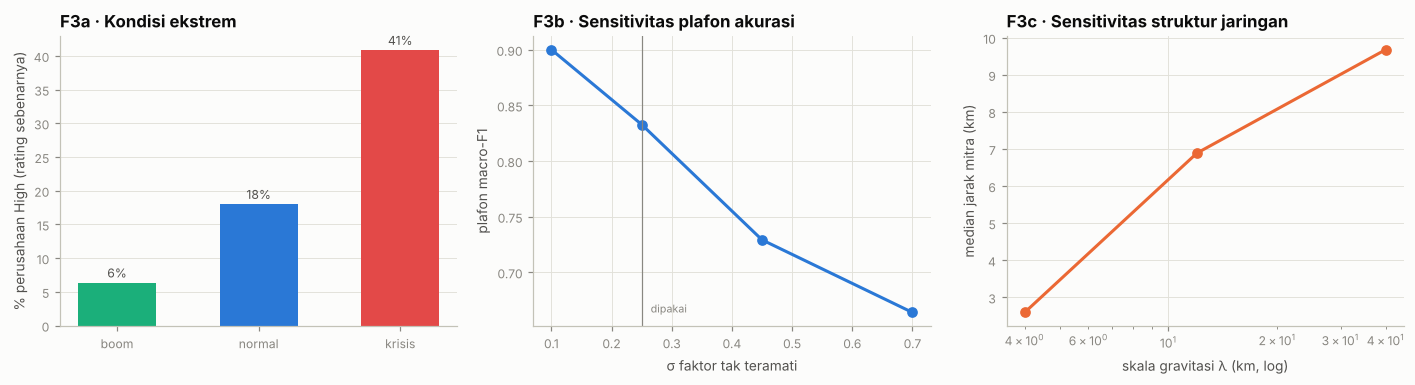

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(list(hs), [100 * v for v in hs.values()], color=[C['s3'], C['s1'], C['s8']], width=.55)
for i_, v in enumerate(hs.values()): ax[0].text(i_, 100 * v + .8, f'{v:.0%}', ha='center', fontsize=8, color=C['ink2'])
ax[0].set(ylabel='% perusahaan High (rating sebenarnya)', title='F3a · Kondisi ekstrem'); ax[0].grid(axis='x', visible=False)
ax[1].plot(list(orc), list(orc.values()), marker='o', color=C['s1']); ax[1].axvline(cfg['sigma_unobserved'], color=C['muted'], lw=.8)
ax[1].text(cfg['sigma_unobserved'] + .01, min(orc.values()), ' dipakai', fontsize=7, color=C['muted'])
ax[1].set(xlabel='σ faktor tak teramati', ylabel='plafon macro-F1', title='F3b · Sensitivitas plafon akurasi')
ax[2].plot(list(gdist), list(gdist.values()), marker='o', color=C['s2']); ax[2].set_xscale('log')
ax[2].set(xlabel='skala gravitasi λ (km, log)', ylabel='median jarak mitra (km)', title='F3c · Sensitivitas struktur jaringan')
plt.tight_layout(); save_fig('05_F3_kondisi_ekstrem_sensitivitas'); plt.show()

### F4. Sinyal: bisa dipelajari, tidak trivial, dan pola tertanam bisa dipulihkan
1. **Plafon (oracle)**: macro-F1 model "sempurna" yang mengetahui skor laten tetapi tidak mengetahui faktor tak teramati dan kesalahan rating — batas atas yang realistis (bukan 1,0).
2. **Dapat dipelajari tapi tidak trivial**: model sederhana dari laporan keuangan saja harus jauh di atas acak (0,33) tetapi jauh di bawah sempurna (Wu & Keogh, 2021 mengkritik *benchmark* yang bisa diselesaikan aturan satu baris).
3. **Utilitas sintetis (pMSE)**: classifier mencoba membedakan prospect dari nasabah memakai fitur keuangan. AUC ≈ 0,5 berarti keduanya identik (tidak realistis); AUC terlalu tinggi berarti dua dunia berbeda. Woo dkk. (2009) & Snoke dkk. (2018) memakai *propensity score mean-squared error* untuk mengukur ini.
4. **MNAR**: laporan lebih sering hilang pada perusahaan berisiko (Rubin, 1976).
5. **Anomali tidak trivial**: aturan satu baris ("inflow maks ÷ median") tidak boleh sudah menemukan semua kejadian.
6. **Konsistensi kausal** antartabel: konversi RM ↔ produk, kebutuhan ↔ adopsi, transaksi ↔ jaringan, catatan kunjungan ↔ isu.

In [36]:
L = 'F4 Sinyal'
X = pd.DataFrame({'lDER': np.log((f25.total_debt_idr_bn / f25.total_equity_idr_bn.clip(lower=.01)).clip(.01)),
                  'lCR': np.log((f25.current_assets_idr_bn / f25.current_liabilities_idr_bn.clip(lower=.01)).clip(.01)),
                  'lICR': np.log((f25.ebit_idr_bn / f25.interest_expense_idr_bn.clip(lower=1e-3)).clip(.01)),
                  'NPM': f25.net_profit_idr_bn / f25.revenue_idr_bn, 'growth': f25.revenue_idr_bn / f24.revenue_idr_bn - 1,
                  'lrev': np.log1p(f25.revenue_idr_bn)}).replace([np.inf, -np.inf], np.nan)
X = X.join(pd.get_dummies(comp.set_index('company_id').industry, prefix='i').astype(int)); X = X.fillna(X.median())
y3 = rl.set_index('company_id').risk_class.map({'Low': 0, 'Medium': 1, 'High': 2}); Xl = X.reindex(y3.index).fillna(X.median())
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
gc = gtr.dropna(subset=['observed_label']); ORACLE = f1_score(gc.observed_label, gc.oracle_class, average='macro')
add(L, 'risk_labels', 'plafon macro-F1 (oracle: tahu skor laten)', f'{ORACLE:.3f}', '0,78–0,88', .78 <= ORACLE <= .88, 'Bayes error')
fin_f1 = {}
for nm, m in [('LR', make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))), ('RF', RandomForestClassifier(400, min_samples_leaf=3, random_state=0, n_jobs=-1))]:
    fin_f1[nm] = f1_score(y3, cross_val_predict(m, Xl, y3, cv=cv5), average='macro')
    add(L, 'risk_labels', f'risiko dari laporan keuangan saja ({nm}, 5-fold)', f'macro-F1 {fin_f1[nm]:.3f}', '0,50–0,75 (tidak trivial)', .50 <= fin_f1[nm] <= .75, 'Wu & Keogh 2021')
add(L, 'gt_client_risk', 'kesalahan rating tercatat', f'{gc.label_flipped.mean():.1%}', '2–6%', .02 <= gc.label_flipped.mean() <= .06, 'Northcutt dkk. 2021')
gp = data['gt_prospect_risk'].set_index('company_id').true_risk_class; has = gp.index.isin(f25.index)
hi_m, lo_m = (~has[gp.values == 'High']).mean(), (~has[gp.values == 'Low']).mean()
add(L, 'financials', 'laporan hilang MNAR: % hilang High vs Low (prospect)', f'{hi_m:.0%} vs {lo_m:.0%}', 'High ≥ 2× Low', hi_m >= 2 * max(lo_m, .01), 'Rubin 1976')
Xa = pd.concat([X.reindex(rl.company_id).dropna(), X.reindex(gp.index[has])]); ya = np.r_[np.zeros(len(X.reindex(rl.company_id).dropna())), np.ones(has.sum())]
pa = cross_val_predict(RandomForestClassifier(300, min_samples_leaf=5, random_state=0, n_jobs=-1), Xa, ya, cv=cv5, method='predict_proba')[:, 1]
pmse = float(np.mean((pa - ya.mean()) ** 2)); auc_p = roc_auc_score(ya, pa)
add(L, 'companies', 'prospect vs nasabah: AUC propensity / pMSE', f'AUC {auc_p:.3f} / pMSE {pmse:.4f}', 'AUC 0,60–0,80 (beda wajar)', .60 <= auc_p <= .80, 'Woo dkk. 2009; Snoke dkk. 2018')
obs_in = inn.loc[[c for c in inn.index if c in cli_ids]]
up_ids = set(gta[gta.direction.eq('up')].company_id); dn_ids = set(gta[gta.direction.eq('down')].company_id)
s_up = obs_in.loc[:, '2025-10':].max(1) / obs_in.loc[:, :'2025-06'].median(1).replace(0, np.nan)
s_dn = obs_in.loc[:, '2025-10':].min(1) / obs_in.loc[:, :'2025-03'].median(1).replace(0, np.nan)
a_up = roc_auc_score(obs_in.index.isin(list(up_ids)), s_up.fillna(0)); a_dn = roc_auc_score(obs_in.index.isin(list(dn_ids)), -s_dn.fillna(1))
add(L, 'gt_anomaly_events', 'aturan 1 baris menemukan anomali NAIK (AUC)', f'{a_up:.3f}', '< 0,80', a_up < .80, 'Wu & Keogh 2021')
add(L, 'gt_anomaly_events', 'aturan 1 baris menemukan anomali TURUN (AUC)', f'{a_dn:.3f}', '< 0,80', a_dn < .80, 'Wu & Keogh 2021')
add(L, 'gt_anomaly_events', 'jenis kejadian', ', '.join(f'{k} {v}' for k, v in gta.event_type.value_counts().items()), '≥ 6 jenis', gta.event_type.nunique() >= 6, 'Why Now')
rate = outc.adopted_jul_sep_2026.mean()
add(L, 'outcome', 'tingkat adopsi produk Jul–Sep', f'{rate:.1%}', '8–18%', .08 <= rate <= .18, 'kewajaran')
o_ = outc.merge(gtn, on=['company_id', 'product_id']); a1, a0_ = o_[o_.true_need == 1].adopted_jul_sep_2026.mean(), o_[o_.true_need == 0].adopted_jul_sep_2026.mean()
add(L, 'outcome × gt_product_need', 'adopsi bila butuh vs tidak', f'{a1:.1%} vs {a0_:.1%}', 'lift ≥ 3×', a1 >= 3 * max(a0_, 1e-3), 'konsistensi kausal')
bad_need = ph.merge(gtn, on=['company_id', 'product_id']).true_need.eq(0).mean()
add(L, 'product_holdings', 'produk dimiliki tanpa kebutuhan', f'{bad_need:.1%}', '≤ 5%', bad_need <= .05, 'konsistensi kausal')
cv_ = act[act.converted.eq(1) & act.track.eq('Deepening')].groupby(['party_id', 'product_id']).contact_date.min().str[:7].reset_index()
mm = cv_.merge(ph, left_on=['party_id', 'product_id'], right_on=['company_id', 'product_id'], how='left'); okc = (mm.open_month == mm.contact_date).mean()
add(L, 'rm_action_log × holdings', 'konversi RM tercatat sebagai produk baru (bulan sama)', f'{okc:.0%}', '100%', okc >= .99, 'konsistensi kausal')
t3 = tx[tx.transaction_type.isin(['Collection', 'Supplier payment']) & tx.counterparty_id.astype(str).str.match(r'^[CE]\d') & tx.data_visibility.str.startswith('Full')]
pairs = set(zip(rel.source_id, rel.target_id)); inrel = np.mean([(a, b) in pairs for a, b in zip(t3.company_id, t3.counterparty_id)])
add(L, 'transactions × relationships', 'counterparty transaksi ada di jaringan', f'{inrel:.0%}', '≥ 95%', inrel >= .95, 'konsistensi kausal')
reg = (pay.groupby('company_id').m.nunique() >= 27).mean()
add(L, 'transactions', 'payroll rutin (≥ 27 dari 30 bulan)', f'{reg:.0%} nasabah', '≥ 95%', reg >= .95, 'pola gajian')
neg = gv[gv.present.eq(0)].visit_id.nunique() / len(vn); se_n = np.sqrt(.4 * .6 / len(vn))
add(L, 'rm_visit_notes', 'catatan dengan kalimat negasi (spesifikasi 40%)', f'{neg:.0%} (n={len(vn)})', f'40% ± 3 SE ({.4 - 3 * se_n:.0%}–{.4 + 3 * se_n:.0%})', abs(neg - .4) <= 3 * se_n, 'verifikasi spesifikasi')
rows_ = []
for v in vn.itertuples():
    t_ = v.note_text.lower(); truth = set(gv[(gv.visit_id == v.visit_id) & gv.present.eq(1)].issue_id)
    pred = {r.issue_id for r in im.itertuples() if any(k in t_ for k in r.keywords.split('|'))}
    rows_.append((len(pred & truth), len(pred - truth), len(truth - pred)))
tp_, fp_, fn_ = np.sum(rows_, 0); p_, r_ = tp_ / max(tp_ + fp_, 1), tp_ / max(tp_ + fn_, 1); kf1 = 2 * p_ * r_ / max(p_ + r_, 1e-9)
add(L, 'rm_visit_notes', 'baseline kata kunci mengekstrak isu (F1)', f'P {p_:.2f} · R {r_:.2f} · F1 {kf1:.2f}', '0,40–0,85 (ada ruang untuk LLM)', .40 <= kf1 <= .85, 'ruang perbaikan GenAI')
cli_loc = comp[comp.customer_type != 'Prospect'].groupby('location_id').size().reindex(geo.location_id, fill_value=0)
pen = cli_loc / geo.set_index('location_id').corporate_count; nob = ~geo.set_index('location_id').index.isin(br.location_id)
hit = pd.Series(nob, index=geo.location_id)[pen.sort_values().index[:8]].mean()
add(L, 'geography × branches', 'kecamatan penetrasi terendah tanpa cabang', f'{hit:.0%} dari 8 terendah', '≥ 50%', hit >= .5, 'white-space tertanam')
show(L)

F4 Sinyal: 18 lolos · 0 gagal · 0 informasi


tabel,uji,nilai,target,status,rujukan
risk_labels,plafon macro-F1 (oracle: tahu skor laten),0.833,"0,78–0,88",LOLOS,Bayes error
risk_labels,"risiko dari laporan keuangan saja (LR, 5-fold)",macro-F1 0.634,"0,50–0,75 (tidak trivial)",LOLOS,Wu & Keogh 2021
risk_labels,"risiko dari laporan keuangan saja (RF, 5-fold)",macro-F1 0.610,"0,50–0,75 (tidak trivial)",LOLOS,Wu & Keogh 2021
gt_client_risk,kesalahan rating tercatat,4.4%,2–6%,LOLOS,Northcutt dkk. 2021
financials,laporan hilang MNAR: % hilang High vs Low (prospect),40% vs 9%,High ≥ 2× Low,LOLOS,Rubin 1976
companies,prospect vs nasabah: AUC propensity / pMSE,AUC 0.693 / pMSE 0.0244,"AUC 0,60–0,80 (beda wajar)",LOLOS,Woo dkk. 2009; Snoke dkk. 2018
gt_anomaly_events,aturan 1 baris menemukan anomali NAIK (AUC),0.763,"< 0,80",LOLOS,Wu & Keogh 2021
gt_anomaly_events,aturan 1 baris menemukan anomali TURUN (AUC),0.780,"< 0,80",LOLOS,Wu & Keogh 2021
gt_anomaly_events,jenis kejadian,"expansion 330, spike 198, contagion 142, distress 125, early_warning 125, wallet_erosion 115, buyer_exit 95",≥ 6 jenis,LOLOS,Why Now
outcome,tingkat adopsi produk Jul–Sep,10.6%,8–18%,LOLOS,kewajaran


### F4b. Pemulihan pola tertanam (*parameter recovery*)
Gagasan dari validasi perangkat lunak statistik (Cook, Gelman & Rubin, 2006; Talts dkk., 2018): bangkitkan data dari parameter yang diketahui, lalu periksa apakah pola itu **bisa ditemukan kembali hanya dari data teramati**. Kalau tidak bisa, EDA dan model di notebook berikutnya tidak akan menemukan apa-apa; kalau bisa terlalu sempurna, polanya trivial.

| Pola | Cara memulihkan dari data teramati | Dipakai di |
|---|---|---|
| Level rasio per industri | AUC DER relatif-peer > AUC DER mentah | FE: rasio relatif-peer |
| Kas ketat & sinyal dini | % pajak telat & payroll ≥ tgl 28 pada High vs Low; tanggal payroll bergeser sebelum inflow turun | FE: sinyal dini pembayaran |
| Konsentrasi pembeli | % High naik dengan porsi pembeli terbesar | FE/graf: konsentrasi |
| Efek berantai | anchor bermasalah terdeteksi dari inflow; pemasok makin terpapar makin turun | graf: eksposur ke anchor |
| Erosi wallet share | inflow BNI turun tapi omzet naik → mayoritas memang pindah bank | FE: divergensi |
| Grup usaha | rating High "menular" dalam grup | graf: homophily |

In [37]:
L = 'F4b Pemulihan pola'
def peer_z(s, grp):
    med = s.groupby(grp).transform('median'); iqr = s.groupby(grp).transform(lambda x: x.quantile(.75) - x.quantile(.25)).replace(0, np.nan)
    return (s - med) / iqr
cc_ = comp.set_index('company_id')
lder = np.log((f25.total_debt_idr_bn / f25.total_equity_idr_bn).clip(lower=.01))
pz = peer_z(lder, [cc_.industry.reindex(lder.index), cc_.size_class_reference.reindex(lder.index)])
ix_ = yH.index.intersection(lder.index)
auc_raw, auc_peer = roc_auc_score(yH[ix_], lder[ix_]), roc_auc_score(yH[ix_], pz[ix_].fillna(0))
add(L, 'financials', 'DER relatif-peer lebih informatif daripada DER mentah (AUC High)', f'{auc_raw:.3f} → {auc_peer:.3f}', 'naik ≥ 0,03', auc_peer - auc_raw >= .03, 'pola level struktural')
taxd = tx[tx.transaction_type.eq('Tax')].groupby(['company_id', 'm']).day.max()
paym = pay.groupby(['company_id', 'm']).day.max()
last6 = MONTHS[-6:]
tl = taxd[taxd.index.get_level_values(1).isin(last6)].gt(15).groupby(level=0).mean()
pl_ = paym[paym.index.get_level_values(1).isin(MONTHS[-12:])].ge(28).groupby(level=0).mean()
rk = rl.set_index('company_id').risk_class
tl_r, pl_r = tl.groupby(rk).mean(), pl_.groupby(rk).mean()
add(L, 'transactions', '% pajak telat (6 bln): High vs Low', f"{tl_r['High']:.0%} vs {tl_r['Low']:.0%}", 'High ≥ 2× Low', tl_r['High'] >= 2 * tl_r['Low'], 'early-warning system')
add(L, 'transactions', '% payroll ≥ tgl 28 (12 bln): High vs Low', f"{pl_r['High']:.0%} vs {pl_r['Low']:.0%}", 'High ≥ 2× Low', pl_r['High'] >= 2 * pl_r['Low'], 'early-warning system')
ev = gta[gta.event_type.eq('distress')][['company_id', 'start_month']]; ev = ev[ev.company_id.isin(cli_ids)]
mi = {m: k for k, m in enumerate(MONTHS)}
es = paym.rename('pday').reset_index().merge(ev, on='company_id')
es['rel'] = es.m.map(mi) - es.start_month.map(mi)
ratio_in = obs_in.div(obs_in.median(1), axis=0).stack().rename('inr').reset_index().rename(columns={'level_1': 'm'})
es = es.merge(ratio_in, on=['company_id', 'm'], how='left')
base_ = es[es.rel.between(-9, -5)]; pre_ = es[es.rel.between(-3, -1)]
d_pay = pre_.pday.mean() - base_.pday.mean(); d_in = pre_.inr.median() / base_.inr.median() - 1
add(L, 'transactions (verifikasi GT)', 'event study distress: t−3…t−1 vs baseline', f'tgl payroll +{d_pay:.2f} hari; inflow {d_in:+.0%}', 'payroll bergeser > 0,5 hari, inflow belum turun > 5%', d_pay > .5 and d_in > -.05, 'MacKinlay 1997 (event study)')
buy_ = rel[rel.relationship_type.isin(['Customer', 'Distributor']) & rel.source_id.str.startswith('C')]
top_sh = buy_.groupby('source_id').dependency_share.max()
conc = pd.DataFrame({'High': yH, 'top': top_sh.reindex(yH.index)}).dropna()
c_lo, c_hi = conc[conc.top < .2].High.mean(), conc[conc.top >= .5].High.mean()
add(L, 'relationships', '% High: pembeli terbesar < 20% vs ≥ 50%', f'{c_lo:.0%} vs {c_hi:.0%}', 'naik ≥ 2×', c_hi >= 2 * c_lo, 'risiko konsentrasi')
win_post, win_pre = [m for m in MONTHS if m >= '2025-10'], [m for m in MONTHS if '2024-07' <= m <= '2025-06']
d_all = inn[win_post].median(1) / inn[win_pre].median(1).replace(0, np.nan) - 1          # median bulanan Okt 2025–Jun 2026 vs Jul 2024–Jun 2025 (tahan spike)
anc = comp[comp.is_anchor_candidate & comp.customer_type.ne('Prospect')].company_id      # hanya nasabah: inflow terlihat penuh
bad_anch = list(d_all.reindex(anc).dropna().sort_values().index[:2])
add(L, 'companies × transactions (verifikasi GT)', 'anchor bermasalah terdeteksi dari inflow', f"{bad_anch} — cocok {len(set(bad_anch) & set(da_obs))}/2", '2/2', set(bad_anch) == set(da_obs), 'efek berantai')
expo = buy_[buy_.target_id.isin(bad_anch)].groupby('source_id').dependency_share.sum()
E = pd.DataFrame({'expo': expo.reindex(list(cli_ids)).fillna(0), 'd': d_all.reindex(list(cli_ids))}).drop(index=bad_anch, errors='ignore').dropna()
e0, e20 = E[E.expo == 0].d.median(), E[E.expo >= .2].d.median()
add(L, 'relationships × transactions', 'dosis–respons: Δ inflow pemasok terpapar ≥ 20% vs tidak terpapar', f'{e20:+.0%} vs {e0:+.0%} (n={int((E.expo >= .2).sum())})', 'selisih ≤ −10 poin', e20 - e0 <= -.10, 'Battiston dkk. 2012')
cl_h1 = lambda y: obs_in[[m for m in MONTHS if f'{y}-01' <= m <= f'{y}-06']].sum(1)
q6 = pd.DataFrame({'d_in': cl_h1(2026) / cl_h1(2025).replace(0, np.nan) - 1, 'd_rev': f25.revenue_idr_bn / f24.revenue_idr_bn - 1}).dropna()
quad = q6[(q6.d_in < -.25) & (q6.d_rev > 0)].index
prec = gtl.set_index('company_id').wallet_erosion.reindex(quad).mean()
add(L, 'transactions × financials (verifikasi GT)', 'inflow BNI turun > 25% & omzet naik → memang pindah bank', f'{prec:.0%} dari {len(quad)} nasabah', '≥ 50%', prec >= .5, 'erosi wallet share')
grp = comp.set_index('company_id').business_group.reindex(yH.index)
gH = pd.DataFrame({'High': yH, 'grp': grp}).dropna()
peerH = gH.groupby('grp').High.transform('sum') - gH.High                                 # jumlah anggota grup LAIN yang High
r_peer, r_nopeer = gH[peerH > 0].High.mean(), gH[peerH == 0].High.mean()
add(L, 'companies × risk_labels', '% High: punya rekan grup High vs tidak', f'{r_peer:.0%} vs {r_nopeer:.0%} (n={len(gH)})', 'informasi (sampel kecil)', None, 'Khanna & Yafeh 2007')
icc_h = gtl.assign(grp=comp.business_group.values).dropna(subset=['grp']).groupby('grp').health
icc = icc_h.mean().var() / gtl.health.var()
add(L, 'gt_company_latent (verifikasi GT)', 'korelasi kesehatan dalam grup (ICC kasar)', f'{icc:.2f}', '0,15–0,50', .15 <= icc <= .50, 'Khanna & Yafeh 2007')
show(L)

F4b Pemulihan pola: 9 lolos · 0 gagal · 1 informasi


tabel,uji,nilai,target,status,rujukan
financials,DER relatif-peer lebih informatif daripada DER mentah (AUC High),0.827 → 0.888,"naik ≥ 0,03",LOLOS,pola level struktural
transactions,% pajak telat (6 bln): High vs Low,35% vs 8%,High ≥ 2× Low,LOLOS,early-warning system
transactions,% payroll ≥ tgl 28 (12 bln): High vs Low,40% vs 14%,High ≥ 2× Low,LOLOS,early-warning system
transactions (verifikasi GT),event study distress: t−3…t−1 vs baseline,tgl payroll +1.64 hari; inflow +1%,"payroll bergeser > 0,5 hari, inflow belum turun > 5%",LOLOS,MacKinlay 1997 (event study)
relationships,% High: pembeli terbesar < 20% vs ≥ 50%,8% vs 27%,naik ≥ 2×,LOLOS,risiko konsentrasi
companies × transactions (verifikasi GT),anchor bermasalah terdeteksi dari inflow,"['C0299', 'C0409'] — cocok 2/2",2/2,LOLOS,efek berantai
relationships × transactions,dosis–respons: Δ inflow pemasok terpapar ≥ 20% vs tidak terpapar,-18% vs +8% (n=47),selisih ≤ −10 poin,LOLOS,Battiston dkk. 2012
transactions × financials (verifikasi GT),inflow BNI turun > 25% & omzet naik → memang pindah bank,67% dari 66 nasabah,≥ 50%,LOLOS,erosi wallet share
companies × risk_labels,% High: punya rekan grup High vs tidak,11% vs 11% (n=93),informasi (sampel kecil),info,Khanna & Yafeh 2007
gt_company_latent (verifikasi GT),korelasi kesehatan dalam grup (ICC kasar),0.41,"0,15–0,50",LOLOS,Khanna & Yafeh 2007


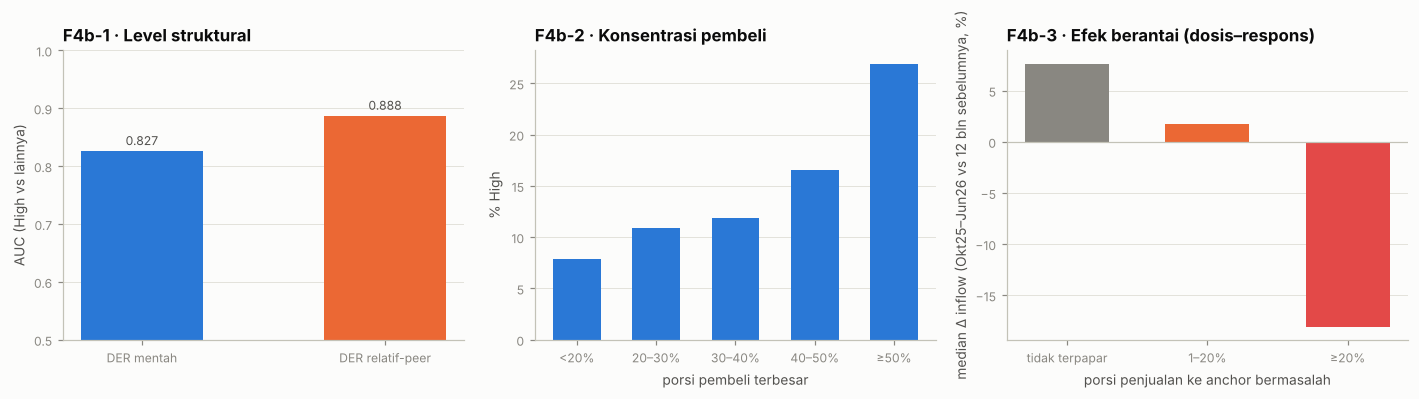

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(['DER mentah', 'DER relatif-peer'], [auc_raw, auc_peer], color=[C['s1'], C['s2']], width=.5); ax[0].set_ylim(.5, 1)
for i_, v in enumerate([auc_raw, auc_peer]): ax[0].text(i_, v + .01, f'{v:.3f}', ha='center', fontsize=8, color=C['ink2'])
ax[0].set(ylabel='AUC (High vs lainnya)', title='F4b-1 · Level struktural'); ax[0].grid(axis='x', visible=False)
bk = pd.cut(conc.top, [0, .2, .3, .4, .5, 1], labels=['<20%', '20–30%', '30–40%', '40–50%', '≥50%'])
hr = conc.groupby(bk, observed=True).High.mean()
ax[1].bar(hr.index.astype(str), 100 * hr.values, color=C['s1'], width=.6); ax[1].set(xlabel='porsi pembeli terbesar', ylabel='% High', title='F4b-2 · Konsentrasi pembeli'); ax[1].grid(axis='x', visible=False)
E['kel'] = pd.cut(E.expo, [-1, 0, .2, 1], labels=['tidak terpapar', '1–20%', '≥20%'])
dz = E.groupby('kel', observed=True).d.median()
ax[2].bar(dz.index.astype(str), 100 * dz.values, color=[C['muted'], C['s2'], C['s8']], width=.6); ax[2].axhline(0, color=C['axis'], lw=.8)
ax[2].set(xlabel='porsi penjualan ke anchor bermasalah', ylabel='median Δ inflow (Okt25–Jun26 vs 12 bln sebelumnya, %)', title='F4b-3 · Efek berantai (dosis–respons)'); ax[2].grid(axis='x', visible=False)
plt.tight_layout(); save_fig('06_F4b_pemulihan_pola'); plt.show()

### F5. Kebocoran data (*leakage*)
Kaufman dkk. (2012) mendefinisikan kebocoran sebagai informasi yang **tidak akan tersedia saat prediksi** tetapi ikut masuk ke data latih. Empat pemeriksaan:
1. **Urutan waktu** — semua data fitur ≤ 30 Jun 2026; label bertanggal cutoff; outcome hanya setelah cutoff.
2. **Pemindaian per kolom** — setiap kolom yang berperan `fitur` dihitung AUC-nya sendirian terhadap label High. Kolom dengan AUC sangat tinggi (≥ 0,90) dicurigai bocor. Kolom `proxy-label` memang diharapkan tinggi — itulah alasan kolom itu dilarang.
3. **Kebocoran ID** — nomor urut `company_id` tidak boleh berkorelasi dengan label (kesalahan klasik saat data diurutkan menurut kelas). Diuji dengan statistik Mann–Whitney: AUC di bawah hipotesis nol punya galat baku √((n₁+n₀+1)/(12n₁n₀)) (Hanley & McNeil, 1982).
4. **Uji permutasi label** (Ojala & Garriga, 2010) — model dilatih ulang dengan label diacak 30 kali. Skor harus turun ke tingkat acak; bila tidak, ada struktur yang bocor dari luar label.

In [39]:
L = 'F5 Kebocoran'
tchk = {'transactions': tx.transaction_date.max() <= CUTOFF, 'relationships (start/end)': rel.relationship_start.max() <= CUTOFF and rel.relationship_end.dropna().max() <= CUTOFF[:7],
        'product_holdings.open_month': ph.open_month.max() <= CUTOFF[:7], 'rm_action_log.contact_date': act.contact_date.max() <= CUTOFF,
        'rm_visit_notes.visit_date': vn.visit_date.max() <= CUTOFF, 'companies.onboarding_date': comp.onboarding_date.dropna().max() <= CUTOFF,
        'financials (FY ≤ 2025)': fin.fiscal_year.max() <= 2025}
add(L, '7 tabel fitur', 'tidak ada data setelah cutoff 30 Jun 2026', ', '.join(k for k, v in tchk.items() if not v) or 'semua ≤ cutoff', 'semua ≤ cutoff', all(tchk.values()), 'Kaufman dkk. 2012')
add(L, 'risk_labels', 'tanggal label = cutoff', ', '.join(rl.label_date.unique()), CUTOFF, (rl.label_date == CUTOFF).all(), 'Kaufman dkk. 2012')
add(L, 'outcome_product_adoption', 'outcome terjadi setelah cutoff (Jul–Sep 2026)', f"observation_end {outc.observation_end.unique()[0]} → kolom adopted_jul_sep_2026", 'setelah cutoff', outc.observation_end.eq(CUTOFF[:7]).all(), 'Kaufman dkk. 2012')
gt_only = {'health', 'growth', 'wallet_share_bni', 'regime', 'regime_magnitude', 'p_report_missing', 'contagion_exposure', 'is_distressed_anchor', 'group_effect',
           'wallet_erosion', 'risk_score_latent', 'unobserved_factor', 'risk_score_realized', 'true_risk_class', 'oracle_class', 'label_flipped', 'observed_label',
           'true_need', 'served_by_other_bank', 'true_party_id', 'true_is_bni_customer', 'affects_risk', 'event_type', 'present'}     # kolom kebenaran tersembunyi
obs_cols = set().union(*[set(data[t].columns) for t in data if not t.startswith('gt_')])
add(L, 'semua tabel', 'kolom ground truth tidak muncul di tabel teramati', ', '.join(sorted(gt_only & obs_cols)) or 'tidak ada', 'tidak ada', not (gt_only & obs_cols), 'Kaufman dkk. 2012')
# pemindaian per kolom (nasabah kredit)
S = comp.set_index('company_id')[['establishment_year', 'employees', 'is_listed', 'has_import_activity', 'kbli_2digit', 'latitude', 'longitude']].astype(float)
S = S.join(cf.set_index('company_id')[['limit_idr_bn', 'outstanding_idr_bn', 'utilization', 'collectibility', 'max_dpd_12m', 'restructuring_flag', 'watchlist_flag']].astype(float))
S = S.join(f25[['revenue_idr_bn', 'total_assets_idr_bn', 'total_debt_idr_bn', 'current_assets_idr_bn', 'current_liabilities_idr_bn', 'ebit_idr_bn', 'net_profit_idr_bn']])
S = S.join(ph.groupby('company_id').size().rename('n_products')).join(inn[MONTHS[-6:]].sum(1).rename('inflow_6m'))
S = S.join(rel.groupby('source_id').size().rename('n_relationships'))
S['company_id_number'] = [int(c[1:]) for c in S.index]
role_of = {**{r.kolom: r.peran for r in DD.itertuples() if r.tabel in ('companies', 'credit_facilities', 'financials')},
           'n_products': 'fitur', 'inflow_6m': 'fitur', 'n_relationships': 'fitur', 'company_id_number': 'id'}
scan = []
for col_ in S.columns:
    x_ = S[col_].reindex(yH.index); ok_ = x_.notna()
    if x_[ok_].nunique() < 2: continue
    a_ = roc_auc_score(yH[ok_], x_[ok_]); scan.append(dict(kolom=col_, peran=role_of.get(col_, 'fitur'), AUC=max(a_, 1 - a_), terisi=ok_.mean()))
scan = pd.DataFrame(scan).sort_values('AUC', ascending=False)
feat_max = scan[scan.peran.eq('fitur')].AUC.max(); feat_top = scan[scan.peran.eq('fitur')].iloc[0].kolom
add(L, 'pemindaian kolom', 'AUC tunggal tertinggi di antara kolom berperan fitur', f'{feat_max:.3f} ({feat_top})', '< 0,90', feat_max < .90, 'Kaufman dkk. 2012')
prox = scan[scan.peran.eq('proxy-label')]
add(L, 'credit_facilities', 'kolom proxy-label memang sangat prediktif → dilarang', ', '.join(f'{r.kolom} {r.AUC:.2f}' for r in prox.itertuples()), 'ditandai di kamus data', None, 'Kaufman dkk. 2012')
id_auc = scan.set_index('kolom').AUC.get('company_id_number', .5)
n1, n0 = int(yH.sum()), int((~yH).sum()); se0 = np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))      # galat baku AUC di bawah H0 (Mann–Whitney)
add(L, 'companies', 'nomor urut company_id tidak terkait label (AUC, uji Mann–Whitney)', f'{id_auc:.3f} (z = {(id_auc - .5) / se0:.2f})', '|z| < 2,58 (p > 0,01)', abs(id_auc - .5) / se0 < 2.58, 'Kaufman dkk. 2012; Hanley & McNeil 1982')
lr_ = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
real = f1_score(y3, cross_val_predict(lr_, Xl, y3, cv=cv5), average='macro')
rng_p = np.random.default_rng(0); perm = []
for _ in range(30):
    yp = pd.Series(rng_p.permutation(y3.values), index=y3.index); perm.append(f1_score(yp, cross_val_predict(lr_, Xl, yp, cv=cv5), average='macro'))
pval = (1 + sum(p >= real for p in perm)) / 31
add(L, 'risk_labels', 'uji permutasi label (30×): F1 asli vs label acak', f'{real:.3f} vs {np.mean(perm):.3f} ± {np.std(perm):.3f}; p = {pval:.3f}', 'acak ≈ 0,33; p < 0,05', pval < .05 and np.mean(perm) < .40, 'Ojala & Garriga 2010')
show(L)

F5 Kebocoran: 7 lolos · 0 gagal · 1 informasi


tabel,uji,nilai,target,status,rujukan
7 tabel fitur,tidak ada data setelah cutoff 30 Jun 2026,semua ≤ cutoff,semua ≤ cutoff,LOLOS,Kaufman dkk. 2012
risk_labels,tanggal label = cutoff,2026-06-30,2026-06-30,LOLOS,Kaufman dkk. 2012
outcome_product_adoption,outcome terjadi setelah cutoff (Jul–Sep 2026),observation_end 2026-06 → kolom adopted_jul_sep_2026,setelah cutoff,LOLOS,Kaufman dkk. 2012
semua tabel,kolom ground truth tidak muncul di tabel teramati,tidak ada,tidak ada,LOLOS,Kaufman dkk. 2012
pemindaian kolom,AUC tunggal tertinggi di antara kolom berperan fitur,0.815 (ebit_idr_bn),"< 0,90",LOLOS,Kaufman dkk. 2012
credit_facilities,kolom proxy-label memang sangat prediktif → dilarang,"collectibility 0.85, max_dpd_12m 0.83, watchlist_flag 0.69, restructuring_flag 0.69",ditandai di kamus data,info,Kaufman dkk. 2012
companies,"nomor urut company_id tidak terkait label (AUC, uji Mann–Whitney)",0.551 (z = 1.93),"|z| < 2,58 (p > 0,01)",LOLOS,Kaufman dkk. 2012; Hanley & McNeil 1982
risk_labels,uji permutasi label (30×): F1 asli vs label acak,0.634 vs 0.255 ± 0.004; p = 0.032,"acak ≈ 0,33; p < 0,05",LOLOS,Ojala & Garriga 2010


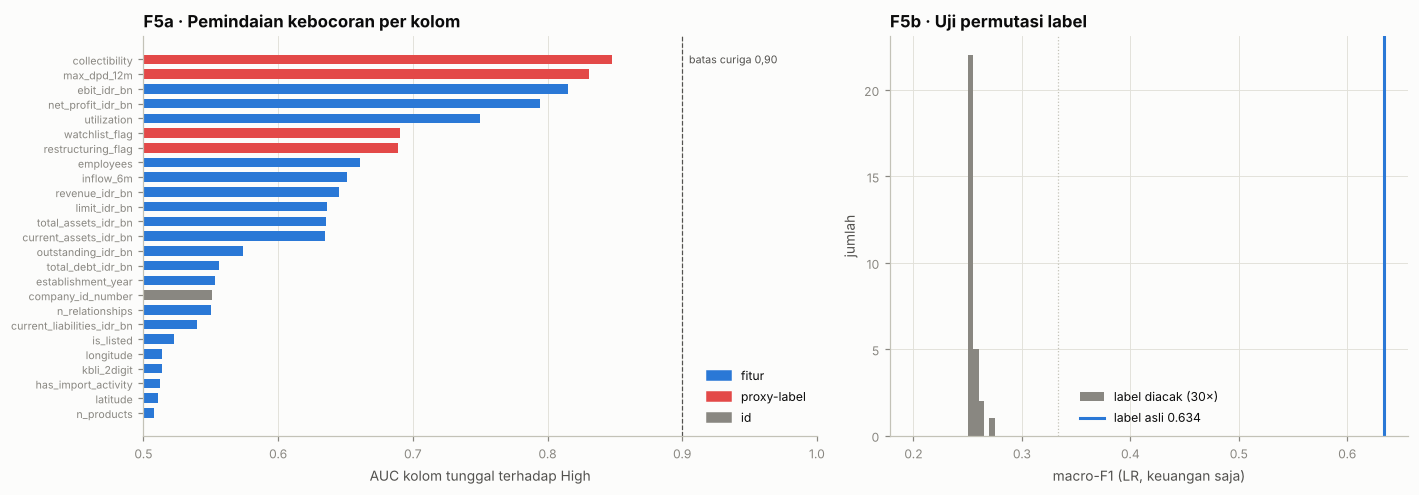

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
sc_ = scan.iloc[::-1]
role_col = {'fitur': C['s1'], 'proxy-label': C['s8'], 'id': C['muted']}
ax[0].barh(sc_.kolom, sc_.AUC, color=[role_col.get(r, C['s1']) for r in sc_.peran], height=.65)
ax[0].axvline(.9, color=C['ink2'], lw=.8, ls='--'); ax[0].text(.905, len(sc_) - 1, 'batas curiga 0,90', fontsize=7, color=C['ink2'], va='center')
ax[0].set_xlim(.5, 1); ax[0].tick_params(axis='y', labelsize=7); ax[0].grid(axis='y', visible=False)
ax[0].set(xlabel='AUC kolom tunggal terhadap High', title='F5a · Pemindaian kebocoran per kolom')
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=v, label=k) for k, v in role_col.items()], loc='lower right')
ax[1].hist(perm, bins=np.linspace(.2, .3, 21), color=C['muted'], label='label diacak (30×)'); ax[1].axvline(1 / 3, color=C['axis'], lw=.8, ls=':'); ax[1].axvline(real, color=C['s1'], lw=2, label=f'label asli {real:.3f}')
ax[1].set(xlabel='macro-F1 (LR, keuangan saja)', ylabel='jumlah', title='F5b · Uji permutasi label'); ax[1].legend()
plt.tight_layout(); save_fig('07_F5_kebocoran'); plt.show()

### F6. Privasi
Seluruh entitas fiktif. Pemeriksaan memastikan tidak ada kolom data pribadi (NIK, NPWP, telepon, email, alamat rumah), semua nama berakhiran "(dummy)", nomor rekening adalah angka acak, dan koordinat hanya titik pusat kecamatan + derau. Metrik privasi berbasis jarak ke rekaman asli (*distance to closest record*) tidak relevan karena tidak ada data riil yang bisa bocor (Jordon dkk., 2022).

In [41]:
L = 'F6 Privasi'
pii = [f'{t}.{c}' for t, d in data.items() for c in d.columns if re.search(r'nik|ktp|npwp|phone|telp|email|alamat|address|birth|lahir', c, re.I)]
add(L, 'semua tabel', 'tidak ada kolom data pribadi (NIK/NPWP/telepon/email/alamat)', ', '.join(pii) or 'tidak ada', 'tidak ada', not pii, 'UU 27/2022 PDP')
dn_ = all(data[t][c].astype(str).str.endswith('(dummy)').all() for t, c in [('companies', 'company_name'), ('network_entities', 'entity_name'), ('branches', 'branch_name')])
add(L, 'companies, entities, branches', 'semua nama entitas berakhiran "(dummy)"', 'ya' if dn_ else 'tidak', 'ya', dn_, 'Jordon dkk. 2022')
dev = haversine_km(comp.latitude.values, comp.longitude.values, gl.centroid_lat[comp.location_id].values, gl.centroid_lon[comp.location_id].values)
add(L, 'companies', 'koordinat = pusat kecamatan + derau (bukan alamat)', f'median {np.median(dev):.1f} km dari pusat', 'informasi', None, 'Jordon dkk. 2022')
show(L)

F6 Privasi: 2 lolos · 0 gagal · 1 informasi


tabel,uji,nilai,target,status,rujukan
semua tabel,tidak ada kolom data pribadi (NIK/NPWP/telepon/email/alamat),tidak ada,tidak ada,LOLOS,UU 27/2022 PDP
"companies, entities, branches","semua nama entitas berakhiran ""(dummy)""",ya,ya,LOLOS,Jordon dkk. 2022
companies,koordinat = pusat kecamatan + derau (bukan alamat),median 1.6 km dari pusat,informasi,info,Jordon dkk. 2022


### F7. Dokumentasi — *Datasheet for Datasets*
Gebru dkk. (2021) mengusulkan setiap dataset disertai *datasheet*: motivasi, komposisi, proses pembuatan, pra-pemrosesan, penggunaan yang dianjurkan & dilarang, distribusi, dan pemeliharaan. Datasheet ditulis otomatis dari isi data + hasil validasi di atas, bersama kamus data berperan kolom.

In [42]:
PLANTED = [('Level rasio struktural per industri × ukuran (tidak sejalan dengan risiko)', 'rasio relatif-peer'),
           ('Laporan keuangan hilang MNAR', 'indikator tidak melapor / tidak diaudit'),
           ('Kas ketat kronis + sinyal dini 3 bulan sebelum distress (payroll, pajak, supplier)', 'pergeseran tgl payroll, % pajak telat, % payroll ≥ tgl 28'),
           ('Erosi wallet share (omzet tetap, inflow BNI turun)', 'divergensi omzet vs inflow BNI'),
           ('Konsentrasi pembeli (porsi > 30% menambah risiko)', 'porsi pembeli terbesar, HHI'),
           ('Efek berantai 2 anchor (Jul 2025, lag 2 bln, ∝ ketergantungan)', 'eksposur ke pembeli yang inflow-nya turun'),
           ('Grup usaha dengan kesehatan berkorelasi', 'agregat risiko rekan grup (graf)'),
           ('Rantai nilai + gravitasi + preferential attachment', 'derajat, PageRank, komunitas, jarak mitra'),
           ('Musiman per industri (Lebaran, Desember)', 'inflow terkoreksi musiman'),
           ('White-space: 6 kecamatan industri tanpa cabang', 'penetrasi per kecamatan')]


def write_datasheet(data, cfg, out=OUT, all_tests=None):
    """all_tests = ringkasan gabungan dari bagian G (7 lapis + F2b + F8); bila None, hanya 7 lapis yang sudah dijalankan."""
    v = pd.DataFrame(VAL) if all_tests is None else all_tests; summ = v.status.value_counts().to_dict()
    R_ = 'outputs/01_dataset_validation'
    val_txt = (f'7 lapis, {len(v)} uji — ringkas: {summ}. Rincian: `{R_}/validation_report.csv`.' if all_tests is None else
               f"7 lapis (F1–F7) + uji statistik jaringan (F2b) + uji signifikansi (F8): {len(v)} uji — {summ.get('LOLOS', 0)} lolos, "
               f"{summ.get('GAGAL', 0)} gagal, {summ.get('info', 0)} informasi. Rincian: `{R_}/validation_report.csv`, `{R_}/network_tests.csv`, `{R_}/significance_tests.csv`.")
    L_ = ['# Datasheet — BNI EGI Synthetic Dataset v8', '',
          f'*Dibangkitkan oleh notebook `01_Dataset_Generation_and_Validation.ipynb` (seed {SEED}). Format: Gebru dkk. (2021). Seluruh data SINTETIS — tidak ada data nasabah riil atau data pribadi.*', '',
          '## 1. Motivasi', 'Mendukung capstone BNI Ecosystem & Growth Intelligence: Opportunity Score, klasifikasi risiko, deteksi anomali "Why Now", white-space produk & geografis, analitik jaringan ekosistem, dan RM Copilot agentic. Setiap tugas punya ground truth (`gt_*`).', '',
          '## 2. Komposisi', '| File | Baris | Isi |', '|---|---|---|']
    L_ += [f'| `{k}.csv` | {len(d):,} | {FILE_DOC.get(k, "")} |' for k, d in data.items()]
    L_ += ['', f"Satuan: transaksi & saldo Rp juta (`_idr_mn`), laporan keuangan Rp miliar (`_idr_bn`). Periode fitur {cfg['months'][0]}–{cfg['months'][-1]} (cutoff {CUTOFF}); outcome {cfg['outcome_window'][0]}–{cfg['outcome_window'][1]}.", '',
           '## 3. Proses pembuatan', 'Model kausal 18 tahap (lihat notebook bagian B & D): kondisi tersembunyi (kesehatan, pertumbuhan, efek grup, kejadian, kebutuhan) → semua tabel teramati.',
           f"Parameter utama: σ faktor tak teramati {cfg['sigma_unobserved']}, kesalahan rating {cfg['label_error_rate']:.0%}, ambang kelas kuantil {cfg['risk_quantiles']}, grup usaha {cfg['group_frac']:.0%}, skala gravitasi {cfg['gravity_km']} km, relasi baru {cfg['new_edge_rate']:.0%}.", '',
           '### Pola yang ditanam (dapat dipulihkan dari data teramati — lihat F4b)', '| Pola | Fitur/analisis yang menangkap |', '|---|---|']
    L_ += [f'| {a} | {b} |' for a, b in PLANTED]
    L_ += ['', '## 4. Masalah kualitas data yang disengaja',
           f"- Duplikat transaksi ±{cfg['dq']['dup_tx']:.1%}, nominal nol, `channel` kosong ±{cfg['dq']['nan_channel']:.1%}, `counterparty_id` kosong ±{cfg['dq']['nan_cp']:.0%}; EBIT/bunga kosong ±{cfg['dq']['nan_ebit']:.1%}.",
           '- Laporan keuangan tidak tersedia untuk sebagian perusahaan (MNAR — bukan acak).', '- Nama counterparty mentah (typo, singkatan, huruf kapital, kota kosong).', '',
           '## 5. Aturan pemakaian (lihat kolom `peran` di `data_dictionary.csv`)',
           '- `gt_*` = **hanya evaluasi**. `outcome_product_adoption` = **hanya validasi** (terjadi setelah cutoff).',
           '- `credit_facilities`: collectibility, max_dpd_12m, watchlist_flag, restructuring_flag = **proxy label** → dilarang sebagai fitur model risiko.',
           '- Hasil model pada data ini membuktikan cara kerja pipeline, bukan performa pada data riil BNI.', '',
           '## 6. Keterbatasan',
           '- Distribusi dikalibrasi agar wajar (Benford, ekor tebal, musiman, struktur jaringan), bukan direplikasi dari data riil; metrik fidelitas berbasis data riil (α-precision/β-recall, Alaa dkk. 2022) tidak dapat dihitung.',
           '- Koordinat ilustratif (pusat kecamatan + derau). Catatan kunjungan dari templat parafrase — variasi bahasanya lebih sempit daripada catatan RM sungguhan.', '',
           '## 7. Validasi', val_txt, '',
           '## 8. Pemeliharaan', 'Generator deterministik (seed). Ubah parameter di `CFG`, jalankan ulang notebook; seluruh validasi ikut dijalankan ulang.']
    open(f'{out}/DATASHEET.md', 'w', encoding='utf-8').write('\n'.join(L_))

In [43]:
L = 'F7 Dokumentasi'
write_datasheet(data, cfg)
add(L, 'DATASHEET.md', 'datasheet tersedia (motivasi, komposisi, proses, aturan, keterbatasan, validasi)', f"{os.path.getsize(f'{OUT}/DATASHEET.md') / 1024:.0f} KB", 'ada', os.path.exists(f'{OUT}/DATASHEET.md'), 'Gebru dkk. 2021')
cov = DD.groupby('tabel').size().reindex(list(data)).notna().all()
add(L, 'data_dictionary.csv', 'kamus data mencakup semua tabel & memberi peran tiap kolom', f'{len(DD)} kolom · {DD.peran.nunique()} peran', 'semua tabel', cov, 'Gebru dkk. 2021')
write_datasheet(data, cfg)                                         # tulis ulang agar ringkasan memuat uji F7
show(L)

F7 Dokumentasi: 2 lolos · 0 gagal · 0 informasi


tabel,uji,nilai,target,status,rujukan
DATASHEET.md,"datasheet tersedia (motivasi, komposisi, proses, aturan, keterbatasan, validasi)",7 KB,ada,LOLOS,Gebru dkk. 2021
data_dictionary.csv,kamus data mencakup semua tabel & memberi peran tiap kolom,213 kolom · 8 peran,semua tabel,LOLOS,Gebru dkk. 2021


### F8. Uji signifikansi pola tertanam
Lapis F4b menunjukkan pola tertanam **muncul** di data teramati. Lapis ini menguji apakah pola itu **signifikan secara statistik**, bukan kebetulan sampel: setiap perbandingan diberi uji yang sesuai, selang kepercayaan 95%, dan koreksi uji berganda.

| Pola | Uji | Rujukan |
|---|---|---|
| Selisih dua kelompok (efek berantai, pajak telat, gaji telat) | Mann–Whitney U + CI bootstrap selisih | Mann & Whitney (1947); Efron & Tibshirani (1993) |
| Arah hubungan eksposur vs Δ inflow | korelasi Spearman | Spearman (1904) |
| Gradien bertingkat (konsentrasi pembeli → % High) | uji tren Cochran–Armitage | Cochran (1954); Armitage (1955) |
| Presisi kuadran "pindah bank" vs porsi dasar | uji binomial + CI Clopper–Pearson | Clopper & Pearson (1934) |
| Event study (berpasangan per perusahaan) | Wilcoxon signed-rank + CI bootstrap | Wilcoxon (1945); MacKinlay (1997) |
| Lonjakan Lebaran (median > 1) | Wilcoxon + CI bootstrap median | Wilcoxon (1945) |
| Bentuk distribusi nominal transaksi | Kolmogorov–Smirnov vs lognormal (p besar = cocok) | Massey (1951) |
| Puluhan uji sekaligus | Bonferroni & Benjamini–Hochberg | Benjamini & Hochberg (1995) |

**Catatan:** dengan ribuan perusahaan, efek kecil pun mudah signifikan. Karena itu yang ditekankan adalah **besar efek dan CI-nya**, bukan sekadar *p-value*. Hasil F8 disimpan terpisah (`significance_tests.csv`) dan ikut dihitung di ringkasan bagian G (uji beda dihitung lolos bila lolos koreksi Bonferroni).

In [44]:
from scipy import stats
rng_b = np.random.default_rng(0); B_BOOT = 2000
def boot_diff(a, b, f=np.mean):
    a, b = np.asarray(a), np.asarray(b)
    d = [f(rng_b.choice(a, len(a))) - f(rng_b.choice(b, len(b))) for _ in range(B_BOOT)]
    return f(a) - f(b), *np.percentile(d, [2.5, 97.5])
SIG = []
def sig_add(pola, diuji, est, lo, hi, satuan, uji, stat, p, n, h0, rujukan, jenis='beda'):
    SIG.append(dict(pola=pola, yang_diuji=diuji, estimasi=est, ci95_bawah=lo, ci95_atas=hi, satuan=satuan, uji=uji, statistik=stat,
                    p_value=p, n=n, nilai_nol=h0, jenis=jenis, rujukan=rujukan))

# efek berantai (E dan anchor dari F4b, dideteksi dari data teramati)
a_, b_ = E[E.expo >= .2].d.values, E[E.expo == 0].d.values
est, lo, hi = boot_diff(a_, b_, np.median); mw = stats.mannwhitneyu(a_, b_)
sig_add('Efek berantai', 'Δ inflow pemasok terpapar ≥ 20% − tidak terpapar (selisih median)', est, lo, hi, '%', 'Mann–Whitney U', mw.statistic, mw.pvalue,
        f'{len(a_)} vs {len(b_)}', 0, 'Mann & Whitney 1947; Efron & Tibshirani 1993')
rho = stats.spearmanr(E.expo, E.d)
sig_add('Efek berantai', 'korelasi eksposur ke anchor vs Δ inflow', rho.statistic, np.nan, np.nan, 'ρ', 'Spearman', rho.statistic, rho.pvalue, str(len(E)), 0, 'Spearman 1904')
# sinyal dini (tl, pl_, rk dari F4b)
for nama, s_ in [('% pajak dibayar setelah tgl 15 (6 bln): High − Low', tl), ('% gaji dibayar ≥ tgl 28 (12 bln): High − Low', pl_)]:
    h_, l_ = s_.reindex(rk[rk.eq('High')].index).dropna(), s_.reindex(rk[rk.eq('Low')].index).dropna()
    est, lo, hi = boot_diff(h_, l_); mw = stats.mannwhitneyu(h_, l_)
    sig_add('Sinyal dini', nama, est, lo, hi, '%', 'Mann–Whitney U', mw.statistic, mw.pvalue, f'{len(h_)} vs {len(l_)}', 0, 'Mann & Whitney 1947; Efron & Tibshirani 1993')
# konsentrasi pembeli: uji tren Cochran–Armitage (conc dari F4b)
kk = pd.cut(conc.top, [0, .2, .3, .4, .5, 1], labels=False); tab = conc.groupby(kk).High.agg(['sum', 'count'])
s_k, n_k, x_k = tab.index.values.astype(float), tab['count'].values, tab['sum'].values; p_k = x_k.sum() / n_k.sum()
z_ca = np.sum(s_k * (x_k - n_k * p_k)) / np.sqrt(p_k * (1 - p_k) * (np.sum(n_k * s_k ** 2) - np.sum(n_k * s_k) ** 2 / n_k.sum()))
sig_add('Konsentrasi pembeli', '% High naik dengan porsi pembeli terbesar (<20% → ≥50%): ' + ' → '.join(f'{v:.0%}' for v in x_k / n_k),
        x_k[-1] / n_k[-1] - x_k[0] / n_k[0], np.nan, np.nan, '%', 'Cochran–Armitage', z_ca, 2 * stats.norm.sf(abs(z_ca)), str(int(n_k.sum())), 0, 'Cochran 1954; Armitage 1955')
# pindah bank: presisi kuadran vs porsi dasar (q6, quad dari F4b; GT hanya untuk verifikasi)
er = gtl.set_index('company_id').wallet_erosion; base_er = er.reindex(q6.index).mean(); hit_er = er.reindex(quad)
bt = stats.binomtest(int(hit_er.sum()), len(hit_er), base_er); ci_er = bt.proportion_ci()
sig_add('Pindah bank', f'presisi kuadran "inflow BNI turun > 25%, omzet naik" (porsi dasar {base_er:.1%})', hit_er.mean(), ci_er.low, ci_er.high, '%', 'Binomial',
        int(hit_er.sum()), bt.pvalue, str(len(hit_er)), base_er, 'Clopper & Pearson 1934')
# event study berpasangan (es dari F4b)
pb = es[es.rel.between(-9, -5)].groupby('company_id').pday.mean(); pp = es[es.rel.between(-3, -1)].groupby('company_id').pday.mean()
dd = (pp - pb).dropna(); ci_d = np.percentile([rng_b.choice(dd, len(dd)).mean() for _ in range(B_BOOT)], [2.5, 97.5]); wx = stats.wilcoxon(dd)
sig_add('Sinyal dini', 'event study: pergeseran tanggal gaji t−3…t−1 vs baseline (berpasangan)', dd.mean(), *ci_d, 'hari', 'Wilcoxon signed-rank', wx.statistic, wx.pvalue,
        str(len(dd)), 0, 'Wilcoxon 1945; MacKinlay 1997')
# lonjakan Lebaran
idx_l = obs_in.div(obs_in.median(1), axis=0)
for m_ in ['2025-03', '2026-03']:
    v_ = idx_l[m_].dropna(); ci_v = np.percentile([np.median(rng_b.choice(v_, len(v_))) for _ in range(B_BOOT)], [2.5, 97.5]); w_ = stats.wilcoxon(v_ - 1)
    sig_add('Musiman', f'indeks inflow Lebaran {m_} (median; 1 = bulan normal)', v_.median(), *ci_v, 'indeks', 'Wilcoxon (median > 1)', w_.statistic, w_.pvalue,
            str(len(v_)), 1, 'Wilcoxon 1945; Efron & Tibshirani 1993')
# bentuk distribusi (uji kecocokan: p besar = cocok)
la = np.log(amt.sample(5000, random_state=0)); ks = stats.kstest((la - la.mean()) / la.std(), 'norm')
sig_add('Distribusi', 'nominal transaksi berdistribusi lognormal (sampel 5.000)', stats.skew(la), np.nan, np.nan, 'skew log', 'Kolmogorov–Smirnov', ks.statistic, ks.pvalue,
        '5000', np.nan, 'Massey 1951', jenis='kecocokan')

SIGDF = pd.DataFrame(SIG); ALPHA = .05
beda = SIGDF.jenis.eq('beda'); m_uji = int(beda.sum())
SIGDF['lolos_bonferroni'] = np.where(beda, SIGDF.p_value < ALPHA / m_uji, None)
pr = SIGDF.loc[beda, 'p_value'].rank(method='first'); kmax = max([k for k, p in zip(pr, SIGDF.loc[beda, 'p_value']) if p <= k / m_uji * ALPHA], default=0)
SIGDF['lolos_bh'] = None; SIGDF.loc[beda, 'lolos_bh'] = pr <= kmax
SIGDF['ci_memuat_nol'] = [None if (pd.isna(r.ci95_bawah) or pd.isna(r.nilai_nol)) else bool(r.ci95_bawah <= r.nilai_nol <= r.ci95_atas) for r in SIGDF.itertuples()]
SIGDF['kesimpulan'] = [('distribusi sesuai' if r.p_value >= ALPHA else 'distribusi menyimpang') if r.jenis == 'kecocokan'
                       else ('signifikan & kuat' if r.lolos_bonferroni and r.ci_memuat_nol is not True else 'signifikan' if r.p_value < ALPHA else 'tidak signifikan')
                       for r in SIGDF.itertuples()]
REPORT.mkdir(parents=True, exist_ok=True); SIGDF.to_csv(REPORT / 'significance_tests.csv', index=False)
print(f"{int(SIGDF.lolos_bonferroni.eq(True).sum())}/{m_uji} uji beda lolos Bonferroni (α = {ALPHA / m_uji:.4f}) · {int(SIGDF.lolos_bh.eq(True).sum())}/{m_uji} lolos Benjamini–Hochberg · "
      f"CI memuat nilai nol: {int(SIGDF.ci_memuat_nol.eq(True).sum())} · p terbesar (uji beda) {SIGDF.loc[beda, 'p_value'].max():.1e}")
fmt = lambda r, v: '' if pd.isna(v) else (f'{v:+.1%}' if r.satuan == '%' else f'{v:.3f}')
show_sig = pd.DataFrame({'pola': SIGDF.pola, 'yang diuji': SIGDF.yang_diuji, 'estimasi': [fmt(r, r.estimasi) for r in SIGDF.itertuples()],
                         '95% CI': ['' if pd.isna(r.ci95_bawah) else f'[{fmt(r, r.ci95_bawah)}; {fmt(r, r.ci95_atas)}]' for r in SIGDF.itertuples()],
                         'uji': SIGDF.uji, 'p-value': SIGDF.p_value.map(lambda p: f'{p:.1e}'), 'kesimpulan': SIGDF.kesimpulan})
show_sig.style.hide(axis='index')

9/9 uji beda lolos Bonferroni (α = 0.0056) · 9/9 lolos Benjamini–Hochberg · CI memuat nilai nol: 0 · p terbesar (uji beda) 1.6e-06


pola,yang diuji,estimasi,95% CI,uji,p-value,kesimpulan
Efek berantai,Δ inflow pemasok terpapar ≥ 20% − tidak terpapar (selisih median),-25.5%,[-30.8%; -20.7%],Mann–Whitney U,1.1e-12,signifikan & kuat
Efek berantai,korelasi eksposur ke anchor vs Δ inflow,-0.154,,Spearman,7.1e-09,signifikan & kuat
Sinyal dini,% pajak dibayar setelah tgl 15 (6 bln): High − Low,+26.7%,[+21.3%; +32.3%],Mann–Whitney U,1.7e-33,signifikan & kuat
Sinyal dini,% gaji dibayar ≥ tgl 28 (12 bln): High − Low,+26.6%,[+22.3%; +30.9%],Mann–Whitney U,3.7e-40,signifikan & kuat
Konsentrasi pembeli,% High naik dengan porsi pembeli terbesar (<20% → ≥50%): 8% → 11% → 12% → 17% → 27%,+19.0%,,Cochran–Armitage,1.6e-06,signifikan & kuat
Pindah bank,"presisi kuadran ""inflow BNI turun > 25%, omzet naik"" (porsi dasar 6.3%)",+66.7%,[+54.0%; +77.8%],Binomial,5.9e-37,signifikan & kuat
Sinyal dini,event study: pergeseran tanggal gaji t−3…t−1 vs baseline (berpasangan),1.645,[1.357; 1.931],Wilcoxon signed-rank,6.3e-12,signifikan & kuat
Musiman,indeks inflow Lebaran 2025-03 (median; 1 = bulan normal),1.165,[1.152; 1.178],Wilcoxon (median > 1),1.7e-137,signifikan & kuat
Musiman,indeks inflow Lebaran 2026-03 (median; 1 = bulan normal),1.241,[1.219; 1.264],Wilcoxon (median > 1),1.5e-133,signifikan & kuat
Distribusi,nominal transaksi berdistribusi lognormal (sampel 5.000),-0.150,,Kolmogorov–Smirnov,3.3e-01,distribusi sesuai


### Tabel rujukan
Satu tabel rujukan dipakai untuk tiga hal: kolom `tautan` di `validation_report.csv`, ekspor `references.csv` / `REFERENCES.md`, dan daftar pustaka di akhir notebook. Kolom `dicek` jujur menandai tautan mana yang sudah dibuka saat penyusunan; sisanya diambil dari bibliografi standar dan sebaiknya dicek sebelum dikutip di laporan.

In [45]:
# Data rujukan untuk notebook 01. cari = (kata kunci penulis, tahun) yang dicocokkan dengan kolom `rujukan` di laporan validasi.
# dicek: 'ya' = DOI/URL dibuka dan mengarah ke artikel yang benar saat penyusunan (10 Okt 2026); 'belum' = dari bibliografi, cek sebelum dikutip.
REFS = [
 dict(id='R01', kutipan='Sargent (2013)', penulis='Sargent, R. G.', tahun=2013, judul='Verification and validation of simulation models', terbitan='Journal of Simulation, 7(1), 12–24', doi='10.1057/jos.2012.20', url='https://ideas.repec.org/a/taf/tjsmxx/v7y2013i1p12-24.html', dicek='URL ya; DOI belum', bagian='F (kerangka), F1, F3', dipakai='Kerangka verifikasi & validasi; uji kondisi ekstrem, sensitivitas, multi-seed', cari=('Sargent', '2013')),
 dict(id='R02', kutipan='Nigrini (2012)', penulis='Nigrini, M. J.', tahun=2012, judul="Benford's Law: Applications for Forensic Accounting, Auditing, and Fraud Detection", terbitan='Wiley', doi='10.1002/9781119203094', url='', dicek='belum', bagian='F2', dipakai='Uji Hukum Benford & batas MAD', cari=('Nigrini', '2012')),
 dict(id='R03', kutipan='Barabási & Albert (1999)', penulis='Barabási, A.-L.; Albert, R.', tahun=1999, judul='Emergence of scaling in random networks', terbitan='Science, 286(5439), 509–512', doi='10.1126/science.286.5439.509', url='', dicek='belum', bagian='D3, F2', dipakai='Preferential attachment; derajat berekor tebal', cari=('Barabási', '1999')),
 dict(id='R04', kutipan='Newman (2002)', penulis='Newman, M. E. J.', tahun=2002, judul='Assortative mixing in networks', terbitan='Physical Review Letters, 89(20), 208701', doi='10.1103/PhysRevLett.89.208701', url='', dicek='belum', bagian='F2', dipakai='Koefisien asortativitas derajat', cari=('Newman', '2002')),
 dict(id='R05', kutipan='Newman (2006)', penulis='Newman, M. E. J.', tahun=2006, judul='Modularity and community structure in networks', terbitan='PNAS, 103(23), 8577–8582', doi='10.1073/pnas.0601602103', url='', dicek='belum', bagian='F2', dipakai='Modularitas vs configuration model', cari=('Newman', '2006')),
 dict(id='R06', kutipan='Fujiwara & Aoyama (2010)', penulis='Fujiwara, Y.; Aoyama, H.', tahun=2010, judul='Large-scale structure of a nation-wide production network', terbitan='The European Physical Journal B, 77(4), 565–580', doi='10.1140/epjb/e2010-00275-2', url='', dicek='ya', bagian='D3, F2', dipakai='Stylized facts jaringan produksi (ekor, disasortatif)', cari=('Fujiwara', '2010')),
 dict(id='R07', kutipan='Bernard, Moxnes & Saito (2019)', penulis='Bernard, A. B.; Moxnes, A.; Saito, Y. U.', tahun=2019, judul='Production networks, geography, and firm performance', terbitan='Journal of Political Economy, 127(2), 639–688', doi='10.1086/700764', url='', dicek='ya', bagian='D3, F2', dipakai='Efek jarak (gravitasi) pada pemilihan mitra dagang', cari=('Bernard', '2019')),
 dict(id='R08', kutipan='Blondel dkk. (2008)', penulis='Blondel, V. D.; Guillaume, J.-L.; Lambiotte, R.; Lefebvre, E.', tahun=2008, judul='Fast unfolding of communities in large networks', terbitan='Journal of Statistical Mechanics, P10008', doi='10.1088/1742-5468/2008/10/P10008', url='', dicek='belum', bagian='F2', dipakai='Algoritme Louvain untuk komunitas', cari=('Blondel', '2008')),
 dict(id='R09', kutipan='Stanley dkk. (1996)', penulis='Stanley, M. H. R.; Amaral, L. A. N.; Buldyrev, S. V.; dkk.', tahun=1996, judul='Scaling behaviour in the growth of companies', terbitan='Nature, 379, 804–806', doi='10.1038/379804a0', url='', dicek='belum', bagian='D11, F2', dipakai='Volatilitas menurun dengan ukuran perusahaan', cari=('Stanley', '1996')),
 dict(id='R10', kutipan='Rubin (1976)', penulis='Rubin, D. B.', tahun=1976, judul='Inference and missing data', terbitan='Biometrika, 63(3), 581–592', doi='10.1093/biomet/63.3.581', url='', dicek='belum', bagian='D8, F4', dipakai='Missing not at random (laporan keuangan hilang)', cari=('Rubin', '1976')),
 dict(id='R11', kutipan='Wu & Keogh (2021)', penulis='Wu, R.; Keogh, E.', tahun=2021, judul='Current time series anomaly detection benchmarks are flawed and are creating the illusion of progress', terbitan='IEEE Transactions on Knowledge and Data Engineering', doi='10.1109/TKDE.2021.3112126', url='', dicek='ya', bagian='F4', dipakai='Uji trivialitas (aturan 1 baris)', cari=('Keogh', '2021')),
 dict(id='R12', kutipan='Woo dkk. (2009)', penulis='Woo, M.-J.; Reiter, J. P.; Oganian, A.; Karr, A. F.', tahun=2009, judul='Global measures of data utility for microdata masked for disclosure limitation', terbitan='Journal of Privacy and Confidentiality, 1(1)', doi='10.29012/jpc.v1i1.568', url='', dicek='ya', bagian='F4', dipakai='Propensity score mean-squared error (pMSE)', cari=('Woo', '2009')),
 dict(id='R13', kutipan='Snoke dkk. (2018)', penulis='Snoke, J.; Raab, G. M.; Nowok, B.; Dibben, C.; Slavkovic, A.', tahun=2018, judul='General and specific utility measures for synthetic data', terbitan='Journal of the Royal Statistical Society: Series A, 181(3), 663–688', doi='10.1111/rssa.12358', url='', dicek='ya', bagian='F4', dipakai='Utilitas data sintetis (pMSE)', cari=('Snoke', '2018')),
 dict(id='R14', kutipan='Cook, Gelman & Rubin (2006)', penulis='Cook, S. R.; Gelman, A.; Rubin, D. B.', tahun=2006, judul='Validation of software for Bayesian models using posterior quantiles', terbitan='Journal of Computational and Graphical Statistics, 15(3), 675–692', doi='10.1198/106186006X136976', url='', dicek='belum', bagian='F4b', dipakai='Gagasan parameter recovery', cari=('Cook', '2006')),
 dict(id='R15', kutipan='Talts dkk. (2018)', penulis='Talts, S.; Betancourt, M.; Simpson, D.; Vehtari, A.; Gelman, A.', tahun=2018, judul='Validating Bayesian inference algorithms with simulation-based calibration', terbitan='arXiv:1804.06788', doi='', url='https://arxiv.org/abs/1804.06788', dicek='belum', bagian='F4b', dipakai='Simulation-based calibration (parameter recovery)', cari=('Talts', '2018')),
 dict(id='R16', kutipan='MacKinlay (1997)', penulis='MacKinlay, A. C.', tahun=1997, judul='Event studies in economics and finance', terbitan='Journal of Economic Literature, 35(1), 13–39', doi='', url='https://www.jstor.org/stable/2729691', dicek='belum', bagian='F4b, F8', dipakai='Event study sinyal dini distress', cari=('MacKinlay', '1997')),
 dict(id='R17', kutipan='Battiston dkk. (2012)', penulis='Battiston, S.; Puliga, M.; Kaushik, R.; Tasca, P.; Caldarelli, G.', tahun=2012, judul='DebtRank: Too central to fail? Financial networks, the FED and systemic risk', terbitan='Scientific Reports, 2, 541', doi='10.1038/srep00541', url='', dicek='belum', bagian='D4, F4b', dipakai='Efek berantai (contagion) lewat jaringan', cari=('Battiston', '2012')),
 dict(id='R18', kutipan='Khanna & Yafeh (2007)', penulis='Khanna, T.; Yafeh, Y.', tahun=2007, judul='Business groups in emerging markets: Paragons or parasites?', terbitan='Journal of Economic Literature, 45(2), 331–372', doi='10.1257/jel.45.2.331', url='', dicek='belum', bagian='D1, D2, F4b', dipakai='Grup usaha & korelasi nasib anggota', cari=('Khanna', '2007')),
 dict(id='R19', kutipan='Kaufman dkk. (2012)', penulis='Kaufman, S.; Rosset, S.; Perlich, C.; Stitelman, O.', tahun=2012, judul='Leakage in data mining: Formulation, detection, and avoidance', terbitan='ACM Transactions on Knowledge Discovery from Data, 6(4), 15', doi='10.1145/2382577.2382579', url='', dicek='ya', bagian='F5', dipakai='Definisi & deteksi kebocoran', cari=('Kaufman', '2012')),
 dict(id='R20', kutipan='Ojala & Garriga (2010)', penulis='Ojala, M.; Garriga, G. C.', tahun=2010, judul='Permutation tests for studying classifier performance', terbitan='Journal of Machine Learning Research, 11, 1833–1863', doi='', url='https://jmlr.org/papers/v11/ojala10a.html', dicek='belum', bagian='F5', dipakai='Uji permutasi label', cari=('Ojala', '2010')),
 dict(id='R21', kutipan='Hanley & McNeil (1982)', penulis='Hanley, J. A.; McNeil, B. J.', tahun=1982, judul='The meaning and use of the area under a receiver operating characteristic (ROC) curve', terbitan='Radiology, 143(1), 29–36', doi='10.1148/radiology.143.1.7063747', url='', dicek='belum', bagian='F5', dipakai='Galat baku AUC (uji kebocoran ID)', cari=('Hanley', '1982')),
 dict(id='R22', kutipan='Northcutt, Jiang & Chuang (2021)', penulis='Northcutt, C. G.; Jiang, L.; Chuang, I. L.', tahun=2021, judul='Confident learning: Estimating uncertainty in dataset labels', terbitan='Journal of Artificial Intelligence Research, 70, 1373–1411', doi='10.1613/jair.1.12125', url='', dicek='ya', bagian='D7, F4', dipakai='Kesalahan label (label noise)', cari=('Northcutt', '2021')),
 dict(id='R23', kutipan='Gebru dkk. (2021)', penulis='Gebru, T.; Morgenstern, J.; Vecchione, B.; dkk.', tahun=2021, judul='Datasheets for datasets', terbitan='Communications of the ACM, 64(12), 86–92', doi='10.1145/3458723', url='', dicek='belum', bagian='F7', dipakai='Datasheet dataset', cari=('Gebru', '2021')),
 dict(id='R24', kutipan='Jordon dkk. (2022)', penulis='Jordon, J.; Szpruch, L.; Houssiau, F.; dkk.', tahun=2022, judul='Synthetic Data – what, why and how?', terbitan='arXiv:2205.03257 (Royal Society / Alan Turing Institute)', doi='', url='https://arxiv.org/abs/2205.03257', dicek='belum', bagian='F6', dipakai='Privasi data sintetis', cari=('Jordon', '2022')),
 dict(id='R25', kutipan='Pearl (2009)', penulis='Pearl, J.', tahun=2009, judul='Causality: Models, Reasoning, and Inference (2nd ed.)', terbitan='Cambridge University Press', doi='10.1017/CBO9780511803161', url='', dicek='belum', bagian='B', dipakai='Structural causal model', cari=('Pearl', '2009')),
 dict(id='R26', kutipan='Alaa dkk. (2022)', penulis='Alaa, A.; van Breugel, B.; Saveliev, E.; van der Schaar, M.', tahun=2022, judul='How faithful is your synthetic data? Sample-level metrics for evaluating and auditing generative models', terbitan='ICML 2022 (PMLR 162)', doi='', url='https://proceedings.mlr.press/v162/alaa22a.html', dicek='belum', bagian='Datasheet §6', dipakai='Metrik fidelitas (tidak dapat dihitung tanpa data riil)', cari=('Alaa', '2022')),
 dict(id='R27', kutipan='Mann & Whitney (1947)', penulis='Mann, H. B.; Whitney, D. R.', tahun=1947, judul='On a test of whether one of two random variables is stochastically larger than the other', terbitan='Annals of Mathematical Statistics, 18(1), 50–60', doi='10.1214/aoms/1177730491', url='', dicek='belum', bagian='F5, F8', dipakai='Uji Mann–Whitney U', cari=('Mann', '1947')),
 dict(id='R28', kutipan='Wilcoxon (1945)', penulis='Wilcoxon, F.', tahun=1945, judul='Individual comparisons by ranking methods', terbitan='Biometrics Bulletin, 1(6), 80–83', doi='10.2307/3001968', url='', dicek='belum', bagian='F8', dipakai='Uji Wilcoxon signed-rank', cari=('Wilcoxon', '1945')),
 dict(id='R29', kutipan='Cochran (1954)', penulis='Cochran, W. G.', tahun=1954, judul='Some methods for strengthening the common χ² tests', terbitan='Biometrics, 10(4), 417–451', doi='10.2307/3001616', url='', dicek='belum', bagian='F8', dipakai='Uji tren Cochran–Armitage', cari=('Cochran', '1954')),
 dict(id='R30', kutipan='Armitage (1955)', penulis='Armitage, P.', tahun=1955, judul='Tests for linear trends in proportions and frequencies', terbitan='Biometrics, 11(3), 375–386', doi='10.2307/3001775', url='', dicek='ya', bagian='F8', dipakai='Uji tren Cochran–Armitage', cari=('Armitage', '1955')),
 dict(id='R31', kutipan='Clopper & Pearson (1934)', penulis='Clopper, C. J.; Pearson, E. S.', tahun=1934, judul='The use of confidence or fiducial limits illustrated in the case of the binomial', terbitan='Biometrika, 26(4), 404–413', doi='10.1093/biomet/26.4.404', url='', dicek='belum', bagian='F8', dipakai='CI proporsi binomial', cari=('Clopper', '1934')),
 dict(id='R32', kutipan='Benjamini & Hochberg (1995)', penulis='Benjamini, Y.; Hochberg, Y.', tahun=1995, judul='Controlling the false discovery rate: A practical and powerful approach to multiple testing', terbitan='Journal of the Royal Statistical Society: Series B, 57(1), 289–300', doi='10.1111/j.2517-6161.1995.tb02031.x', url='', dicek='belum', bagian='F8', dipakai='Koreksi uji berganda (FDR)', cari=('Benjamini', '1995')),
 dict(id='R33', kutipan='Efron & Tibshirani (1993)', penulis='Efron, B.; Tibshirani, R. J.', tahun=1993, judul='An Introduction to the Bootstrap', terbitan='Chapman & Hall/CRC', doi='10.1201/9780429246593', url='', dicek='ya', bagian='F8', dipakai='Selang kepercayaan bootstrap', cari=('Efron', '1993')),
 dict(id='R34', kutipan='Massey (1951)', penulis='Massey, F. J.', tahun=1951, judul='The Kolmogorov–Smirnov test for goodness of fit', terbitan='Journal of the American Statistical Association, 46(253), 68–78', doi='10.1080/01621459.1951.10500769', url='', dicek='belum', bagian='F8', dipakai='Uji kecocokan Kolmogorov–Smirnov', cari=('Massey', '1951')),
 dict(id='R35', kutipan='Hill (1975)', penulis='Hill, B. M.', tahun=1975, judul='A simple general approach to inference about the tail of a distribution', terbitan='Annals of Statistics, 3(5), 1163–1174', doi='10.1214/aos/1176343247', url='', dicek='ya', bagian='F2', dipakai='Estimator indeks ekor (Hill)', cari=('Hill', '1975')),
 dict(id='R36', kutipan='Spearman (1904)', penulis='Spearman, C.', tahun=1904, judul='The proof and measurement of association between two things', terbitan='American Journal of Psychology, 15(1), 72–101', doi='10.2307/1412159', url='', dicek='belum', bagian='F2, F8', dipakai='Korelasi peringkat Spearman', cari=('Spearman', '1904')),
 dict(id='R37', kutipan='UU No. 27 Tahun 2022', penulis='Republik Indonesia', tahun=2022, judul='Undang-Undang tentang Pelindungan Data Pribadi', terbitan='Lembaran Negara RI', doi='', url='', dicek='belum', bagian='F6', dipakai='Prinsip pelindungan data pribadi', cari=('UU 27', '2022')),
 dict(id='R38', kutipan='PP No. 36 Tahun 2021', penulis='Republik Indonesia', tahun=2021, judul='Peraturan Pemerintah tentang Pengupahan (termasuk THR)', terbitan='Lembaran Negara RI', doi='', url='', dicek='belum', bagian='D11, F2', dipakai='Pola THR jelang Lebaran', cari=('PP 36', '2021')),
 dict(id='R39', kutipan='BPS — KBLI 2020', penulis='Badan Pusat Statistik', tahun=2020, judul='Klasifikasi Baku Lapangan Usaha Indonesia 2020', terbitan='BPS', doi='', url='', dicek='belum', bagian='C', dipakai='Kode industri (kbli_2digit)', cari=('KBLI', '2020')),
 dict(id='R40', kutipan='BPS — Tabel Input–Output', penulis='Badan Pusat Statistik', tahun=2021, judul='Tabel Input–Output Indonesia', terbitan='BPS', doi='', url='', dicek='belum', bagian='C, F2', dipakai='Logika rantai nilai antarindustri', cari=('Input–Output', '')),
 dict(id='R41', kutipan='Bank Indonesia — Survei Penjualan Eceran', penulis='Bank Indonesia', tahun=2024, judul='Survei Penjualan Eceran (Indeks Penjualan Riil)', terbitan='Bank Indonesia', doi='', url='', dicek='belum', bagian='F2', dipakai='Pola lonjakan konsumsi Ramadan–Idulfitri', cari=('BI:', '')),
 dict(id='R42', kutipan='Watts & Strogatz (1998)', penulis='Watts, D. J.; Strogatz, S. H.', tahun=1998, judul="Collective dynamics of 'small-world' networks", terbitan='Nature, 393, 440–442', doi='10.1038/30918', url='', dicek='belum', bagian='F2b', dipakai='Koefisien klastering vs graf acak', cari=('Watts', '1998')),
 dict(id='R43', kutipan='Maslov & Sneppen (2002)', penulis='Maslov, S.; Sneppen, K.', tahun=2002, judul='Specificity and stability in topology of protein networks', terbitan='Science, 296(5569), 910–913', doi='10.1126/science.1065103', url='', dicek='belum', bagian='F2b', dipakai='Graf acak berderajat sama (rewiring) sebagai hipotesis nol', cari=('Maslov', '2002')),
 dict(id='R44', kutipan='Clauset, Shalizi & Newman (2009)', penulis='Clauset, A.; Shalizi, C. R.; Newman, M. E. J.', tahun=2009, judul='Power-law distributions in empirical data', terbitan='SIAM Review, 51(4), 661–703', doi='10.1137/070710111', url='', dicek='belum', bagian='F2b', dipakai='Uji bentuk ekor distribusi derajat (Vuong LR)', cari=('Clauset', '2009')),
 dict(id='R45', kutipan='Danon dkk. (2005)', penulis='Danon, L.; Díaz-Guilera, A.; Duch, J.; Arenas, A.', tahun=2005, judul='Comparing community structure identification', terbitan='Journal of Statistical Mechanics, P09008', doi='10.1088/1742-5468/2005/09/P09008', url='', dicek='belum', bagian='F2b', dipakai='NMI untuk membandingkan partisi komunitas', cari=('Danon', '2005')),
]

from urllib.parse import quote


def ref_link(r):
    """Tautan utama: URL yang sudah dicek, lalu DOI, lalu URL lain, lalu pencarian Google."""
    if r['dicek'].startswith('URL ya') and r['url']: return r['url']
    if r['doi']: return 'https://doi.org/' + r['doi']
    if r['url']: return r['url']
    return 'https://www.google.com/search?q=' + quote(r['judul'] + ' ' + r['penulis'])


def refs_in(text):
    """Rujukan yang disebut di sebuah teks (mis. kolom `rujukan` laporan validasi), dicocokkan dari nama penulis + tahun."""
    t = str(text)
    return [r for r in REFS if r['cari'][0] in t and r['cari'][1] in t]

print(f'{len(REFS)} rujukan · DOI/URL dicek: {sum(r["dicek"].startswith(("ya", "URL ya")) for r in REFS)}')

45 rujukan · DOI/URL dicek: 11


## G. Ringkasan validasi
Menggabungkan 7 lapis (F1–F7), uji statistik jaringan (F2b), dan uji signifikansi (F8). Rincian tiap kelompok tetap di file masing-masing: `validation_report.csv`, `network_tests.csv`, `significance_tests.csv`.

GAGAL: tidak ada


status,LOLOS,GAGAL,info
lapis,,,
F1 Verifikasi,13,0,0
F2 Kewajaran,16,0,1
F3 Kondisi ekstrem,7,0,0
F4 Sinyal,18,0,0
F4b Pemulihan pola,9,0,1
F5 Kebocoran,7,0,1
F6 Privasi,2,0,1
F7 Dokumentasi,2,0,0


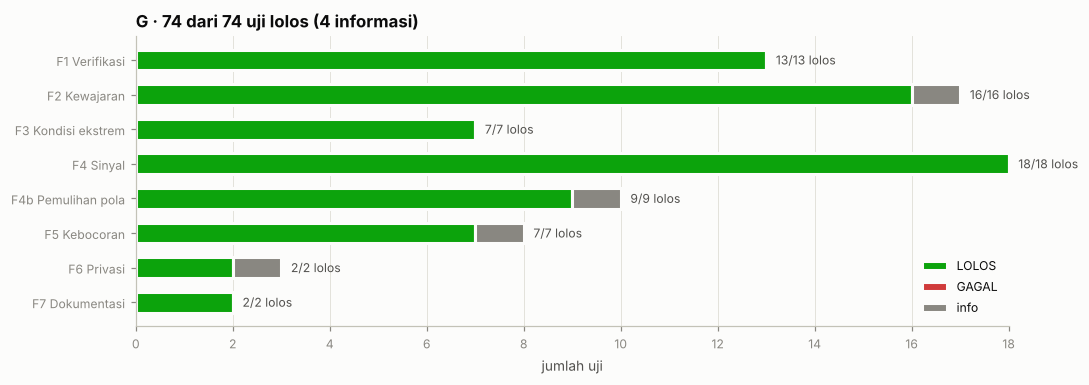

In [46]:
REPORT.mkdir(parents=True, exist_ok=True)
REP = pd.DataFrame(VAL)
REP['tautan'] = REP.rujukan.map(lambda t: ' ; '.join(ref_link(r) for r in refs_in(t)))      # tautan DOI/URL tiap rujukan
REP.to_csv(REPORT / 'validation_report.csv', index=False)
# ringkasan = 7 lapis (VAL) + F2b uji jaringan (NETDF) + F8 signifikansi (SIGDF; uji beda lolos bila lolos Bonferroni, uji kecocokan lolos bila distribusi sesuai)
sig_status = np.where(SIGDF.jenis.eq('beda'), np.where(SIGDF.lolos_bonferroni.eq(True), 'LOLOS', 'GAGAL'),
                      np.where(SIGDF.kesimpulan.eq('distribusi sesuai'), 'LOLOS', 'GAGAL'))
ALL = pd.concat([REP[['lapis', 'uji', 'nilai', 'target', 'status']],
                 NETDF.assign(lapis='F2b Uji jaringan', nilai=NETDF.observasi.round(4).astype(str))[['lapis', 'uji', 'nilai', 'target', 'status']],
                 SIGDF.assign(lapis='F8 Signifikansi', uji=SIGDF.yang_diuji, nilai=SIGDF.p_value.map(lambda p: f'p = {p:.1e}'),
                              target=np.where(SIGDF.jenis.eq('beda'), 'lolos Bonferroni', 'p ≥ 0,05 (distribusi sesuai)'), status=sig_status)[['lapis', 'uji', 'nilai', 'target', 'status']]],
                ignore_index=True)
summ = ALL.groupby(['lapis', 'status']).size().unstack(fill_value=0).reindex(columns=['LOLOS', 'GAGAL', 'info'], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(summ))
for st in ['LOLOS', 'GAGAL', 'info']:
    ax.barh(summ.index, summ[st], left=left, color=STATUS[st], height=.6, label=st, edgecolor=C['surface'], linewidth=2); left += summ[st].values
for i_, (lp, r_) in enumerate(summ.iterrows()): ax.text(left[i_] + .2, i_, f"{r_['LOLOS']}/{r_['LOLOS'] + r_['GAGAL']} lolos", va='center', fontsize=8, color=C['ink2'])
ax.invert_yaxis(); ax.set(xlabel='jumlah uji', title=f"G · {int(summ['LOLOS'].sum())} dari {int(summ['LOLOS'].sum() + summ['GAGAL'].sum())} uji lolos ({int(summ['info'].sum())} informasi)")
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False); plt.tight_layout(); save_fig('08_G_ringkasan_validasi'); plt.show()
write_datasheet(data, cfg, all_tests=ALL)                          # perbarui DATASHEET.md §7 dengan ringkasan lengkap (F2b & F8 baru selesai setelah F7)
print('GAGAL:', ALL[ALL.status.eq('GAGAL')][['lapis', 'uji', 'nilai', 'target']].to_string(index=False) if (ALL.status == 'GAGAL').any() else 'tidak ada')
summ

### Kesiapan untuk notebook berikutnya
| Notebook | Bahan yang disiapkan data ini | Dibuktikan di |
|---|---|---|
| 02 EDA | musiman per industri, MNAR, white-space, konsentrasi, efek berantai, erosi wallet share, grup usaha | F2, F4, F4b |
| 03 Feature Engineering | rasio relatif-peer, sinyal dini pembayaran, divergensi omzet–inflow, fitur graf (derajat, PageRank, komunitas, eksposur anchor, rekan grup) | F4b |
| 04–05 Modelling | label realistis (plafon < 1), label noise tercatat, kelas tidak seimbang (High ±13%), fitur keuangan saja tidak cukup | F4 |
| 06 Evaluasi | ground truth risiko prospect, anomali per jenis, kebutuhan produk, adopsi setelah cutoff, identitas counterparty | F4, F5 |
| 07 Remodelling | kesalahan rating tercatat (`label_flipped`) untuk analisis kesalahan, skenario krisis/boom untuk uji ketahanan | F3, F4 |

**Aturan untuk semua notebook berikutnya:** baca `data/raw/data_dictionary.csv` dan pakai hanya kolom berperan `fitur`; file `gt_*` hanya di bagian evaluasi.

## H. Ekspor daftar rujukan
Membuat dua file di `outputs/01_dataset_validation/`:
- `references.csv` — satu baris per rujukan: kutipan, judul, terbitan, DOI, tautan, tautan pencarian Google Scholar, status pengecekan, bagian notebook, dan **uji mana saja yang memakainya**;
- `REFERENCES.md` — catatan yang sama dalam bentuk daftar bertautan (bisa dibuka di GitHub/VS Code).

In [47]:
uji_of = {}
for v in VAL:
    for r in refs_in(v['rujukan']): uji_of.setdefault(r['id'], []).append(f"{v['lapis'].split()[0]}: {v['uji']}")
for s_ in NET:
    for r in refs_in(s_['rujukan']): uji_of.setdefault(r['id'], []).append(f"F2b: {s_['uji']}")
for s_ in SIG:
    for r in refs_in(s_['rujukan']): uji_of.setdefault(r['id'], []).append(f"F8: {s_['yang_diuji']}")
REFDF = pd.DataFrame([dict(id=r['id'], kutipan=r['kutipan'], penulis=r['penulis'], tahun=r['tahun'], judul=r['judul'], terbitan=r['terbitan'], doi=r['doi'],
                           tautan=ref_link(r), cari_di_scholar='https://scholar.google.com/scholar?q=' + quote(r['judul']), status_tautan=r['dicek'],
                           bagian_notebook=r['bagian'], dipakai_untuk=r['dipakai'], uji_terkait=' | '.join(uji_of.get(r['id'], [])),
                           jumlah_uji=len(uji_of.get(r['id'], []))) for r in REFS])
REFDF.to_csv(REPORT / 'references.csv', index=False)
lines = ['# Daftar rujukan — Notebook 01 Dataset Generation & Validation', '',
         'Dibuat otomatis oleh notebook 01. Kolom *status* menandai tautan yang sudah dibuka saat penyusunan (10 Okt 2026); sisanya cek sebelum dikutip.', '',
         '| ID | Rujukan | Tautan | Dipakai untuk | Bagian | Uji terkait | Status |', '|---|---|---|---|---|---|---|']
for r in REFDF.itertuples():
    lines.append(f"| {r.id} | {r.penulis} ({r.tahun}). *{r.judul}*. {r.terbitan}. | [{('doi:' + r.doi) if r.doi else 'tautan'}]({r.tautan}) · [Scholar]({r.cari_di_scholar}) | "
                 f"{r.dipakai_untuk} | {r.bagian_notebook} | {r.jumlah_uji} | {r.status_tautan} |")
(REPORT / 'REFERENCES.md').write_text('\n'.join(lines), encoding='utf-8')
print(f"Tersimpan: {(REPORT / 'references.csv').relative_to(PROJECT_ROOT).as_posix()} dan {(REPORT / 'REFERENCES.md').relative_to(PROJECT_ROOT).as_posix()} ({len(REFDF)} rujukan)")
REFDF[['id', 'kutipan', 'tautan', 'bagian_notebook', 'jumlah_uji', 'status_tautan']].style.hide(axis='index')

Tersimpan: outputs/01_dataset_validation/references.csv dan outputs/01_dataset_validation/REFERENCES.md (45 rujukan)


id,kutipan,tautan,bagian_notebook,jumlah_uji,status_tautan
R01,Sargent (2013),https://ideas.repec.org/a/taf/tjsmxx/v7y2013i1p12-24.html,"F (kerangka), F1, F3",11,URL ya; DOI belum
R02,Nigrini (2012),https://doi.org/10.1002/9781119203094,F2,1,belum
R03,Barabási & Albert (1999),https://doi.org/10.1126/science.286.5439.509,"D3, F2",1,belum
R04,Newman (2002),https://doi.org/10.1103/PhysRevLett.89.208701,F2,2,belum
R05,Newman (2006),https://doi.org/10.1073/pnas.0601602103,F2,2,belum
R06,Fujiwara & Aoyama (2010),https://doi.org/10.1140/epjb/e2010-00275-2,"D3, F2",1,ya
R07,"Bernard, Moxnes & Saito (2019)",https://doi.org/10.1086/700764,"D3, F2",1,ya
R08,Blondel dkk. (2008),https://doi.org/10.1088/1742-5468/2008/10/P10008,F2,2,belum
R09,Stanley dkk. (1996),https://doi.org/10.1038/379804a0,"D11, F2",1,belum
R10,Rubin (1976),https://doi.org/10.1093/biomet/63.3.581,"D8, F4",1,belum


## Daftar pustaka

Klik tautan untuk membuka artikel (DOI) atau sumbernya. ✓ = tautan sudah dibuka saat penyusunan; selain itu cek dahulu. Versi tabel: `outputs/01_dataset_validation/references.csv`.

**Kerangka validasi & data sintetis**

- Sargent, R. G. (2013). Verification and validation of simulation models. *Journal of Simulation, 7(1), 12–24*. [ideas.repec.org](https://ideas.repec.org/a/taf/tjsmxx/v7y2013i1p12-24.html) ✓ — dipakai di F (kerangka), F1, F3.
- Kaufman, S.; Rosset, S.; Perlich, C.; Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6(4), 15*. [doi:10.1145/2382577.2382579](https://doi.org/10.1145/2382577.2382579) ✓ — dipakai di F5.
- Ojala, M.; Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research, 11, 1833–1863*. [jmlr.org](https://jmlr.org/papers/v11/ojala10a.html) — dipakai di F5.
- Hanley, J. A.; McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143(1), 29–36*. [doi:10.1148/radiology.143.1.7063747](https://doi.org/10.1148/radiology.143.1.7063747) — dipakai di F5.
- Gebru, T.; Morgenstern, J.; Vecchione, B.; dkk. (2021). Datasheets for datasets. *Communications of the ACM, 64(12), 86–92*. [doi:10.1145/3458723](https://doi.org/10.1145/3458723) — dipakai di F7.
- Jordon, J.; Szpruch, L.; Houssiau, F.; dkk. (2022). Synthetic Data – what, why and how?. *arXiv:2205.03257 (Royal Society / Alan Turing Institute)*. [arxiv.org](https://arxiv.org/abs/2205.03257) — dipakai di F6.
- Alaa, A.; van Breugel, B.; Saveliev, E.; van der Schaar, M. (2022). How faithful is your synthetic data? Sample-level metrics for evaluating and auditing generative models. *ICML 2022 (PMLR 162)*. [proceedings.mlr.press](https://proceedings.mlr.press/v162/alaa22a.html) — dipakai di Datasheet §6.
- Pearl, J. (2009). Causality: Models, Reasoning, and Inference (2nd ed.). *Cambridge University Press*. [doi:10.1017/CBO9780511803161](https://doi.org/10.1017/CBO9780511803161) — dipakai di B.
- Cook, S. R.; Gelman, A.; Rubin, D. B. (2006). Validation of software for Bayesian models using posterior quantiles. *Journal of Computational and Graphical Statistics, 15(3), 675–692*. [doi:10.1198/106186006X136976](https://doi.org/10.1198/106186006X136976) — dipakai di F4b.
- Talts, S.; Betancourt, M.; Simpson, D.; Vehtari, A.; Gelman, A. (2018). Validating Bayesian inference algorithms with simulation-based calibration. *arXiv:1804.06788*. [arxiv.org](https://arxiv.org/abs/1804.06788) — dipakai di F4b.

**Statistik, data hilang & label**

- Nigrini, M. J. (2012). Benford's Law: Applications for Forensic Accounting, Auditing, and Fraud Detection. *Wiley*. [doi:10.1002/9781119203094](https://doi.org/10.1002/9781119203094) — dipakai di F2.
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63(3), 581–592*. [doi:10.1093/biomet/63.3.581](https://doi.org/10.1093/biomet/63.3.581) — dipakai di D8, F4.
- Wu, R.; Keogh, E. (2021). Current time series anomaly detection benchmarks are flawed and are creating the illusion of progress. *IEEE Transactions on Knowledge and Data Engineering*. [doi:10.1109/TKDE.2021.3112126](https://doi.org/10.1109/TKDE.2021.3112126) ✓ — dipakai di F4.
- Woo, M.-J.; Reiter, J. P.; Oganian, A.; Karr, A. F. (2009). Global measures of data utility for microdata masked for disclosure limitation. *Journal of Privacy and Confidentiality, 1(1)*. [doi:10.29012/jpc.v1i1.568](https://doi.org/10.29012/jpc.v1i1.568) ✓ — dipakai di F4.
- Snoke, J.; Raab, G. M.; Nowok, B.; Dibben, C.; Slavkovic, A. (2018). General and specific utility measures for synthetic data. *Journal of the Royal Statistical Society: Series A, 181(3), 663–688*. [doi:10.1111/rssa.12358](https://doi.org/10.1111/rssa.12358) ✓ — dipakai di F4.
- Northcutt, C. G.; Jiang, L.; Chuang, I. L. (2021). Confident learning: Estimating uncertainty in dataset labels. *Journal of Artificial Intelligence Research, 70, 1373–1411*. [doi:10.1613/jair.1.12125](https://doi.org/10.1613/jair.1.12125) ✓ — dipakai di D7, F4.
- Hill, B. M. (1975). A simple general approach to inference about the tail of a distribution. *Annals of Statistics, 3(5), 1163–1174*. [doi:10.1214/aos/1176343247](https://doi.org/10.1214/aos/1176343247) ✓ — dipakai di F2.

**Jaringan, ekonomi & keuangan**

- Barabási, A.-L.; Albert, R. (1999). Emergence of scaling in random networks. *Science, 286(5439), 509–512*. [doi:10.1126/science.286.5439.509](https://doi.org/10.1126/science.286.5439.509) — dipakai di D3, F2.
- Newman, M. E. J. (2002). Assortative mixing in networks. *Physical Review Letters, 89(20), 208701*. [doi:10.1103/PhysRevLett.89.208701](https://doi.org/10.1103/PhysRevLett.89.208701) — dipakai di F2.
- Newman, M. E. J. (2006). Modularity and community structure in networks. *PNAS, 103(23), 8577–8582*. [doi:10.1073/pnas.0601602103](https://doi.org/10.1073/pnas.0601602103) — dipakai di F2.
- Fujiwara, Y.; Aoyama, H. (2010). Large-scale structure of a nation-wide production network. *The European Physical Journal B, 77(4), 565–580*. [doi:10.1140/epjb/e2010-00275-2](https://doi.org/10.1140/epjb/e2010-00275-2) ✓ — dipakai di D3, F2.
- Bernard, A. B.; Moxnes, A.; Saito, Y. U. (2019). Production networks, geography, and firm performance. *Journal of Political Economy, 127(2), 639–688*. [doi:10.1086/700764](https://doi.org/10.1086/700764) ✓ — dipakai di D3, F2.
- Blondel, V. D.; Guillaume, J.-L.; Lambiotte, R.; Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics, P10008*. [doi:10.1088/1742-5468/2008/10/P10008](https://doi.org/10.1088/1742-5468/2008/10/P10008) — dipakai di F2.
- Watts, D. J.; Strogatz, S. H. (1998). Collective dynamics of 'small-world' networks. *Nature, 393, 440–442*. [doi:10.1038/30918](https://doi.org/10.1038/30918) — dipakai di F2b.
- Maslov, S.; Sneppen, K. (2002). Specificity and stability in topology of protein networks. *Science, 296(5569), 910–913*. [doi:10.1126/science.1065103](https://doi.org/10.1126/science.1065103) — dipakai di F2b.
- Clauset, A.; Shalizi, C. R.; Newman, M. E. J. (2009). Power-law distributions in empirical data. *SIAM Review, 51(4), 661–703*. [doi:10.1137/070710111](https://doi.org/10.1137/070710111) — dipakai di F2b.
- Danon, L.; Díaz-Guilera, A.; Duch, J.; Arenas, A. (2005). Comparing community structure identification. *Journal of Statistical Mechanics, P09008*. [doi:10.1088/1742-5468/2005/09/P09008](https://doi.org/10.1088/1742-5468/2005/09/P09008) — dipakai di F2b.
- Stanley, M. H. R.; Amaral, L. A. N.; Buldyrev, S. V.; dkk. (1996). Scaling behaviour in the growth of companies. *Nature, 379, 804–806*. [doi:10.1038/379804a0](https://doi.org/10.1038/379804a0) — dipakai di D11, F2.
- MacKinlay, A. C. (1997). Event studies in economics and finance. *Journal of Economic Literature, 35(1), 13–39*. [www.jstor.org](https://www.jstor.org/stable/2729691) — dipakai di F4b, F8.
- Battiston, S.; Puliga, M.; Kaushik, R.; Tasca, P.; Caldarelli, G. (2012). DebtRank: Too central to fail? Financial networks, the FED and systemic risk. *Scientific Reports, 2, 541*. [doi:10.1038/srep00541](https://doi.org/10.1038/srep00541) — dipakai di D4, F4b.
- Khanna, T.; Yafeh, Y. (2007). Business groups in emerging markets: Paragons or parasites?. *Journal of Economic Literature, 45(2), 331–372*. [doi:10.1257/jel.45.2.331](https://doi.org/10.1257/jel.45.2.331) — dipakai di D1, D2, F4b.

**Uji signifikansi (F8)**

- Mann, H. B.; Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *Annals of Mathematical Statistics, 18(1), 50–60*. [doi:10.1214/aoms/1177730491](https://doi.org/10.1214/aoms/1177730491) — dipakai di F5, F8.
- Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1(6), 80–83*. [doi:10.2307/3001968](https://doi.org/10.2307/3001968) — dipakai di F8.
- Cochran, W. G. (1954). Some methods for strengthening the common χ² tests. *Biometrics, 10(4), 417–451*. [doi:10.2307/3001616](https://doi.org/10.2307/3001616) — dipakai di F8.
- Armitage, P. (1955). Tests for linear trends in proportions and frequencies. *Biometrics, 11(3), 375–386*. [doi:10.2307/3001775](https://doi.org/10.2307/3001775) ✓ — dipakai di F8.
- Clopper, C. J.; Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika, 26(4), 404–413*. [doi:10.1093/biomet/26.4.404](https://doi.org/10.1093/biomet/26.4.404) — dipakai di F8.
- Benjamini, Y.; Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B, 57(1), 289–300*. [doi:10.1111/j.2517-6161.1995.tb02031.x](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x) — dipakai di F8.
- Efron, B.; Tibshirani, R. J. (1993). An Introduction to the Bootstrap. *Chapman & Hall/CRC*. [doi:10.1201/9780429246593](https://doi.org/10.1201/9780429246593) ✓ — dipakai di F8.
- Massey, F. J. (1951). The Kolmogorov–Smirnov test for goodness of fit. *Journal of the American Statistical Association, 46(253), 68–78*. [doi:10.1080/01621459.1951.10500769](https://doi.org/10.1080/01621459.1951.10500769) — dipakai di F8.
- Spearman, C. (1904). The proof and measurement of association between two things. *American Journal of Psychology, 15(1), 72–101*. [doi:10.2307/1412159](https://doi.org/10.2307/1412159) — dipakai di F2, F8.

**Regulasi & sumber data resmi**

- Republik Indonesia (2022). Undang-Undang tentang Pelindungan Data Pribadi. *Lembaran Negara RI*. [cari di Google](https://www.google.com/search?q=Undang-Undang%20tentang%20Pelindungan%20Data%20Pribadi%20Republik%20Indonesia) — dipakai di F6.
- Republik Indonesia (2021). Peraturan Pemerintah tentang Pengupahan (termasuk THR). *Lembaran Negara RI*. [cari di Google](https://www.google.com/search?q=Peraturan%20Pemerintah%20tentang%20Pengupahan%20%28termasuk%20THR%29%20Republik%20Indonesia) — dipakai di D11, F2.
- Badan Pusat Statistik (2020). Klasifikasi Baku Lapangan Usaha Indonesia 2020. *BPS*. [cari di Google](https://www.google.com/search?q=Klasifikasi%20Baku%20Lapangan%20Usaha%20Indonesia%202020%20Badan%20Pusat%20Statistik) — dipakai di C.
- Badan Pusat Statistik (2021). Tabel Input–Output Indonesia. *BPS*. [cari di Google](https://www.google.com/search?q=Tabel%20Input%E2%80%93Output%20Indonesia%20Badan%20Pusat%20Statistik) — dipakai di C, F2.
- Bank Indonesia (2024). Survei Penjualan Eceran (Indeks Penjualan Riil). *Bank Indonesia*. [cari di Google](https://www.google.com/search?q=Survei%20Penjualan%20Eceran%20%28Indeks%20Penjualan%20Riil%29%20Bank%20Indonesia) — dipakai di F2.